# SARC
## Satellite-based Intelligence & Geospatial Research

Research Focus:
- Sentinel-1 C-band SAR
- NISAR S-band SAR
- INSAT-3DR rainfall observations
- Geospatial Feature Engineering
- Machine Learning
- River and Environmental Change Analysis

Primary Event: South Lhonak GLOF — 04 October 2023
Study Region: Teesta River Basin, Sikkim

In [ ]:

# SARC — GOOGLE DRIVE INITIALIZATION

from google.colab import drive
import os

MOUNT = "/content/drive"

# Cleanly handle an existing mount or stale mount directory.
if os.path.ismount(MOUNT):
    print("Google Drive is already mounted.")
else:
    if os.path.isdir(MOUNT) and os.listdir(MOUNT):
        import shutil
        shutil.rmtree(MOUNT)

    os.makedirs(MOUNT, exist_ok=True)
    drive.mount(MOUNT)

BASE = "/content/drive/MyDrive/SARC"

if not os.path.isdir(BASE):
    raise RuntimeError("SARC project directory not accessible.")

print("Google Drive: CONNECTED")
print("SARC Project: READY")
print("Project Path:", BASE)


Google Drive is already mounted.
Google Drive: CONNECTED
SARC Project: READY
Project Path: /content/drive/MyDrive/SARC


In [ ]:
import os
import sys
import platform

print("SARC Environment Initialized")
print("Python Version:", sys.version)
print("Platform:", platform.platform())
print("Drive Connected:", os.path.exists('/content/drive/MyDrive'))

SARC Environment Initialized
Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Drive Connected: True


In [ ]:
from pathlib import Path

SARC_ROOT = Path("/content/drive/MyDrive/SARC")

folders = [
    "data/sentinel1/raw",
    "data/sentinel1/metadata",
    "data/nisar/raw",
    "data/nisar/metadata",
    "data/insat3dr/raw",
    "data/insat3dr/metadata",
    "data/dem/raw",
    "data/dem/processed",
    "data/ground_truth",
    "notebooks",
    "processed/sentinel1",
    "processed/nisar",
    "processed/insat3dr",
    "features",
    "models",
    "outputs/maps",
    "outputs/evaluation",
    "metadata",
    "logs"
]

for folder in folders:
    (SARC_ROOT / folder).mkdir(parents=True, exist_ok=True)

print("SARC folder structure created successfully!")
print("\nProject directories:")

for path in sorted(SARC_ROOT.rglob("*")):
    if path.is_dir():
        print("📁", path.relative_to(SARC_ROOT))

SARC folder structure created successfully!

Project directories:
📁 data
📁 data/dem
📁 data/dem/processed
📁 data/dem/raw
📁 data/ground_truth
📁 data/insat3dr
📁 data/insat3dr/metadata
📁 data/insat3dr/raw
📁 data/nisar
📁 data/nisar/metadata
📁 data/nisar/raw
📁 data/sentinel1
📁 data/sentinel1/metadata
📁 data/sentinel1/raw
📁 engine
📁 engine/backend
📁 engine/features
📁 engine/geojson
📁 engine/geojson/exports
📁 engine/ingestion
📁 engine/ml
📁 engine/ml/artifacts
📁 engine/preprocessing
📁 engine/spatial
📁 engine/validation
📁 features
📁 logs
📁 metadata
📁 models
📁 notebooks
📁 outputs
📁 outputs/evaluation
📁 outputs/maps
📁 outputs/maps/nisar
📁 outputs/maps/nisar/change_analysis
📁 outputs/maps/nisar/ml_analysis
📁 outputs/maps/nisar/research_package
📁 outputs/maps/nisar/temporal_variability
📁 processed
📁 processed/insat3dr
📁 processed/nisar
📁 processed/nisar/change_analysis
📁 processed/nisar/derived_features
📁 processed/nisar/ml_features
📁 processed/nisar/ml_results
📁 processed/nisar/preprocessed
📁 proce

In [ ]:
# ============================================
# SARC | PROJECT CONFIGURATION
# ============================================

SARC_CONFIG = {
    "project_name": "SARC",
    "study_event": "South Lhonak GLOF",
    "event_date": "2023-10-04",
    "study_region": "Teesta River Basin, Sikkim",

    # Candidate study area: Singtam–Majitar–Rangpo
    "aoi": {
        "north": 27.2025,
        "south": 27.1575,
        "west": 88.4897,
        "east": 88.5403
    },

    # Sentinel-1 historical event analysis
    "sentinel1": {
        "mission": "Sentinel-1A",
        "frequency_band": "C-band",
        "product_type": "GRD",
        "polarizations": ["VV", "VH"],
        "pre_event_window": ["2023-09-25", "2023-09-30"],
        "post_event_window": ["2023-10-05", "2023-10-12"]
    },

    # NISAR later-condition observations
    "nisar": {
        "mission": "NISAR",
        "frequency_band": "S-band",
        "product_type": "GCOV",
        "polarizations": ["HH", "HV"],
        "candidate_dates": [
            "2026-08-24",
            "2026-09-05",
            "2026-09-29"
        ]
    },

    "crs": "EPSG:4326",
    "analysis_status": "Research pipeline development"
}

print("SARC Configuration Loaded Successfully")
print("-" * 45)

for key, value in SARC_CONFIG.items():
    print(f"\n{key}: {value}")

SARC Configuration Loaded Successfully
---------------------------------------------

project_name: SARC

study_event: South Lhonak GLOF

event_date: 2023-10-04

study_region: Teesta River Basin, Sikkim

aoi: {'north': 27.2025, 'south': 27.1575, 'west': 88.4897, 'east': 88.5403}

sentinel1: {'mission': 'Sentinel-1A', 'frequency_band': 'C-band', 'product_type': 'GRD', 'polarizations': ['VV', 'VH'], 'pre_event_window': ['2023-09-25', '2023-09-30'], 'post_event_window': ['2023-10-05', '2023-10-12']}

nisar: {'mission': 'NISAR', 'frequency_band': 'S-band', 'product_type': 'GCOV', 'polarizations': ['HH', 'HV'], 'candidate_dates': ['2026-08-24', '2026-09-05', '2026-09-29']}

crs: EPSG:4326

analysis_status: Research pipeline development


In [ ]:
import json

CONFIG_PATH = SARC_ROOT / "metadata" / "sarc_config.json"

with open(CONFIG_PATH, "w") as file:
    json.dump(SARC_CONFIG, file, indent=4)

print("Configuration saved successfully!")
print("File location:", CONFIG_PATH)

# Verify saved configuration
with open(CONFIG_PATH, "r") as file:
    SAVED_CONFIG = json.load(file)

print("\nVerification:", "PASSED" if SAVED_CONFIG == SARC_CONFIG else "FAILED")

Configuration saved successfully!
File location: /content/drive/MyDrive/SARC/metadata/sarc_config.json

Verification: PASSED


In [ ]:
import json
import sys
import platform
from pathlib import Path

print("=" * 60)
print("             SARC | PROJECT SYSTEM AUDIT")
print("=" * 60)

# 1. Google Drive
drive_ok = Path("/content/drive/MyDrive").exists()
print(f"\n[{'PASS' if drive_ok else 'FAIL'}] Google Drive connection")

# 2. Project root
root_ok = SARC_ROOT.exists()
print(f"[{'PASS' if root_ok else 'FAIL'}] SARC project root")

# 3. Directory structure
required_folders = [
    "data/sentinel1/raw",
    "data/sentinel1/metadata",
    "data/nisar/raw",
    "data/nisar/metadata",
    "data/insat3dr/raw",
    "data/insat3dr/metadata",
    "data/dem/raw",
    "data/dem/processed",
    "data/ground_truth",
    "notebooks",
    "processed/sentinel1",
    "processed/nisar",
    "processed/insat3dr",
    "features",
    "models",
    "outputs/maps",
    "outputs/evaluation",
    "metadata",
    "logs"
]

missing = [f for f in required_folders if not (SARC_ROOT / f).is_dir()]

print(f"[{'PASS' if not missing else 'FAIL'}] Directory structure ({len(required_folders)-len(missing)}/{len(required_folders)})")

if missing:
    print("Missing folders:", missing)

# 4. Configuration file
config_path = SARC_ROOT / "metadata" / "sarc_config.json"

try:
    with open(config_path, "r") as f:
        saved_config = json.load(f)
    config_ok = saved_config == SARC_CONFIG
except Exception as e:
    config_ok = False
    print("Configuration error:", e)

print(f"[{'PASS' if config_ok else 'FAIL'}] Configuration JSON integrity")

# 5. AOI validation
aoi = SARC_CONFIG["aoi"]

aoi_ok = (
    -90 <= aoi["south"] < aoi["north"] <= 90
    and -180 <= aoi["west"] < aoi["east"] <= 180
)

print(f"[{'PASS' if aoi_ok else 'FAIL'}] AOI coordinate validity")

# 6. Satellite configuration
s1_ok = (
    SARC_CONFIG["sentinel1"]["product_type"] == "GRD"
    and set(SARC_CONFIG["sentinel1"]["polarizations"]) == {"VV", "VH"}
)

nisar_ok = (
    SARC_CONFIG["nisar"]["product_type"] == "GCOV"
    and set(SARC_CONFIG["nisar"]["polarizations"]) == {"HH", "HV"}
)

print(f"[{'PASS' if s1_ok else 'FAIL'}] Sentinel-1 configuration")
print(f"[{'PASS' if nisar_ok else 'FAIL'}] NISAR configuration")

# 7. Runtime
print("\n--- Runtime Information ---")
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())

# 8. Final result
checks = [
    drive_ok,
    root_ok,
    not missing,
    config_ok,
    aoi_ok,
    s1_ok,
    nisar_ok
]

print("\n" + "=" * 60)
print(f"SYSTEM AUDIT: {sum(checks)}/{len(checks)} CHECKS PASSED")

if all(checks):
    print("SARC BASE SETUP: READY")
else:
    print("SARC BASE SETUP: ATTENTION REQUIRED")

print("=" * 60)

             SARC | PROJECT SYSTEM AUDIT

[PASS] Google Drive connection
[PASS] SARC project root
[PASS] Directory structure (19/19)
[PASS] Configuration JSON integrity
[PASS] AOI coordinate validity
[PASS] Sentinel-1 configuration
[PASS] NISAR configuration

--- Runtime Information ---
Python: 3.13.16
Platform: Linux-6.6.159+-x86_64-with-glibc2.39

SYSTEM AUDIT: 7/7 CHECKS PASSED
SARC BASE SETUP: READY


In [ ]:
import importlib
import sys

# Core libraries required for SARC
REQUIRED_LIBRARIES = {
    "numpy": "Numerical computing",
    "pandas": "Tabular data processing",
    "matplotlib": "Visualization",
    "rasterio": "Raster geospatial processing",
    "geopandas": "Vector geospatial processing",
    "shapely": "Geometric operations",
    "pyproj": "Coordinate transformations",
    "rioxarray": "Geospatial raster analysis",
    "xarray": "Multidimensional data",
    "h5py": "NISAR HDF5 inspection",
    "scipy": "Scientific computing",
    "sklearn": "Machine learning"
}

print("SARC | GEOSPATIAL LIBRARY AUDIT")
print("-" * 55)
print("Python Version:", sys.version.split()[0])
print("-" * 55)

installed = []
missing = []

for package, purpose in REQUIRED_LIBRARIES.items():
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "Version unavailable")
        print(f"[OK] {package:<15} | {version}")
        installed.append(package)
    except Exception as error:
        print(f"[MISSING] {package:<15} | {purpose}")
        missing.append(package)

print("-" * 55)
print("Installed:", len(installed))
print("Missing:", len(missing))
print("Missing packages:", missing)

SARC | GEOSPATIAL LIBRARY AUDIT
-------------------------------------------------------
Python Version: 3.13.16
-------------------------------------------------------
[OK] numpy           | 2.4.6
[OK] pandas          | 2.2.3
[OK] matplotlib      | 3.10.0
[OK] rasterio        | 1.5.2
[OK] geopandas       | 1.2.0
[OK] shapely         | 2.2.0
[OK] pyproj          | 3.8.0
[MISSING] rioxarray       | Geospatial raster analysis
[OK] xarray          | 2025.12.0
[OK] h5py            | 3.14.0
[OK] scipy           | 1.16.3
[OK] sklearn         | 1.6.1
-------------------------------------------------------
Installed: 11
Missing: 1
Missing packages: ['rioxarray']


In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline

import matplotlib.pyplot as plt

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("SARC ML ENGINE INITIALIZED")
print("-" * 45)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("ML Framework: Scikit-learn")
print("Model: Random Forest")
print("Random State:", RANDOM_STATE)
print("\nDevelopment mode: Synthetic feature testing")
print("Real satellite training: Pending data ingestion")

SARC ML ENGINE INITIALIZED
---------------------------------------------
NumPy: 2.4.6
Pandas: 2.2.3
ML Framework: Scikit-learn
Model: Random Forest
Random State: 42

Development mode: Synthetic feature testing
Real satellite training: Pending data ingestion


In [ ]:
from pathlib import Path

ENGINE_ROOT = SARC_ROOT / "engine"

engine_modules = [
    "ingestion",
    "preprocessing",
    "features",
    "ml",
    "spatial",
    "geojson",
    "backend",
    "validation"
]

for module in engine_modules:
    (ENGINE_ROOT / module).mkdir(parents=True, exist_ok=True)

# Central model and output locations
MODEL_ROOT = ENGINE_ROOT / "ml" / "artifacts"
GEOJSON_ROOT = ENGINE_ROOT / "geojson" / "exports"
MODEL_ROOT.mkdir(parents=True, exist_ok=True)
GEOJSON_ROOT.mkdir(parents=True, exist_ok=True)

print("SARC GEOAI ENGINE INITIALIZED")
print("-" * 45)

for path in sorted(ENGINE_ROOT.rglob("*")):
    if path.is_dir():
        print("📁", path.relative_to(SARC_ROOT))

print("\nModel storage:", MODEL_ROOT)
print("GeoJSON exports:", GEOJSON_ROOT)

SARC GEOAI ENGINE INITIALIZED
---------------------------------------------
📁 engine/backend
📁 engine/features
📁 engine/geojson
📁 engine/geojson/exports
📁 engine/ingestion
📁 engine/ml
📁 engine/ml/artifacts
📁 engine/preprocessing
📁 engine/spatial
📁 engine/validation

Model storage: /content/drive/MyDrive/SARC/engine/ml/artifacts
GeoJSON exports: /content/drive/MyDrive/SARC/engine/geojson/exports


In [ ]:
import json
from datetime import datetime, timezone

DATA_REGISTRY = {
    "project": "SARC",
    "created_at": datetime.now(timezone.utc).isoformat(),
    "datasets": {
        "sentinel1_pre_event": {
            "sensor": "Sentinel-1",
            "period": "2023-09-25 to 2023-09-30",
            "status": "PENDING",
            "path": "data/sentinel1/raw",
            "source": "ASF DAAC / Copernicus Data Space"
        },
        "sentinel1_post_event": {
            "sensor": "Sentinel-1",
            "period": "2023-10-05 to 2023-10-12",
            "status": "PENDING",
            "path": "data/sentinel1/raw",
            "source": "ASF DAAC / Copernicus Data Space"
        },
        "nisar": {
            "sensor": "NISAR S-band",
            "period": "2026-08-24 to 2026-09-29",
            "status": "PREPROCESSING",
            "path": "data/nisar/raw",
            "source": "NISAR GCOV"
        },
        "insat3dr": {
            "sensor": "INSAT-3DR",
            "period": "2023-10-01 to 2023-10-07",
            "status": "PENDING",
            "path": "data/insat3dr/raw",
            "source": "MOSDAC MDAPI",
            "dataset_id": None
        },
        "dem": {
            "sensor": "CartoDEM / DEM alternative",
            "period": "Static",
            "status": "PENDING",
            "path": "data/dem/raw",
            "source": "Bhuvan / Copernicus DEM / SRTM"
        },
        "ground_truth": {
            "sensor": "Independent reference data",
            "period": "2023 event",
            "status": "PENDING",
            "path": "data/ground_truth",
            "source": "To be established"
        }
    }
}

REGISTRY_PATH = SARC_ROOT / "metadata" / "data_registry.json"

with open(REGISTRY_PATH, "w") as f:
    json.dump(DATA_REGISTRY, f, indent=4)

print("SARC DATA REGISTRY INITIALIZED")
print("-" * 50)

for name, details in DATA_REGISTRY["datasets"].items():
    print(f"{name:<24} | {details['status']}")

print("-" * 50)
print("Registry:", REGISTRY_PATH)

SARC DATA REGISTRY INITIALIZED
--------------------------------------------------
sentinel1_pre_event      | PENDING
sentinel1_post_event     | PENDING
nisar                    | PREPROCESSING
insat3dr                 | PENDING
dem                      | PENDING
ground_truth             | PENDING
--------------------------------------------------
Registry: /content/drive/MyDrive/SARC/metadata/data_registry.json


In [ ]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")

print("Searching NISAR HDF5 files in MyDrive...")

nisar_files = []

for file in DRIVE_ROOT.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".h5", ".hdf5"]:
        nisar_files.append(file)

print("\nNISAR / HDF5 FILES FOUND:")
print("-" * 55)

for i, file in enumerate(nisar_files, 1):
    size_gb = file.stat().st_size / (1024**3)
    print(f"{i}. {file.name}")
    print(f"   Size: {size_gb:.2f} GB")
    print(f"   Path: {file}")

Searching NISAR HDF5 files in MyDrive...

NISAR / HDF5 FILES FOUND:
-------------------------------------------------------
1. NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5
   Size: 11.73 GB
   Path: /content/drive/MyDrive/SARC/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5
2. NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5
   Size: 11.73 GB
   Path: /content/drive/MyDrive/SARC/NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5
3. NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5
   Size: 11.75 GB
   Path: /content/drive/MyDrive/SARC/NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5


In [ ]:
import h5py
import numpy as np

def read_value(f, path):
    value = f[path][()]

    if isinstance(value, bytes):
        return value.decode(errors="replace")

    if isinstance(value, np.ndarray) and value.dtype.kind == "S":
        return [x.decode(errors="replace") for x in value]

    return value

for file_path in nisar_files:

    print("\n" + "=" * 75)
    print("SCENE:", file_path.name)
    print("=" * 75)

    with h5py.File(file_path, "r") as f:

        base = "/science/SSAR/GCOV/grids/frequencyA"

        x = f[f"{base}/xCoordinates"][:]
        y = f[f"{base}/yCoordinates"][:]

        print("\n--- SPATIAL GRID ---")
        print("Raster shape:", f[f"{base}/HHHH"].shape)
        print("X range:", float(x.min()), "to", float(x.max()))
        print("Y range:", float(y.min()), "to", float(y.max()))
        print("X first/last:", x[0], x[-1])
        print("Y first/last:", y[0], y[-1])
        print("X spacing:", read_value(f, f"{base}/xCoordinateSpacing"))
        print("Y spacing:", read_value(f, f"{base}/yCoordinateSpacing"))

        print("\n--- PROJECTION ---")
        print("EPSG / projection code:",
              read_value(f, f"{base}/projection"))

        print("\n--- SCENE IDENTIFICATION ---")
        ident = "/science/SSAR/identification"

        for key in [
            "productType",
            "radarBand",
            "trackNumber",
            "frameNumber",
            "orbitPassDirection",
            "lookDirection",
            "isGeocoded",
            "zeroDopplerStartTime",
            "zeroDopplerEndTime"
        ]:
            print(f"{key}:",
                  read_value(f, f"{ident}/{key}"))

        print("\n--- PRODUCT FOOTPRINT ---")
        for path in [
            "/science/SSAR/identification/boundingPolygon",
            "/science/SSAR/GCOV/metadata/ceosAnalysisReadyData/boundingBox"
        ]:
            if path in f:
                print(path.split("/")[-1], ":", read_value(f, path))

        print("\n--- PROCESSING FLAGS ---")
        params = "/science/SSAR/GCOV/metadata/processingInformation/parameters"

        for key in [
            "radiometricTerrainCorrectionApplied",
            "noiseCorrectionApplied",
            "postProcessingFilteringApplied",
            "shadowMaskingApplied",
            "rfiMitigationApplied"
        ]:
            path = f"{params}/{key}"
            if path in f:
                print(f"{key}: {read_value(f, path)}")


SCENE: NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5

--- SPATIAL GRID ---
Raster shape: (33408, 34488)
X range: 392405.0 to 737275.0
Y range: 2790725.0 to 3124795.0
X first/last: 392405.0 737275.0
Y first/last: 3124795.0 2790725.0
X spacing: 10.0
Y spacing: -10.0

--- PROJECTION ---
EPSG / projection code: 32645

--- SCENE IDENTIFICATION ---
productType: GCOV
radarBand: S
trackNumber: 170
frameNumber: 15
orbitPassDirection: Ascending
lookDirection: Left
isGeocoded: True
zeroDopplerStartTime: 2026-09-29T23:30:24.33214235
zeroDopplerEndTime: 2026-09-29T23:31:01.08016872

--- PRODUCT FOOTPRINT ---
boundingPolygon : POLYGON ((86.09695500 27.50847000 782.87455039,88.46394700 28.10003900 5132.17827023,89.18251800 25.94333500 -14.30368447,86.79181300 25.34949300 -27.71937913,86.09695500 27.50847000 782.87455039))
boundingBox : LINEARRING (392400.00000000 3124800.00000000 0.00000000,392400.00000000 2790710.00000000 0.00000000,2790710.00000000 

In [ ]:
import h5py
import numpy as np
from pyproj import Transformer

# SARC AOI in EPSG:4326
AOI = {
    "west": 88.4897,
    "south": 27.1575,
    "east": 88.5403,
    "north": 27.2025
}

# Transform AOI bounds to NISAR's projected CRS
transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:32645", always_xy=True
)

xmin, ymin, xmax, ymax = transformer.transform_bounds(
    AOI["west"], AOI["south"],
    AOI["east"], AOI["north"],
    densify_pts=21
)

print("AOI projected bounds:")
print(xmin, ymin, xmax, ymax)

SARC_AOI_WINDOW = {}

for file_path in nisar_files:

    with h5py.File(file_path, "r") as f:

        base = "/science/SSAR/GCOV/grids/frequencyA"

        x = f[f"{base}/xCoordinates"][:]
        y = f[f"{base}/yCoordinates"][:]

        cols = np.flatnonzero((x >= xmin) & (x <= xmax))
        rows = np.flatnonzero((y >= ymin) & (y <= ymax))

        if len(cols) == 0 or len(rows) == 0:
            print("\nAOI NOT FOUND:", file_path.name)
            continue

        # Add 2-pixel safety margin
        row_start = max(0, rows.min() - 2)
        row_stop = min(len(y), rows.max() + 3)

        col_start = max(0, cols.min() - 2)
        col_stop = min(len(x), cols.max() + 3)

        SARC_AOI_WINDOW[file_path.name] = {
            "row_start": int(row_start),
            "row_stop": int(row_stop),
            "col_start": int(col_start),
            "col_stop": int(col_stop)
        }

        print("\nSCENE:", file_path.name)
        print("Row window:", row_start, "to", row_stop)
        print("Column window:", col_start, "to", col_stop)
        print("Subset shape:", (
            row_stop - row_start,
            col_stop - col_start
        ))

AOI projected bounds:
647544.9448484166 3004755.9844396478 652618.4715711544 3009801.865194938

SCENE: NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5
Row window: 11498 to 12006
Column window: 25512 to 26024
Subset shape: (np.int64(508), np.int64(512))

SCENE: NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5
Row window: 11498 to 12006
Column window: 25512 to 26024
Subset shape: (np.int64(508), np.int64(512))

SCENE: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5
Row window: 11498 to 12006
Column window: 25512 to 26024
Subset shape: (np.int64(508), np.int64(512))


In [ ]:
import os
import h5py
import numpy as np
import rasterio
from rasterio.transform import from_origin

OUTPUT_DIR = "/content/drive/MyDrive/SARC/processed/nisar"
os.makedirs(OUTPUT_DIR, exist_ok=True)

BASE = "/science/SSAR/GCOV/grids/frequencyA"

for file_path in nisar_files:

    scene_name = file_path.stem
    window = SARC_AOI_WINDOW[file_path.name]

    r0, r1 = window["row_start"], window["row_stop"]
    c0, c1 = window["col_start"], window["col_stop"]

    with h5py.File(file_path, "r") as f:

        x = f[f"{BASE}/xCoordinates"]
        y = f[f"{BASE}/yCoordinates"]

        # Pixel-center coordinates
        x0 = float(x[c0])
        y0 = float(y[r0])

        dx = float(f[f"{BASE}/xCoordinateSpacing"][()])
        dy = float(f[f"{BASE}/yCoordinateSpacing"][()])

        transform = from_origin(
            x0 - dx / 2,
            y0 + abs(dy) / 2,
            dx,
            abs(dy)
        )

        layers = [
            "HHHH",
            "HHHV",
            "HVHV",
            "mask",
            "inputDataExceptionMask",
            "numberOfLooks"
        ]

        for layer in layers:

            dataset = f[f"{BASE}/{layer}"]
            subset = dataset[r0:r1, c0:c1]

            output_path = os.path.join(
                OUTPUT_DIR,
                f"{scene_name}_{layer}.tif"
            )

            profile = {
                "driver": "GTiff",
                "height": subset.shape[0],
                "width": subset.shape[1],
                "count": 1,
                "dtype": subset.dtype,
                "crs": "EPSG:32645",
                "transform": transform,
                "compress": "deflate"
            }

            with rasterio.open(output_path, "w", **profile) as dst:
                dst.write(subset, 1)

            print("Saved:", layer, "->", output_path)

print("\nAOI SUBSET EXTRACTION COMPLETE")

Saved: HHHH -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_HHHH.tif
Saved: HHHV -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_HHHV.tif
Saved: HVHV -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_HVHV.tif
Saved: mask -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_mask.tif
Saved: inputDataExceptionMask -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_inputDataExceptionMask.tif
Saved: numberOfLooks -> /content/drive/MyDrive/SARC/processed/nisar/NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001_numb

In [ ]:
import os
import numpy as np
import rasterio

OUTPUT_DIR = "/content/drive/MyDrive/SARC/processed/nisar"

LAYERS = [
    "HHHH",
    "HHHV",
    "HVHV",
    "mask",
    "inputDataExceptionMask",
    "numberOfLooks"
]

for file_path in nisar_files:
    scene_name = file_path.stem

    print("\n" + "="*75)
    print("SCENE:", scene_name)
    print("="*75)

    for layer in LAYERS:
        tif_path = os.path.join(
            OUTPUT_DIR, f"{scene_name}_{layer}.tif"
        )

        with rasterio.open(tif_path) as src:
            arr = src.read(1)
            print(f"\n--- {layer} ---")
            print("Shape:", arr.shape)
            print("CRS:", src.crs)
            print("Data type:", arr.dtype)

            if layer in ["mask", "inputDataExceptionMask"]:
                values, counts = np.unique(
                    arr, return_counts=True
                )
                print("Unique values and pixel counts:")
                for value, count in zip(values, counts):
                    print(f"  {value}: {count}")

            elif np.iscomplexobj(arr):
                valid = np.isfinite(arr.real) & np.isfinite(arr.imag)
                magnitude = np.abs(arr[valid])

                print("Finite pixels:", int(valid.sum()))
                print("Magnitude min/max:",
                      float(magnitude.min()),
                      float(magnitude.max()))
                print("Real min/max:",
                      float(arr.real[valid].min()),
                      float(arr.real[valid].max()))
                print("Imaginary min/max:",
                      float(arr.imag[valid].min()),
                      float(arr.imag[valid].max()))

            else:
                valid = np.isfinite(arr)
                values = arr[valid]

                print("Finite pixels:", int(valid.sum()))
                print("NaN/Inf pixels:", int(arr.size - valid.sum()))

                if values.size:
                    print("Min:", float(values.min()))
                    print("Max:", float(values.max()))
                    print("Mean:", float(values.mean()))
                    print("Percentiles [1, 5, 50, 95, 99]:",
                          np.percentile(
                              values, [1, 5, 50, 95, 99]
                          ).round(4).tolist())
                    print("Zero pixels:", int(np.count_nonzero(values == 0)))
                    print("Negative pixels:", int(np.count_nonzero(values < 0)))

print("\nAUDIT COMPLETE")


SCENE: NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001

--- HHHH ---
Shape: (508, 512)
CRS: EPSG:32645
Data type: float32
Finite pixels: 260096
NaN/Inf pixels: 0
Min: 0.0005621910095214844
Max: 192.00233459472656
Mean: 0.2004496306180954
Percentiles [1, 5, 50, 95, 99]: [0.012, 0.0259, 0.1186, 0.5435, 1.3989]
Zero pixels: 0
Negative pixels: 0

--- HHHV ---
Shape: (508, 512)
CRS: EPSG:32645
Data type: complex64
Finite pixels: 260096
Magnitude min/max: 4.15532776969485e-05 10.1458158493042
Real min/max: -7.8690314292907715 7.711948394775391
Imaginary min/max: -8.386881828308105 6.592679977416992

--- HVHV ---
Shape: (508, 512)
CRS: EPSG:32645
Data type: float32
Finite pixels: 260096
NaN/Inf pixels: 0
Min: 0.00011090514453826472
Max: 10.592348098754883
Mean: 0.06296862661838531
Percentiles [1, 5, 50, 95, 99]: [0.0044, 0.0092, 0.0423, 0.1676, 0.3672]
Zero pixels: 0
Negative pixels: 0

--- mask ---
Shape: (508, 512)
CRS: EPSG:32645
Data type: uint

In [ ]:
for filename, window in SARC_AOI_WINDOW.items():
    print("\nScene:", filename)
    print("Window type:", type(window))
    print("Window content:", repr(window))


Scene: NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5
Window type: <class 'dict'>
Window content: {'row_start': 11498, 'row_stop': 12006, 'col_start': 25512, 'col_stop': 26024}

Scene: NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5
Window type: <class 'dict'>
Window content: {'row_start': 11498, 'row_stop': 12006, 'col_start': 25512, 'col_stop': 26024}

Scene: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5
Window type: <class 'dict'>
Window content: {'row_start': 11498, 'row_stop': 12006, 'col_start': 25512, 'col_stop': 26024}


In [ ]:
import h5py
import numpy as np

BASE = "/science/SSAR/GCOV/grids/frequencyA"

for file_path in nisar_files:

    print("\n" + "="*65)
    print("SCENE:", file_path.name)
    print("="*65)

    window = SARC_AOI_WINDOW[file_path.name]

    r0 = int(window["row_start"])
    r1 = int(window["row_stop"])
    c0 = int(window["col_start"])
    c1 = int(window["col_stop"])

    with h5py.File(file_path, "r") as f:

        ds = f[f"{BASE}/rtcGammaToSigmaFactor"]
        factor = ds[r0:r1, c0:c1]

        valid = np.isfinite(factor) & (factor > 0)

        print("AOI shape:", factor.shape)
        print("Valid factor pixels:", int(valid.sum()))
        print("Invalid factor pixels:", int((~valid).sum()))

        if valid.any():
            print("Min:", float(factor[valid].min()))
            print("Max:", float(factor[valid].max()))
            print("Mean:", float(factor[valid].mean()))
            print("Median:", float(np.median(factor[valid])))

        print("Conversion metadata:")
        print("Description:", ds.attrs.get("description"))
        print("Units:", ds.attrs.get("units"))

print("\nFINAL VERIFICATION COMPLETE")


SCENE: NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5
AOI shape: (508, 512)
Valid factor pixels: 260096
Invalid factor pixels: 0
Min: 0.010595543310046196
Max: 37.55424499511719
Mean: 0.8084932565689087
Median: 0.7408543825149536
Conversion metadata:
Description: b'Radiometric terrain correction factor to normalize GCOV terms from gamma0 to sigma0'
Units: b'1'

SCENE: NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5
AOI shape: (508, 512)
Valid factor pixels: 260096
Invalid factor pixels: 0
Min: 0.006374955177307129
Max: 35.506046295166016
Mean: 0.7975438833236694
Median: 0.7297420501708984
Conversion metadata:
Description: b'Radiometric terrain correction factor to normalize GCOV terms from gamma0 to sigma0'
Units: b'1'

SCENE: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5
AOI shape: (508, 512)
Valid factor pixels: 260096
Invalid factor pixels:

In [ ]:
def short_date(scene):
    match = re.search(r"(202\d{5})", scene)

    if not match:
        return scene

    return datetime.strptime(
        match.group(1), "%Y%m%d"
    ).strftime("%d %b %Y")

In [ ]:

import os
import re
import json
import h5py
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from rasterio.transform import from_origin

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = "/science/SSAR/GCOV/grids/frequencyA"

OUT_DIR = "/content/drive/MyDrive/SARC/processed/nisar/preprocessed"
MAP_DIR = "/content/drive/MyDrive/SARC/outputs/maps/nisar"
META_DIR = "/content/drive/MyDrive/SARC/metadata"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MAP_DIR, exist_ok=True)
os.makedirs(META_DIR, exist_ok=True)

NODATA = -9999.0

# ============================================================
# 2. OUTPUT WRITER
# ============================================================

def save_raster(path, array, transform, crs, dtype="float32",
                nodata=NODATA):

    array = np.asarray(array)

    if dtype == "float32":
        output = np.where(
            np.isfinite(array), array, nodata
        ).astype("float32")
    else:
        output = array.astype(dtype)

    profile = {
        "driver": "GTiff",
        "height": output.shape[0],
        "width": output.shape[1],
        "count": 1,
        "dtype": dtype,
        "crs": crs,
        "transform": transform,
        "compress": "deflate",
        "predictor": 3 if dtype == "float32" else 2,
        "nodata": nodata if dtype == "float32" else None
    }

    with rasterio.open(path, "w", **profile) as dst:
        dst.write(output, 1)

# ============================================================
# 3. PROCESS ALL THREE SCENES
# ============================================================

scene_results = {}
qa_records = []

for file_path in nisar_files:

    scene_name = file_path.stem
    date_match = re.search(r"_(202\d{4})(?:T|_)", scene_name)
    scene_date = date_match.group(1) if date_match else scene_name

    print("\n" + "=" * 75)
    print("PROCESSING:", scene_date)
    print("=" * 75)

    window = SARC_AOI_WINDOW[file_path.name]

    r0 = int(window["row_start"])
    r1 = int(window["row_stop"])
    c0 = int(window["col_start"])
    c1 = int(window["col_stop"])

    # --------------------------------------------------------
    # Read AOI directly from original HDF5
    # --------------------------------------------------------

    with h5py.File(file_path, "r") as f:

        hhhh = f[f"{BASE}/HHHH"][r0:r1, c0:c1]
        hvhv = f[f"{BASE}/HVHV"][r0:r1, c0:c1]
        hhhv = f[f"{BASE}/HHHV"][r0:r1, c0:c1]

        quality_mask = f[f"{BASE}/mask"][r0:r1, c0:c1]
        exception_mask = f[
            f"{BASE}/inputDataExceptionMask"
        ][r0:r1, c0:c1]

        looks = f[f"{BASE}/numberOfLooks"][r0:r1, c0:c1]
        factor = f[
            f"{BASE}/rtcGammaToSigmaFactor"
        ][r0:r1, c0:c1]

        x0 = float(f[f"{BASE}/xCoordinates"][c0])
        y0 = float(f[f"{BASE}/yCoordinates"][r0])

        dx = float(f[f"{BASE}/xCoordinateSpacing"][()])
        dy = float(f[f"{BASE}/yCoordinateSpacing"][()])

        transform = from_origin(
            x0 - dx / 2,
            y0 + abs(dy) / 2,
            abs(dx),
            abs(dy)
        )

        projection = f[f"{BASE}/projection"]
        crs_code = int(projection.attrs.get("epsg_code", 32645))

    crs = f"EPSG:{crs_code}"

    # --------------------------------------------------------
    # Quality mask
    # --------------------------------------------------------

    valid = (
        (quality_mask > 0) &
        (quality_mask != 255) &
        (exception_mask == 0) &
        np.isfinite(looks) &
        (looks > 0) &
        np.isfinite(factor) &
        (factor > 0) &
        np.isfinite(hhhh) &
        np.isfinite(hvhv) &
        np.isfinite(hhhv.real) &
        np.isfinite(hhhv.imag) &
        (hhhh > 0) &
        (hvhv > 0)
    )

    valid_count = int(valid.sum())
    total_count = int(valid.size)

    if valid_count == 0:
        raise ValueError(f"No valid pixels in scene: {scene_date}")

    print("AOI shape:", valid.shape)
    print("Valid pixels:", valid_count)
    print("Rejected pixels:", total_count - valid_count)
    print("Valid coverage (%):", round(valid_count / total_count * 100, 3))

    # --------------------------------------------------------
    # Gamma0 and Sigma0
    # --------------------------------------------------------

    gamma_hh = np.where(valid, hhhh, np.nan)
    gamma_hv = np.where(valid, hvhv, np.nan)

    sigma_hh = np.where(valid, hhhh * factor, np.nan)
    sigma_hv = np.where(valid, hvhv * factor, np.nan)

    # Complex covariance: preserve real and imaginary parts
    sigma_hhv = np.where(valid, hhhv * factor, np.nan + 1j * np.nan)

    # --------------------------------------------------------
    # dB conversion
    # --------------------------------------------------------

    gamma_hh_db = 10 * np.log10(gamma_hh)
    gamma_hv_db = 10 * np.log10(gamma_hv)

    sigma_hh_db = 10 * np.log10(sigma_hh)
    sigma_hv_db = 10 * np.log10(sigma_hv)

    # --------------------------------------------------------
    # Polarimetric features
    # --------------------------------------------------------

    # HH / HV power ratio
    hh_hv_ratio = np.where(
        valid, sigma_hh / sigma_hv, np.nan
    )

    hh_hv_ratio_db = 10 * np.log10(hh_hv_ratio)

    # Normalized complex cross-covariance
    denominator = np.sqrt(sigma_hh * sigma_hv)

    normalized_cross_covariance = np.divide(
        sigma_hhv,
        denominator,
        out=np.full(
            hhhv.shape, np.nan + 1j * np.nan,
            dtype=np.complex64
        ),
        where=valid & (denominator > 0)
    )

    cross_covariance_magnitude = np.abs(
        normalized_cross_covariance
    )

    cross_covariance_phase = np.angle(
        normalized_cross_covariance
    )

    # --------------------------------------------------------
    # Export raster layers
    # --------------------------------------------------------

    layers = {
        "Gamma0_HH": gamma_hh,
        "Gamma0_HV": gamma_hv,
        "Sigma0_HH": sigma_hh,
        "Sigma0_HV": sigma_hv,
        "Gamma0_HH_dB": gamma_hh_db,
        "Gamma0_HV_dB": gamma_hv_db,
        "Sigma0_HH_dB": sigma_hh_db,
        "Sigma0_HV_dB": sigma_hv_db,
        "HH_HV_Ratio": hh_hv_ratio,
        "HH_HV_Ratio_dB": hh_hv_ratio_db,
        "Normalized_CrossCov_Magnitude": cross_covariance_magnitude,
        "Normalized_CrossCov_Phase_rad": cross_covariance_phase,
        "HHHV_Sigma0_Real": sigma_hhv.real,
        "HHHV_Sigma0_Imag": sigma_hhv.imag
    }

    for layer_name, array in layers.items():

        output_path = os.path.join(
            OUT_DIR,
            f"{scene_date}_{layer_name}.tif"
        )

        save_raster(
            output_path,
            array,
            transform,
            crs
        )

    # Export binary valid-data mask
    save_raster(
        os.path.join(OUT_DIR, f"{scene_date}_ValidMask.tif"),
        valid.astype("uint8"),
        transform,
        crs,
        dtype="uint8",
        nodata=255
    )

    # --------------------------------------------------------
    # QA statistics
    # --------------------------------------------------------

    for layer_name, array in layers.items():

        values = np.asarray(array)[valid]
        values = values[np.isfinite(values)]

        if values.size == 0:
            continue

        qa_records.append({
            "date": scene_date,
            "layer": layer_name,
            "valid_pixels": int(values.size),
            "min": float(np.min(values)),
            "max": float(np.max(values)),
            "mean": float(np.mean(values)),
            "median": float(np.median(values)),
            "p5": float(np.percentile(values, 5)),
            "p95": float(np.percentile(values, 95))
        })

    # Retain arrays for cross-date visualization
    scene_results[scene_date] = {
        "Gamma0_HH_dB": gamma_hh_db,
        "Sigma0_HH_dB": sigma_hh_db,
        "Sigma0_HV_dB": sigma_hv_db,
        "HH_HV_Ratio_dB": hh_hv_ratio_db,
        "CrossCov_Magnitude": cross_covariance_magnitude,
        "valid": valid,
        "transform": transform
    }

    print("Exported layers:", len(layers) + 1)
    print("Scene preprocessing complete:", scene_date)

# ============================================================
# 4. SAVE QA REPORT
# ============================================================

qa_df = pd.DataFrame(qa_records)

qa_csv = os.path.join(
    META_DIR, "nisar_preprocessing_QA.csv"
)

qa_df.to_csv(qa_csv, index=False)

# ============================================================
# 5. CROSS-DATE VISUAL COMPARISON
# ============================================================

dates = sorted(scene_results.keys())

plot_layers = [
    ("Gamma0_HH_dB", "Gamma0 HH (dB)"),
    ("Sigma0_HH_dB", "Sigma0 HH (dB)"),
    ("Sigma0_HV_dB", "Sigma0 HV (dB)"),
    ("HH_HV_Ratio_dB", "HH/HV Ratio (dB)"),
    ("CrossCov_Magnitude", "Normalized Cross-Covariance Magnitude")
]

fig, axes = plt.subplots(
    len(plot_layers), len(dates),
    figsize=(17, 19),
    constrained_layout=True
)

for row, (layer_key, layer_title) in enumerate(plot_layers):

    all_values = []

    for date in dates:
        arr = scene_results[date][layer_key]
        values = arr[np.isfinite(arr)]
        if values.size:
            all_values.append(values)

    combined = np.concatenate(all_values)

    vmin, vmax = np.percentile(combined, [2, 98])

    for col, date in enumerate(dates):

        ax = axes[row, col]

        arr = scene_results[date][layer_key]

        im = ax.imshow(
            arr,
            cmap="viridis",
            vmin=vmin,
            vmax=vmax,
            origin="upper"
        )

        ax.set_title(date)
        ax.set_xticks([])
        ax.set_yticks([])

        if col == 0:
            ax.set_ylabel(layer_title)

        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)

fig.suptitle(
    "SARC | NISAR S-band GCOV | AOI Multi-date Comparison",
    fontsize=16
)

comparison_path = os.path.join(
    MAP_DIR, "NISAR_AOI_Multidate_Comparison.png"
)

fig.savefig(comparison_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# 6. SAVE PROCESSING MANIFEST
# ============================================================

manifest = {
    "project": "SARC",
    "processing": "NISAR GCOV AOI preprocessing",
    "crs": "EPSG:32645",
    "aoi_shape": [508, 512],
    "scenes": dates,
    "validity_rules": [
        "GCOV mask > 0 and != 255",
        "inputDataExceptionMask == 0",
        "numberOfLooks finite and > 0",
        "rtcGammaToSigmaFactor finite and > 0",
        "HHHH and HVHV finite and positive",
        "HHHV real and imaginary finite"
    ],
    "radiometric_processing": {
        "source": "Gamma0 covariance terms",
        "conversion": "Sigma0 = Gamma0 * rtcGammaToSigmaFactor",
        "db_conversion": "10 * log10(linear power)",
        "original_hdf5_preserved": True
    },
    "features": [
        "HH/HV power ratio",
        "HH/HV ratio in dB",
        "Normalized complex cross-covariance magnitude",
        "Normalized complex cross-covariance phase"
    ],
    "speckle_filtering": "Not applied",
    "qa_report": qa_csv,
    "comparison_figure": comparison_path,
    "output_directory": OUT_DIR
}

manifest_path = os.path.join(
    META_DIR, "nisar_preprocessing_manifest.json"
)

with open(manifest_path, "w") as f:
    json.dump(manifest, f, indent=4)

# ============================================================
# 7. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("SARC NISAR PREPROCESSING FINISHED")
print("=" * 75)

print("Scenes processed:", len(dates))
print("Raster layers per scene:", len(layers) + 1)
print("Total raster outputs:", len(dates) * (len(layers) + 1))
print("QA report:", qa_csv)
print("Comparison map:", comparison_path)
print("Manifest:", manifest_path)
print("Raster directory:", OUT_DIR)

print("\nProcessed dates:", dates)
print("\nALL SCENES PROCESSED")


In [ ]:

import os
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from datetime import datetime

# ------------------------------------------------------------
# 1. DATE LABELS
# ------------------------------------------------------------

dates = sorted(scene_results.keys())

def format_date(scene):
    match = re.search(r"202\d{5}", str(scene))

    if not match:
        return str(scene)

    return datetime.strptime(
        match.group(0), "%Y%m%d"
    ).strftime("%d %b %Y")

date_labels = [format_date(d) for d in dates]

# ------------------------------------------------------------
# 2. LAYER CONFIGURATION
# ------------------------------------------------------------

plot_layers = [
    ("Gamma0_HH_dB", "Gamma0 HH", "dB"),
    ("Sigma0_HH_dB", "Sigma0 HH", "dB"),
    ("Sigma0_HV_dB", "Sigma0 HV", "dB"),
    ("HH_HV_Ratio_dB", "HH / HV Power Ratio", "dB"),
    ("CrossCov_Magnitude", "Normalized Cross-Covariance", "Unitless")
]

# ------------------------------------------------------------
# 3. FIGURE LAYOUT
# ------------------------------------------------------------

fig, axes = plt.subplots(
    nrows=5,
    ncols=3,
    figsize=(16, 19),
    squeeze=False
)

fig.patch.set_facecolor("white")

# ------------------------------------------------------------
# 4. PLOT EACH ANALYTICAL LAYER
# ------------------------------------------------------------

for row, (layer_key, layer_title, unit) in enumerate(plot_layers):

    arrays = [
        scene_results[d][layer_key]
        for d in dates
    ]

    finite_arrays = [
        arr[np.isfinite(arr)]
        for arr in arrays
        if np.isfinite(arr).any()
    ]

    combined = np.concatenate(finite_arrays)

    vmin, vmax = np.percentile(
        combined, [2, 98]
    )

    norm = Normalize(vmin=vmin, vmax=vmax)

    for col, date in enumerate(dates):

        ax = axes[row, col]
        arr = scene_results[date][layer_key]

        im = ax.imshow(
            arr,
            cmap="viridis",
            norm=norm,
            interpolation="nearest",
            origin="upper"
        )

        ax.set_title(
            date_labels[col],
            fontsize=12,
            fontweight="semibold",
            pad=10
        )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_linewidth(0.5)
            spine.set_color("#B8B8B8")

    # One shared colorbar per row
    cbar = fig.colorbar(
        ScalarMappable(norm=norm, cmap="viridis"),
        ax=list(axes[row, :]),
        orientation="vertical",
        fraction=0.018,
        pad=0.018,
        aspect=30
    )

    cbar.set_label(
        unit,
        fontsize=9,
        labelpad=8
    )

    cbar.ax.tick_params(labelsize=8)

    # Layer label on left
    axes[row, 0].annotate(
        layer_title,
        xy=(-0.12, 0.5),
        xycoords="axes fraction",
        ha="right",
        va="center",
        rotation=90,
        fontsize=10,
        fontweight="semibold"
    )

# ------------------------------------------------------------
# 5. TITLES AND SPACING
# ------------------------------------------------------------

fig.suptitle(
    "SARC | NISAR S-band GCOV",
    fontsize=19,
    fontweight="bold",
    y=0.985
)

fig.text(
    0.5,
    0.963,
    "Multi-date geospatial comparison | AOI: Singtam–Majitar–Rangpo",
    ha="center",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.5,
    0.018,
    "Acquisitions: 24 August, 05 September and 29 September 2026"
    "  |  Common percentile-based display stretch per layer",
    ha="center",
    fontsize=9,
    color="#666666"
)

fig.subplots_adjust(
    left=0.13,
    right=0.91,
    top=0.94,
    bottom=0.045,
    hspace=0.19,
    wspace=0.12
)

# ------------------------------------------------------------
# 6. EXPORT PNG + VECTOR PDF
# ------------------------------------------------------------

OUTPUT_DIR = (
    "/content/drive/MyDrive/SARC/outputs/maps/nisar"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

png_path = os.path.join(
    OUTPUT_DIR,
    "SARC_NISAR_Multidate_Comparison.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "SARC_NISAR_Multidate_Comparison.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\nPUBLICATION FIGURE EXPORTED")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Dates:", date_labels)


In [ ]:

import os
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from datetime import datetime
from matplotlib.gridspec import GridSpec

# --------------------------------------------------
# 1. DATE LABELS
# --------------------------------------------------

dates = sorted(scene_results.keys())

def format_date(scene):
    match = re.search(r"(202\d{5})", str(scene))
    if not match:
        return str(scene)

    return datetime.strptime(
        match.group(1), "%Y%m%d"
    ).strftime("%d %b %Y")

date_labels = [format_date(d) for d in dates]

# --------------------------------------------------
# 2. LAYERS
# --------------------------------------------------

plot_layers = [
    ("Gamma0_HH_dB", "Gamma0 HH", "dB"),
    ("Sigma0_HH_dB", "Sigma0 HH", "dB"),
    ("Sigma0_HV_dB", "Sigma0 HV", "dB"),
    ("HH_HV_Ratio_dB", "HH / HV Power Ratio", "dB"),
    ("CrossCov_Magnitude", "Normalized Cross-Covariance", "Unitless")
]

# --------------------------------------------------
# 3. DEDICATED GRID LAYOUT
# --------------------------------------------------

fig = plt.figure(figsize=(17, 20), facecolor="white")

gs = GridSpec(
    nrows=5,
    ncols=4,
    figure=fig,
    width_ratios=[1, 1, 1, 0.045],
    height_ratios=[1, 1, 1, 1, 1],
    left=0.105,
    right=0.94,
    top=0.91,
    bottom=0.065,
    wspace=0.13,
    hspace=0.19
)

# --------------------------------------------------
# 4. DRAW MAPS AND SEPARATE COLORBARS
# --------------------------------------------------

for row, (layer_key, layer_title, unit) in enumerate(plot_layers):

    arrays = [
        scene_results[d][layer_key]
        for d in dates
    ]

    combined = np.concatenate([
        arr[np.isfinite(arr)] for arr in arrays
    ])

    vmin, vmax = np.percentile(combined, [2, 98])
    norm = Normalize(vmin=vmin, vmax=vmax)

    for col, date in enumerate(dates):

        ax = fig.add_subplot(gs[row, col])

        arr = scene_results[date][layer_key]

        ax.imshow(
            arr,
            cmap="viridis",
            norm=norm,
            interpolation="nearest",
            origin="upper"
        )

        # Dates only once, on first row
        if row == 0:
            ax.set_title(
                date_labels[col],
                fontsize=13,
                fontweight="bold",
                pad=12
            )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_color("#B0B0B0")
            spine.set_linewidth(0.65)

        # Row label
        if col == 0:
            ax.set_ylabel(
                layer_title,
                fontsize=11,
                fontweight="bold",
                labelpad=17
            )

    # Dedicated colorbar axis: never overlaps map
    cax = fig.add_subplot(gs[row, 3])

    sm = ScalarMappable(norm=norm, cmap="viridis")
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label(unit, fontsize=9, labelpad=8)
    cbar.ax.tick_params(labelsize=8)

# --------------------------------------------------
# 5. MAIN TITLE
# --------------------------------------------------

fig.suptitle(
    "SARC | NISAR S-band GCOV",
    fontsize=21,
    fontweight="bold",
    y=0.967
)

fig.text(
    0.5, 0.938,
    "Multi-date Geospatial Comparison | Singtam–Majitar–Rangpo AOI",
    ha="center",
    fontsize=12,
    color="#555555"
)

fig.text(
    0.5, 0.027,
    "Acquisitions: 24 August | 05 September | 29 September 2026"
    "     •     Common 2nd–98th percentile display stretch per layer",
    ha="center",
    fontsize=9,
    color="#666666"
)

# --------------------------------------------------
# 6. EXPORT
# --------------------------------------------------

OUTPUT_DIR = (
    "/content/drive/MyDrive/SARC/outputs/maps/nisar"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

png_path = os.path.join(
    OUTPUT_DIR,
    "SARC_NISAR_Multidate_Comparison.png"
)

pdf_path = os.path.join(
    OUTPUT_DIR,
    "SARC_NISAR_Multidate_Comparison.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("FINAL FIGURE EXPORTED")
print("PNG:", png_path)
print("PDF:", pdf_path)


In [ ]:

import os
import re
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from datetime import datetime
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec

# ============================================================
# 1. PATHS AND ANALYSIS CONFIGURATION
# ============================================================

BASE_DIR = "/content/drive/MyDrive/SARC"

RASTER_DIR = os.path.join(
    BASE_DIR, "processed/nisar/preprocessed"
)

OUTPUT_RASTER_DIR = os.path.join(
    BASE_DIR, "processed/nisar/change_analysis"
)

OUTPUT_MAP_DIR = os.path.join(
    BASE_DIR, "outputs/maps/nisar/change_analysis"
)

METADATA_DIR = os.path.join(BASE_DIR, "metadata")

for folder in [OUTPUT_RASTER_DIR, OUTPUT_MAP_DIR, METADATA_DIR]:
    os.makedirs(folder, exist_ok=True)

LAYERS = [
    ("Sigma0_HH_dB", "Sigma0 HH"),
    ("Sigma0_HV_dB", "Sigma0 HV"),
    ("HH_HV_Ratio_dB", "HH/HV Power Ratio")
]

NODATA_OUT = -9999.0

# ============================================================
# 2. INPUT DISCOVERY AND VERIFICATION
# ============================================================

if not os.path.isdir(RASTER_DIR):
    raise FileNotFoundError(
        f"Preprocessed raster folder not found: {RASTER_DIR}"
    )

all_tifs = glob.glob(os.path.join(RASTER_DIR, "*.tif"))

if not all_tifs:
    raise FileNotFoundError(
        f"No GeoTIFF files found in: {RASTER_DIR}"
    )

date_pattern = re.compile(r"(202\d{5})")

def extract_date(path):
    match = date_pattern.search(os.path.basename(path))
    return match.group(1) if match else None

def display_date(date):
    return datetime.strptime(date, "%Y%m%d").strftime("%d %b %Y")

# Identify scenes using the first required layer
reference_suffix = "_" + LAYERS[0][0] + ".tif"

reference_files = [
    p for p in all_tifs
    if os.path.basename(p).endswith(reference_suffix)
]

scene_dates = sorted({
    extract_date(p) for p in reference_files
    if extract_date(p) is not None
})

if len(scene_dates) != 3:
    raise RuntimeError(
        f"Expected 3 NISAR acquisitions; found {len(scene_dates)}: "
        f"{scene_dates}\n"
        f"Check raster filenames in {RASTER_DIR}"
    )

print("INPUT VERIFICATION")
print("-" * 60)

for date in scene_dates:
    print(display_date(date))

# Map each date and layer to exactly one raster
raster_lookup = {}

for date in scene_dates:
    for layer_key, layer_label in LAYERS:

        candidates = [
            p for p in all_tifs
            if extract_date(p) == date
            and os.path.basename(p).endswith(
                "_" + layer_key + ".tif"
            )
        ]

        if len(candidates) != 1:
            raise RuntimeError(
                f"Expected exactly one {layer_key} raster for "
                f"{date}; found {len(candidates)}.\n"
                f"Check filenames in {RASTER_DIR}"
            )

        raster_lookup[(date, layer_key)] = candidates[0]

# ============================================================
# 3. READ RASTERS AND VERIFY GRID ALIGNMENT
# ============================================================

arrays = {}
reference_profile = None
reference_transform = None
reference_crs = None
reference_shape = None

for date in scene_dates:
    for layer_key, layer_label in LAYERS:

        path = raster_lookup[(date, layer_key)]

        with rasterio.open(path) as src:

            if src.count != 1:
                raise ValueError(
                    f"Expected one band: {path}"
                )

            if reference_profile is None:
                reference_profile = src.profile.copy()
                reference_transform = src.transform
                reference_crs = src.crs
                reference_shape = (src.height, src.width)

            if (
                src.transform != reference_transform
                or src.crs != reference_crs
                or (src.height, src.width) != reference_shape
            ):
                raise ValueError(
                    f"Grid mismatch detected: {path}"
                )

            data = src.read(1, masked=True).astype(np.float32)
            data = np.ma.filled(data, np.nan)

            arrays[(date, layer_key)] = data

            valid_count = np.isfinite(data).sum()

            if valid_count == 0:
                raise ValueError(
                    f"No valid pixels in {path}"
                )

print("\nGRID VERIFICATION PASSED")
print("Shape:", reference_shape)
print("CRS:", reference_crs)
print("All 9 input rasters aligned.")

# ============================================================
# 4. DEFINE TEMPORAL COMPARISON PAIRS
# ============================================================

pairs = [
    (scene_dates[0], scene_dates[1]),
    (scene_dates[1], scene_dates[2]),
    (scene_dates[0], scene_dates[2])
]

pair_labels = [
    f"{display_date(a)} to {display_date(b)}"
    for a, b in pairs
]

change_arrays = {}
summary_rows = []

# ============================================================
# 5. PIXEL-WISE CHANGE + QA + GEOTIFF EXPORT
# ============================================================

for layer_key, layer_label in LAYERS:

    for date_a, date_b in pairs:

        before = arrays[(date_a, layer_key)]
        after = arrays[(date_b, layer_key)]

        valid = np.isfinite(before) & np.isfinite(after)

        difference = np.full(
            before.shape,
            np.nan,
            dtype=np.float32
        )

        difference[valid] = (
            after[valid] - before[valid]
        )

        if valid.sum() == 0:
            raise ValueError(
                f"No common valid pixels for {layer_key}"
            )

        change_arrays[(layer_key, date_a, date_b)] = difference

        values = difference[valid]

        output_name = (
            f"Change_{layer_key}_{date_a}_to_{date_b}.tif"
        )

        output_path = os.path.join(
            OUTPUT_RASTER_DIR, output_name
        )

        output_data = np.where(
            valid, difference, NODATA_OUT
        ).astype(np.float32)

        profile = reference_profile.copy()

        profile.update(
            driver="GTiff",
            count=1,
            dtype="float32",
            nodata=NODATA_OUT,
            compress="deflate",
            predictor=3
        )

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(output_data, 1)
            dst.set_band_description(
                1, f"{layer_label} change (later minus earlier)"
            )

        summary_rows.append({
            "Layer": layer_key,
            "Earlier_Date": display_date(date_a),
            "Later_Date": display_date(date_b),
            "Valid_Pixels": int(valid.sum()),
            "Mean_Change_dB": float(np.mean(values)),
            "Median_Change_dB": float(np.median(values)),
            "Std_Change": float(np.std(values)),
            "P05_Change": float(np.percentile(values, 5)),
            "P95_Change": float(np.percentile(values, 95)),
            "Positive_Change_Pct": float(np.mean(values > 0) * 100),
            "Negative_Change_Pct": float(np.mean(values < 0) * 100),
            "Raster": output_name
        })

# ============================================================
# 6. SAVE QUANTITATIVE SUMMARY
# ============================================================

summary_df = pd.DataFrame(summary_rows)

csv_path = os.path.join(
    METADATA_DIR,
    "nisar_temporal_change_summary.csv"
)

summary_df.to_csv(csv_path, index=False)

# ============================================================
# 7. PUBLICATION-STYLE CHANGE MAP
# ============================================================

fig = plt.figure(figsize=(17, 15), facecolor="white")

gs = GridSpec(
    3, 4,
    figure=fig,
    width_ratios=[1, 1, 1, 0.045],
    left=0.12,
    right=0.94,
    top=0.88,
    bottom=0.08,
    wspace=0.14,
    hspace=0.20
)

for row, (layer_key, layer_label) in enumerate(LAYERS):

    layer_changes = [
        change_arrays[(layer_key, a, b)]
        for a, b in pairs
    ]

    valid_values = np.concatenate([
        arr[np.isfinite(arr)]
        for arr in layer_changes
    ])

    limit = float(
        np.percentile(np.abs(valid_values), 98)
    )

    if not np.isfinite(limit) or limit == 0:
        limit = 1e-6

    norm = TwoSlopeNorm(
        vmin=-limit,
        vcenter=0,
        vmax=limit
    )

    for col, (date_a, date_b) in enumerate(pairs):

        ax = fig.add_subplot(gs[row, col])

        arr = change_arrays[(layer_key, date_a, date_b)]

        im = ax.imshow(
            arr,
            cmap="RdBu_r",
            norm=norm,
            interpolation="nearest",
            origin="upper"
        )

        ax.set_title(
            f"{display_date(date_a)} → {display_date(date_b)}",
            fontsize=11,
            fontweight="semibold",
            pad=10
        )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_linewidth(0.6)
            spine.set_color("#AAAAAA")

        if col == 0:
            ax.set_ylabel(
                layer_label,
                fontsize=11,
                fontweight="bold",
                labelpad=14
            )

    cax = fig.add_subplot(gs[row, 3])

    sm = ScalarMappable(norm=norm, cmap="RdBu_r")
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label("Change (dB)", fontsize=9)
    cbar.ax.tick_params(labelsize=8)

fig.suptitle(
    "SARC | NISAR S-band Temporal Change Analysis",
    fontsize=19,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5, 0.925,
    "Singtam–Majitar–Rangpo AOI | Later acquisition minus earlier acquisition",
    ha="center",
    fontsize=11,
    color="#555555"
)

fig.text(
    0.5, 0.035,
    "Red/blue indicate positive/negative differences; "
    "display limits use the 98th percentile of absolute change per layer.",
    ha="center",
    fontsize=9,
    color="#555555"
)

png_path = os.path.join(
    OUTPUT_MAP_DIR,
    "SARC_NISAR_Temporal_Change.png"
)

pdf_path = os.path.join(
    OUTPUT_MAP_DIR,
    "SARC_NISAR_Temporal_Change.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

exported_rasters = glob.glob(
    os.path.join(OUTPUT_RASTER_DIR, "*.tif")
)

print("\n" + "=" * 65)
print("SARC NISAR TEMPORAL CHANGE ANALYSIS COMPLETE")
print("=" * 65)

print("Input scenes:", len(scene_dates))
print("Comparison pairs:", len(pairs))
print("Analytical layers:", len(LAYERS))
print("Expected change rasters:", len(pairs) * len(LAYERS))
print("Exported change rasters:", len(exported_rasters))
print("Summary rows:", len(summary_df))

print("\nQA SUMMARY")
print(
    summary_df[
        ["Layer", "Earlier_Date", "Later_Date",
         "Valid_Pixels", "Mean_Change_dB", "Median_Change_dB"]
    ].to_string(index=False)
)

print("\nOUTPUTS")
print("Change rasters:", OUTPUT_RASTER_DIR)
print("QA summary:", csv_path)
print("PNG map:", png_path)
print("PDF map:", pdf_path)

assert len(exported_rasters) == 9
assert len(summary_df) == 9
assert os.path.exists(png_path)
assert os.path.exists(pdf_path)
assert os.path.exists(csv_path)

print("\nALL OUTPUT CHECKS PASSED")


INPUT FILE VERIFICATION PASSED
Acquisition dates: ['24 Aug 2026', '05 Sep 2026', '29 Sep 2026']

GRID VERIFICATION PASSED
Shape: (508, 512)
CRS: EPSG:32645

Acquisition time offsets (days): [0.0, 12.0, 36.0]


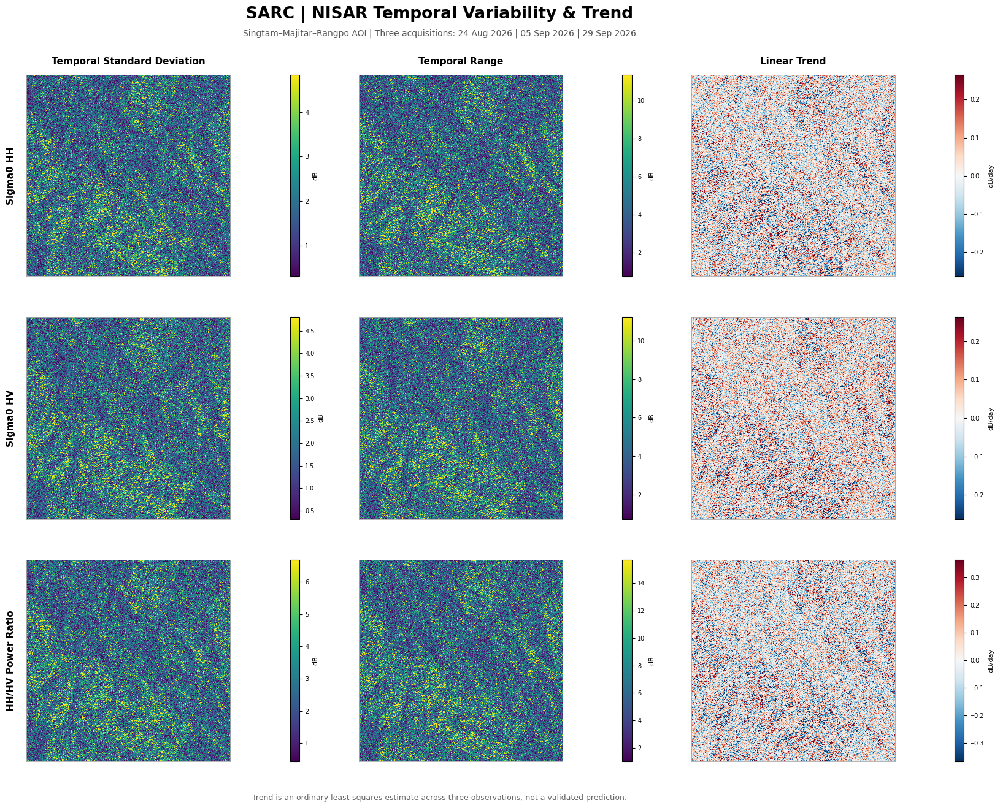


SARC TEMPORAL VARIABILITY ANALYSIS COMPLETE
Input dates: 3
Input layers: 3
Temporal metrics: 3
GeoTIFF outputs: 9
QA records: 9

QA REPORT
         Layer         Metric  Valid_Pixels      Mean    Median       P95
  Sigma0_HH_dB   temporal_std        260096  2.015937  1.846031  4.123208
  Sigma0_HH_dB temporal_range        260096  4.713328  4.312831  9.653526
  Sigma0_HH_dB          trend        260096 -0.003841 -0.002529  0.173523
  Sigma0_HV_dB   temporal_std        260096  2.013968  1.849221  4.101927
  Sigma0_HV_dB temporal_range        260096  4.709187  4.319471  9.608111
  Sigma0_HV_dB          trend        260096  0.006197  0.007474  0.182856
HH_HV_Ratio_dB   temporal_std        260096  2.821143  2.591955  5.737677
HH_HV_Ratio_dB temporal_range        260096  6.598930  6.057826 13.439680
HH_HV_Ratio_dB          trend        260096 -0.010038 -0.009877  0.238792

OUTPUTS
Rasters: /content/drive/MyDrive/SARC/processed/nisar/temporal_variability
QA CSV: /content/drive/MyDrive/SARC/m

In [ ]:

import os
import re
import glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from datetime import datetime
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# ============================================================
# 1. CONFIGURATION
# ============================================================

BASE = "/content/drive/MyDrive/SARC"

INPUT_DIR = os.path.join(
    BASE, "processed/nisar/preprocessed"
)

OUTPUT_DIR = os.path.join(
    BASE, "processed/nisar/temporal_variability"
)

MAP_DIR = os.path.join(
    BASE, "outputs/maps/nisar/temporal_variability"
)

METADATA_DIR = os.path.join(BASE, "metadata")

for folder in [OUTPUT_DIR, MAP_DIR, METADATA_DIR]:
    os.makedirs(folder, exist_ok=True)

LAYERS = [
    ("Sigma0_HH_dB", "Sigma0 HH"),
    ("Sigma0_HV_dB", "Sigma0 HV"),
    ("HH_HV_Ratio_dB", "HH/HV Power Ratio")
]

METRICS = [
    ("temporal_std", "Temporal Standard Deviation", "dB"),
    ("temporal_range", "Temporal Range", "dB"),
    ("trend", "Linear Trend", "dB/day")
]

NODATA = -9999.0

# ============================================================
# 2. DISCOVER AND VERIFY INPUT FILES
# ============================================================

if not os.path.isdir(INPUT_DIR):
    raise FileNotFoundError(INPUT_DIR)

all_files = glob.glob(os.path.join(INPUT_DIR, "*.tif"))

date_regex = re.compile(r"(202\d{5})")

def get_date(path):
    match = date_regex.search(os.path.basename(path))
    return match.group(1) if match else None

def date_label(date):
    return datetime.strptime(date, "%Y%m%d").strftime("%d %b %Y")

dates = sorted({
    get_date(p) for p in all_files
    if get_date(p) is not None
})

if len(dates) != 3:
    raise RuntimeError(
        f"Expected 3 acquisition dates, found {dates}"
    )

input_lookup = {}

for date in dates:
    for layer_key, layer_name in LAYERS:

        matches = [
            p for p in all_files
            if get_date(p) == date
            and os.path.basename(p).endswith(
                "_" + layer_key + ".tif"
            )
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected one {layer_key} file for {date}; "
                f"found {len(matches)}"
            )

        input_lookup[(date, layer_key)] = matches[0]

print("INPUT FILE VERIFICATION PASSED")
print("Acquisition dates:", [date_label(d) for d in dates])

# ============================================================
# 3. READ DATA AND VERIFY SPATIAL ALIGNMENT
# ============================================================

data = {}
reference_profile = None
reference_grid = None

for date in dates:
    for layer_key, layer_name in LAYERS:

        path = input_lookup[(date, layer_key)]

        with rasterio.open(path) as src:

            grid = (
                src.crs,
                src.transform,
                src.width,
                src.height
            )

            if reference_grid is None:
                reference_grid = grid
                reference_profile = src.profile.copy()

            elif grid != reference_grid:
                raise ValueError(
                    f"Spatial grid mismatch: {path}"
                )

            arr = src.read(1, masked=True).astype(np.float32)
            arr = np.ma.filled(arr, np.nan)

            if not np.isfinite(arr).any():
                raise ValueError(f"No valid pixels: {path}")

            data[(date, layer_key)] = arr

print("\nGRID VERIFICATION PASSED")
print("Shape:", data[(dates[0], LAYERS[0][0])].shape)
print("CRS:", reference_grid[0])

# ============================================================
# 4. ACTUAL TIME INTERVALS IN DAYS
# ============================================================

time_days = np.array([
    (
        datetime.strptime(d, "%Y%m%d")
        - datetime.strptime(dates[0], "%Y%m%d")
    ).days
    for d in dates
], dtype=np.float64)

if len(np.unique(time_days)) != 3:
    raise ValueError("Acquisition dates must be distinct.")

print("\nAcquisition time offsets (days):", time_days.tolist())

# ============================================================
# 5. PIXEL-WISE TEMPORAL STATISTICS
# ============================================================

outputs = {}
qa_rows = []

t_centered = time_days - time_days.mean()
time_denominator = np.sum(t_centered ** 2)

for layer_key, layer_name in LAYERS:

    stack = np.stack([
        data[(date, layer_key)]
        for date in dates
    ]).astype(np.float64)

    # Use only pixels valid on all three dates
    valid = np.all(np.isfinite(stack), axis=0)

    if valid.sum() == 0:
        raise ValueError(f"No common valid pixels: {layer_key}")

    temporal_mean = np.full(
        stack.shape[1:], np.nan, dtype=np.float64
    )

    temporal_std = np.full_like(temporal_mean, np.nan)
    temporal_range = np.full_like(temporal_mean, np.nan)
    trend = np.full_like(temporal_mean, np.nan)

    temporal_mean[valid] = np.mean(stack[:, valid], axis=0)

    temporal_std[valid] = np.std(
        stack[:, valid], axis=0, ddof=0
    )

    temporal_range[valid] = (
        np.max(stack[:, valid], axis=0)
        - np.min(stack[:, valid], axis=0)
    )

    # Ordinary least-squares linear trend, accounting for
    # the unequal acquisition intervals.
    trend[valid] = np.sum(
        t_centered[:, None] * stack[:, valid],
        axis=0
    ) / time_denominator

    metric_arrays = {
        "temporal_std": temporal_std,
        "temporal_range": temporal_range,
        "trend": trend
    }

    for metric_key, metric_title, unit in METRICS:

        arr = metric_arrays[metric_key].astype(np.float32)

        outputs[(layer_key, metric_key)] = arr

        output_name = (
            f"{layer_key}_{metric_key}_"
            f"{dates[0]}_to_{dates[-1]}.tif"
        )

        output_path = os.path.join(OUTPUT_DIR, output_name)

        profile = reference_profile.copy()
        profile.update(
            driver="GTiff",
            count=1,
            dtype="float32",
            nodata=NODATA,
            compress="deflate",
            predictor=3
        )

        export_arr = np.where(
            np.isfinite(arr), arr, NODATA
        ).astype(np.float32)

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(export_arr, 1)
            dst.set_band_description(
                1, f"{layer_name}: {metric_title}"
            )

        values = arr[np.isfinite(arr)]

        qa_rows.append({
            "Layer": layer_key,
            "Metric": metric_key,
            "Valid_Pixels": int(valid.sum()),
            "Mean": float(np.mean(values)),
            "Median": float(np.median(values)),
            "P95": float(np.percentile(values, 95)),
            "Minimum": float(np.min(values)),
            "Maximum": float(np.max(values)),
            "Output": output_name
        })

# ============================================================
# 6. SAVE QA REPORT
# ============================================================

qa_df = pd.DataFrame(qa_rows)

qa_path = os.path.join(
    METADATA_DIR,
    "nisar_temporal_variability_QA.csv"
)

qa_df.to_csv(qa_path, index=False)

# ============================================================
# 7. COMPARISON FIGURE WITH DEDICATED COLORBARS
# ============================================================

fig = plt.figure(figsize=(19, 14), facecolor="white")

gs = GridSpec(
    3, 6,
    figure=fig,
    width_ratios=[1, 0.035, 1, 0.035, 1, 0.035],
    left=0.12,
    right=0.95,
    top=0.88,
    bottom=0.08,
    wspace=0.22,
    hspace=0.20
)

cmaps = {
    "temporal_std": "viridis",
    "temporal_range": "viridis",
    "trend": "RdBu_r"
}

for row, (layer_key, layer_name) in enumerate(LAYERS):

    for col, (metric_key, metric_title, unit) in enumerate(METRICS):

        arr = outputs[(layer_key, metric_key)]
        values = arr[np.isfinite(arr)]

        if metric_key == "trend":
            limit = float(np.percentile(np.abs(values), 98))
            if not np.isfinite(limit) or limit == 0:
                limit = 1e-8

            norm = TwoSlopeNorm(
                vmin=-limit,
                vcenter=0,
                vmax=limit
            )
        else:
            vmin, vmax = np.percentile(values, [2, 98])

            if vmax <= vmin:
                vmax = vmin + 1e-8

            norm = Normalize(vmin=vmin, vmax=vmax)

        ax = fig.add_subplot(gs[row, col * 2])

        ax.imshow(
            arr,
            cmap=cmaps[metric_key],
            norm=norm,
            interpolation="nearest",
            origin="upper"
        )

        ax.set_xticks([])
        ax.set_yticks([])

        if row == 0:
            ax.set_title(
                metric_title,
                fontsize=11,
                fontweight="bold",
                pad=12
            )

        if col == 0:
            ax.set_ylabel(
                layer_name,
                fontsize=11,
                fontweight="bold",
                labelpad=13
            )

        for spine in ax.spines.values():
            spine.set_color("#AAAAAA")
            spine.set_linewidth(0.6)

        cax = fig.add_subplot(gs[row, col * 2 + 1])

        sm = ScalarMappable(
            norm=norm,
            cmap=cmaps[metric_key]
        )
        sm.set_array([])

        cbar = fig.colorbar(sm, cax=cax)
        cbar.set_label(unit, fontsize=8)
        cbar.ax.tick_params(labelsize=7)

fig.suptitle(
    "SARC | NISAR Temporal Variability & Trend",
    fontsize=19,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5, 0.925,
    "Singtam–Majitar–Rangpo AOI | Three acquisitions: "
    + " | ".join(date_label(d) for d in dates),
    ha="center",
    fontsize=10,
    color="#555555"
)

fig.text(
    0.5, 0.035,
    "Trend is an ordinary least-squares estimate across three observations; "
    "not a validated prediction.",
    ha="center",
    fontsize=9,
    color="#666666"
)

png_path = os.path.join(
    MAP_DIR, "SARC_NISAR_Temporal_Variability.png"
)

pdf_path = os.path.join(
    MAP_DIR, "SARC_NISAR_Temporal_Variability.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

exported = glob.glob(os.path.join(OUTPUT_DIR, "*.tif"))

assert len(exported) == 9, (
    f"Expected 9 GeoTIFFs, found {len(exported)}"
)

assert len(qa_df) == 9
assert os.path.exists(qa_path)
assert os.path.exists(png_path)
assert os.path.exists(pdf_path)

print("\n" + "=" * 65)
print("SARC TEMPORAL VARIABILITY ANALYSIS COMPLETE")
print("=" * 65)

print("Input dates:", len(dates))
print("Input layers:", len(LAYERS))
print("Temporal metrics:", len(METRICS))
print("GeoTIFF outputs:", len(exported))
print("QA records:", len(qa_df))

print("\nQA REPORT")
print(
    qa_df[
        ["Layer", "Metric", "Valid_Pixels", "Mean", "Median", "P95"]
    ].to_string(index=False)
)

print("\nOUTPUTS")
print("Rasters:", OUTPUT_DIR)
print("QA CSV:", qa_path)
print("PNG:", png_path)
print("PDF:", pdf_path)

print("\nALL OUTPUT CHECKS PASSED")


SARC | NISAR RESEARCH PACKAGE

SOURCE DATASET INVENTORY
Acquisition_Date                                                                                       Filename  Size_Bytes   Size_GB  Size_GiB  Full_Raster_Rows  Full_Raster_Columns Full_Raster_Dtype
     24 Aug 2026 NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001.h5 12621718216 12.621718 11.754891             33408                34488           float32
     05 Sep 2026 NISAR_S2_PR_GCOV_029_170_A_015_3700_DHNA_A_20260905T233024_20260905T233100_P00500_M_F_I_001.h5 12598196763 12.598197 11.732985             33408                34488           float32
     29 Sep 2026 NISAR_S2_PR_GCOV_031_170_A_015_3700_DHNA_A_20260929T233024_20260929T233101_P00500_M_F_I_001.h5 12598823664 12.598824 11.733569             33408                34488           float32

PREPROCESSING INPUT VERIFICATION PASSED
AOI raster shape: 508 512
CRS: EPSG:32645


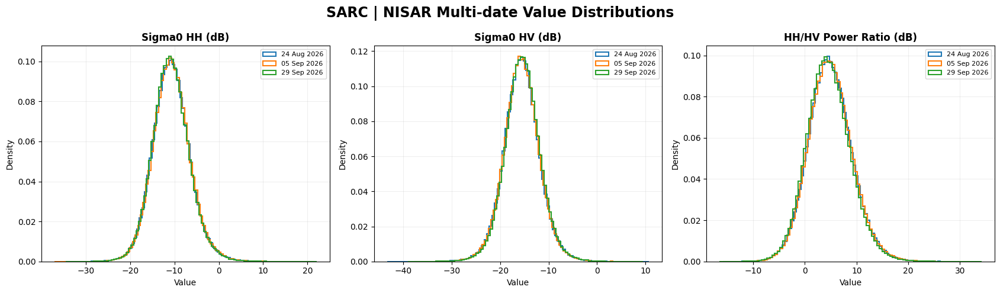

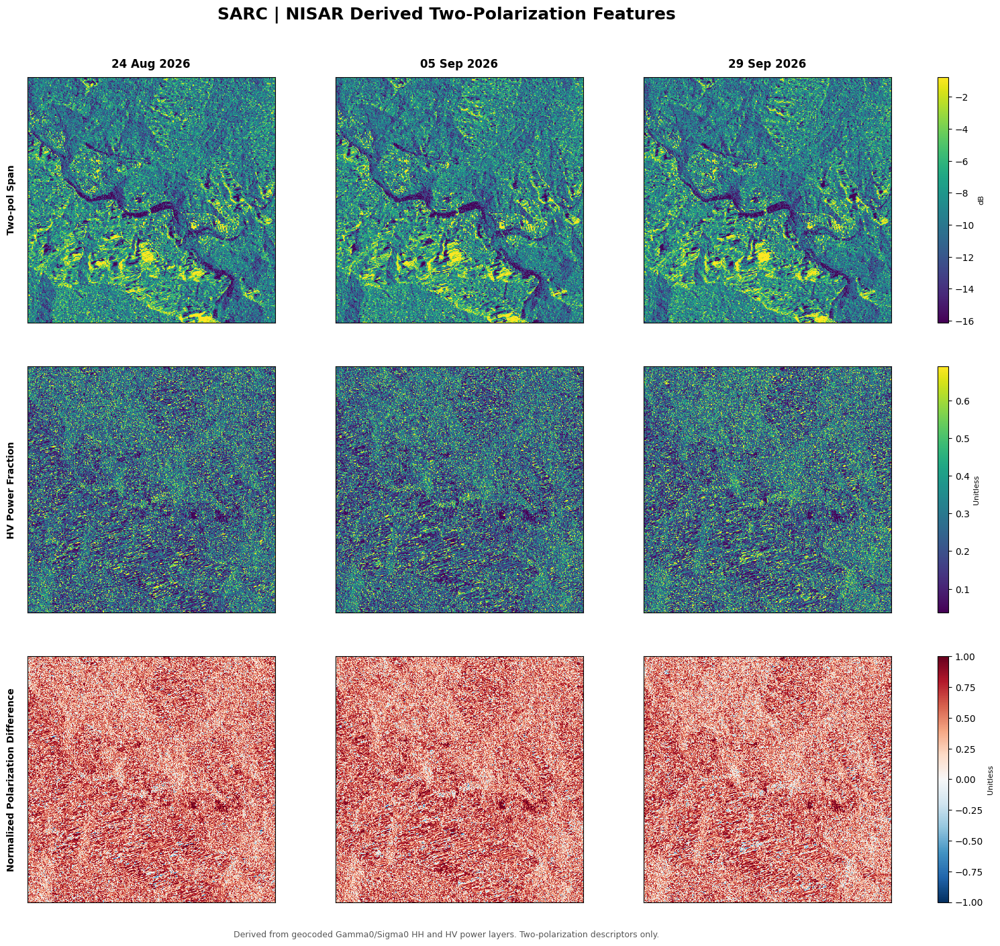


SARC NISAR RESEARCH PACKAGE COMPLETE
Original HDF5 scenes: 3
Total source size: 35.221 GiB
Full scene dimensions: (33408, 34488)
AOI dimensions: (508, 512)
AOI pixels: 260,096
Derived feature GeoTIFFs: 9
Feature/statistics records: 18

GENERATED FILES
README: /content/drive/MyDrive/SARC/data/nisar/README.md
Source inventory: /content/drive/MyDrive/SARC/metadata/nisar_source_dataset_inventory.csv
Feature statistics: /content/drive/MyDrive/SARC/metadata/nisar_scene_feature_statistics.csv
Output inventory: /content/drive/MyDrive/SARC/metadata/nisar_output_file_inventory.csv
Histogram: /content/drive/MyDrive/SARC/outputs/maps/nisar/research_package/SARC_NISAR_Backscatter_Histograms.png
Feature map: /content/drive/MyDrive/SARC/outputs/maps/nisar/research_package/SARC_NISAR_Derived_Features.png
Feature PDF: /content/drive/MyDrive/SARC/outputs/maps/nisar/research_package/SARC_NISAR_Derived_Features.pdf

ALL FINAL CHECKS PASSED


In [ ]:

# ============================================================
# SARC | NISAR THREE-SCENE RESEARCH PACKAGE
# Inventory + QA + Polarimetric Features + Statistics + README
# ============================================================

import os
import re
import glob
import json
import h5py
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize, TwoSlopeNorm
from matplotlib.cm import ScalarMappable

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive/SARC"

RAW_DIR = os.path.join(BASE, "data/nisar/raw")
PRE_DIR = os.path.join(BASE, "processed/nisar/preprocessed")

FEATURE_DIR = os.path.join(
    BASE, "processed/nisar/derived_features"
)

OUTPUT_DIR = os.path.join(
    BASE, "outputs/maps/nisar/research_package"
)

META_DIR = os.path.join(BASE, "metadata")
NISAR_DATA_DIR = os.path.join(BASE, "data/nisar")

for folder in [
    FEATURE_DIR, OUTPUT_DIR, META_DIR, NISAR_DATA_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("=" * 68)
print("SARC | NISAR RESEARCH PACKAGE")
print("=" * 68)

# ------------------------------------------------------------
# 2. FIND ORIGINAL HDF5 FILES
# ------------------------------------------------------------

if "nisar_files" in globals() and len(nisar_files) > 0:
    raw_files = [str(p) for p in nisar_files]
else:
    raw_files = glob.glob(
        "/content/drive/MyDrive/**/*.h5",
        recursive=True
    )

raw_files = [
    p for p in raw_files
    if os.path.isfile(p)
    and os.path.basename(p).startswith("NISAR_S2_PR_GCOV")
]

date_pattern = re.compile(r"(202\d{5})")

def get_date(path):
    match = date_pattern.search(os.path.basename(path))
    return match.group(1) if match else None

def pretty_date(date):
    return datetime.strptime(
        date, "%Y%m%d"
    ).strftime("%d %b %Y")

raw_files = sorted(
    raw_files,
    key=lambda p: get_date(p) or ""
)

if len(raw_files) != 3:
    raise RuntimeError(
        f"Expected exactly 3 source HDF5 files, found {len(raw_files)}. "
        "Check nisar_files and the original Drive locations."
    )

scene_dates = [get_date(p) for p in raw_files]

if len(set(scene_dates)) != 3 or None in scene_dates:
    raise RuntimeError("Source acquisition dates are missing or duplicated.")

print("\nSOURCE DATASET INVENTORY")

source_inventory = []
scene_metadata = {}

H5_BASE = "/science/SSAR/GCOV/grids/frequencyA"

for path in raw_files:

    date = get_date(path)
    size_bytes = os.path.getsize(path)

    with h5py.File(path, "r") as f:

        hhhh = f[f"{H5_BASE}/HHHH"]

        full_shape = tuple(hhhh.shape)
        full_dtype = str(hhhh.dtype)

        x_spacing = float(
            f[f"{H5_BASE}/xCoordinateSpacing"][()]
        )

        y_spacing = float(
            f[f"{H5_BASE}/yCoordinateSpacing"][()]
        )

        scene_metadata[date] = {
            "filename": os.path.basename(path),
            "full_shape": full_shape,
            "dtype": full_dtype,
            "x_spacing": x_spacing,
            "y_spacing": y_spacing,
            "size_bytes": size_bytes
        }

    source_inventory.append({
        "Acquisition_Date": pretty_date(date),
        "Filename": os.path.basename(path),
        "Size_Bytes": size_bytes,
        "Size_GB": size_bytes / 1e9,
        "Size_GiB": size_bytes / (1024 ** 3),
        "Full_Raster_Rows": full_shape[0],
        "Full_Raster_Columns": full_shape[1],
        "Full_Raster_Dtype": full_dtype
    })

source_df = pd.DataFrame(source_inventory)

source_csv = os.path.join(
    META_DIR, "nisar_source_dataset_inventory.csv"
)

source_df.to_csv(source_csv, index=False)

print(source_df.to_string(index=False))

# ------------------------------------------------------------
# 3. VERIFY PREPROCESSED INPUT RASTERS
# ------------------------------------------------------------

REQUIRED_LAYERS = [
    "Sigma0_HH_dB",
    "Sigma0_HV_dB",
    "HH_HV_Ratio_dB"
]

raster_lookup = {}

for date in scene_dates:

    for layer in REQUIRED_LAYERS:

        matches = [
            p for p in glob.glob(os.path.join(PRE_DIR, "*.tif"))
            if get_date(p) == date
            and os.path.basename(p).endswith("_" + layer + ".tif")
        ]

        if len(matches) != 1:
            raise RuntimeError(
                f"Expected one {layer} file for {date}; found {len(matches)}"
            )

        raster_lookup[(date, layer)] = matches[0]

# Verify exact grid alignment
reference_grid = None
reference_profile = None

for key, path in raster_lookup.items():

    with rasterio.open(path) as src:

        current_grid = (
            src.crs,
            src.transform,
            src.width,
            src.height
        )

        if reference_grid is None:
            reference_grid = current_grid
            reference_profile = src.profile.copy()

        elif current_grid != reference_grid:
            raise ValueError(f"Raster grid mismatch: {path}")

print("\nPREPROCESSING INPUT VERIFICATION PASSED")
print("AOI raster shape:", reference_profile["height"],
      reference_profile["width"])
print("CRS:", reference_grid[0])

# ------------------------------------------------------------
# 4. CALCULATE ADDITIONAL TWO-POLARIZATION FEATURES
# ------------------------------------------------------------

feature_definitions = {
    "Span_dB": "10*log10(HH power + HV power)",
    "HV_Fraction": "HV power / (HH power + HV power)",
    "Normalized_Pol_Difference": "(HH power - HV power) / (HH power + HV power)"
}

feature_arrays = {}
statistics_rows = []

for date in scene_dates:

    with rasterio.open(raster_lookup[(date, "Sigma0_HH_dB")]) as src:
        hh_db = src.read(1, masked=True).astype(np.float64)
        hh_db = np.ma.filled(hh_db, np.nan)

    with rasterio.open(raster_lookup[(date, "Sigma0_HV_dB")]) as src:
        hv_db = src.read(1, masked=True).astype(np.float64)
        hv_db = np.ma.filled(hv_db, np.nan)

    valid = (
        np.isfinite(hh_db)
        & np.isfinite(hv_db)
    )

    hh_power = np.full(hh_db.shape, np.nan, dtype=np.float64)
    hv_power = np.full(hv_db.shape, np.nan, dtype=np.float64)

    # Convert dB power representations to linear power
    hh_power[valid] = 10.0 ** (hh_db[valid] / 10.0)
    hv_power[valid] = 10.0 ** (hv_db[valid] / 10.0)

    total_power = hh_power + hv_power

    valid &= (
        np.isfinite(total_power)
        & (total_power > 0)
    )

    span_db = np.full(hh_db.shape, np.nan)
    hv_fraction = np.full(hh_db.shape, np.nan)
    normalized_difference = np.full(hh_db.shape, np.nan)

    span_db[valid] = 10.0 * np.log10(total_power[valid])

    hv_fraction[valid] = (
        hv_power[valid] / total_power[valid]
    )

    normalized_difference[valid] = (
        (hh_power[valid] - hv_power[valid])
        / total_power[valid]
    )

    features = {
        "Span_dB": span_db,
        "HV_Fraction": hv_fraction,
        "Normalized_Pol_Difference": normalized_difference
    }

    for feature_name, arr in features.items():

        arr = arr.astype(np.float32)
        feature_arrays[(date, feature_name)] = arr

        output_name = f"{date}_{feature_name}.tif"
        output_path = os.path.join(FEATURE_DIR, output_name)

        profile = reference_profile.copy()
        profile.update(
            driver="GTiff",
            count=1,
            dtype="float32",
            nodata=-9999.0,
            compress="deflate",
            predictor=3
        )

        export_arr = np.where(
            np.isfinite(arr), arr, -9999.0
        ).astype(np.float32)

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(export_arr, 1)
            dst.set_band_description(1, feature_name)

        values = arr[np.isfinite(arr)]

        statistics_rows.append({
            "Date": pretty_date(date),
            "Feature": feature_name,
            "Valid_Pixels": int(valid.sum()),
            "Mean": float(np.mean(values)),
            "Median": float(np.median(values)),
            "Std": float(np.std(values)),
            "P05": float(np.percentile(values, 5)),
            "P95": float(np.percentile(values, 95)),
            "Minimum": float(np.min(values)),
            "Maximum": float(np.max(values))
        })

# ------------------------------------------------------------
# 5. SCENE-WISE BACKSCATTER STATISTICS
# ------------------------------------------------------------

for date in scene_dates:

    for layer in REQUIRED_LAYERS:

        path = raster_lookup[(date, layer)]

        with rasterio.open(path) as src:
            arr = src.read(1, masked=True).astype(np.float64)
            arr = np.ma.filled(arr, np.nan)

        values = arr[np.isfinite(arr)]

        statistics_rows.append({
            "Date": pretty_date(date),
            "Feature": layer,
            "Valid_Pixels": int(len(values)),
            "Mean": float(np.mean(values)),
            "Median": float(np.median(values)),
            "Std": float(np.std(values)),
            "P05": float(np.percentile(values, 5)),
            "P95": float(np.percentile(values, 95)),
            "Minimum": float(np.min(values)),
            "Maximum": float(np.max(values))
        })

statistics_df = pd.DataFrame(statistics_rows)

statistics_csv = os.path.join(
    META_DIR, "nisar_scene_feature_statistics.csv"
)

statistics_df.to_csv(statistics_csv, index=False)

# ------------------------------------------------------------
# 6. HISTOGRAM COMPARISON
# ------------------------------------------------------------

hist_layers = [
    ("Sigma0_HH_dB", "Sigma0 HH (dB)", "backscatter"),
    ("Sigma0_HV_dB", "Sigma0 HV (dB)", "backscatter"),
    ("HH_HV_Ratio_dB", "HH/HV Power Ratio (dB)", "ratio")
]

fig, axes = plt.subplots(
    1, 3, figsize=(17, 5), facecolor="white"
)

for ax, (layer, title, kind) in zip(axes, hist_layers):

    for date in scene_dates:

        with rasterio.open(raster_lookup[(date, layer)]) as src:
            arr = src.read(1, masked=True)
            values = np.asarray(arr.compressed(), dtype=np.float32)

        values = values[np.isfinite(values)]

        ax.hist(
            values,
            bins=100,
            density=True,
            histtype="step",
            linewidth=1.5,
            label=pretty_date(date)
        )

    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "SARC | NISAR Multi-date Value Distributions",
    fontsize=17,
    fontweight="bold"
)

fig.tight_layout()

hist_path = os.path.join(
    OUTPUT_DIR, "SARC_NISAR_Backscatter_Histograms.png"
)

fig.savefig(hist_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. ADDITIONAL FEATURE COMPARISON MAP
# ------------------------------------------------------------

FEATURES = [
    ("Span_dB", "Two-pol Span", "dB"),
    ("HV_Fraction", "HV Power Fraction", "Unitless"),
    ("Normalized_Pol_Difference", "Normalized Polarization Difference", "Unitless")
]

fig = plt.figure(figsize=(17, 15), facecolor="white")

gs = GridSpec(
    3, 4,
    figure=fig,
    width_ratios=[1, 1, 1, 0.04],
    left=0.12,
    right=0.94,
    top=0.89,
    bottom=0.07,
    wspace=0.15,
    hspace=0.18
)

for row, (feature_key, feature_title, unit) in enumerate(FEATURES):

    stack = [
        feature_arrays[(date, feature_key)]
        for date in scene_dates
    ]

    values = np.concatenate([
        arr[np.isfinite(arr)] for arr in stack
    ])

    if feature_key == "Normalized_Pol_Difference":
        norm = TwoSlopeNorm(
            vmin=-1, vcenter=0, vmax=1
        )
    else:
        vmin, vmax = np.percentile(values, [2, 98])
        if vmax <= vmin:
            vmax = vmin + 1e-8
        norm = Normalize(vmin=vmin, vmax=vmax)

    for col, date in enumerate(scene_dates):

        ax = fig.add_subplot(gs[row, col])

        ax.imshow(
            feature_arrays[(date, feature_key)],
            cmap="viridis" if row != 2 else "RdBu_r",
            norm=norm,
            origin="upper",
            interpolation="nearest"
        )

        if row == 0:
            ax.set_title(
                pretty_date(date),
                fontsize=12,
                fontweight="bold",
                pad=10
            )

        if col == 0:
            ax.set_ylabel(
                feature_title,
                fontsize=10,
                fontweight="bold",
                labelpad=12
            )

        ax.set_xticks([])
        ax.set_yticks([])

    cax = fig.add_subplot(gs[row, 3])

    sm = ScalarMappable(
        norm=norm,
        cmap="viridis" if row != 2 else "RdBu_r"
    )
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label(unit, fontsize=8)

fig.suptitle(
    "SARC | NISAR Derived Two-Polarization Features",
    fontsize=18,
    fontweight="bold",
    y=0.96
)

fig.text(
    0.5, 0.035,
    "Derived from geocoded Gamma0/Sigma0 HH and HV power layers. "
    "Two-polarization descriptors only.",
    ha="center",
    fontsize=9,
    color="#555555"
)

feature_map_path = os.path.join(
    OUTPUT_DIR, "SARC_NISAR_Derived_Features.png"
)

feature_pdf_path = os.path.join(
    OUTPUT_DIR, "SARC_NISAR_Derived_Features.pdf"
)

fig.savefig(
    feature_map_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    feature_pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. FILE SIZE INVENTORY
# ------------------------------------------------------------

def directory_inventory(folder, label):

    rows = []

    for path in glob.glob(
        os.path.join(folder, "**", "*"),
        recursive=True
    ):
        if os.path.isfile(path):
            size = os.path.getsize(path)
            rows.append({
                "Category": label,
                "Filename": os.path.basename(path),
                "Relative_Path": os.path.relpath(path, BASE),
                "Size_Bytes": size,
                "Size_MB": size / 1e6,
                "Size_GiB": size / (1024 ** 3)
            })

    return rows

file_rows = []

for folder, label in [
    (PRE_DIR, "Preprocessed rasters"),
    (FEATURE_DIR, "Derived feature rasters"),
    (os.path.join(BASE, "processed/nisar/change_analysis"), "Change rasters"),
    (os.path.join(BASE, "processed/nisar/temporal_variability"), "Temporal variability rasters"),
    (OUTPUT_DIR, "Research figures")
]:
    if os.path.isdir(folder):
        file_rows.extend(directory_inventory(folder, label))

file_inventory_df = pd.DataFrame(file_rows)

file_inventory_csv = os.path.join(
    META_DIR, "nisar_output_file_inventory.csv"
)

file_inventory_df.to_csv(file_inventory_csv, index=False)

# ------------------------------------------------------------
# 9. GENERATE DATASET README
# ------------------------------------------------------------

total_raw_bytes = int(source_df["Size_Bytes"].sum())
total_raw_gib = total_raw_bytes / (1024 ** 3)

total_preprocessed_bytes = sum(
    os.path.getsize(p)
    for p in glob.glob(os.path.join(PRE_DIR, "*.tif"))
)

aoi_rows = reference_profile["height"]
aoi_cols = reference_profile["width"]
aoi_pixels = aoi_rows * aoi_cols

scene_table = "\n".join([
    f"| {row['Acquisition_Date']} | "
    f"`{row['Filename']}` | "
    f"{row['Size_GiB']:.3f} GiB | "
    f"{row['Full_Raster_Rows']} × {row['Full_Raster_Columns']} |"
    for _, row in source_df.iterrows()
])

readme = f"""# SARC — NISAR S-band GCOV Dataset & Processing

## 1. Project Overview

SARC is a research-driven satellite and geospatial analysis initiative.

This dataset package documents three NISAR S-band GCOV acquisitions used for
multi-date analysis over the Singtam–Majitar–Rangpo candidate AOI,
Teesta River Basin, Sikkim.

**This is a 2026 multi-date observation study. It is not a reconstruction
of the October 2023 South Lhonak GLOF event.**

## 2. Source Dataset

| Attribute | Value |
|---|---|
| Mission | NASA–ISRO NISAR |
| Frequency band | S-band |
| Product family | NISAR S-band GCOV |
| Product type | GCOV |
| Polarizations | HH and HV |
| Covariance terms | HHHH, HHHV, HVHV |
| Acquisition mode | Ascending |
| Track | 170 |
| Frame | 15 |
| Product grid | EPSG:32645 |
| Pixel spacing | {abs(scene_metadata[scene_dates[0]]['x_spacing']):.0f} m |
| AOI raster dimensions | {aoi_rows} × {aoi_cols} |
| AOI pixels | {aoi_pixels:,} |
| Total original source size | {total_raw_gib:.3f} GiB |
| Number of acquisitions | 3 |

### Original acquisitions

| Date | Source filename | File size | Full raster dimensions |
|---|---|---:|---|
{scene_table}

**Total source file size:** {total_raw_bytes:,} bytes ({total_raw_gib:.3f} GiB).

File sizes above are measured from the original files in Google Drive.
They are not estimates.

## 3. Spatial Study Area

Candidate AOI bounding coordinates:

- North: 27.2025° N
- South: 27.1575° N
- West: 88.4897° E
- East: 88.5403° E

Projected CRS: EPSG:32645 (WGS 84 / UTM zone 45N).

AOI raster dimensions: {aoi_rows} × {aoi_cols} pixels.

The AOI is a subset extracted from each source scene. The full original
HDF5 datasets are retained separately.

## 4. Acquisition Dates

- 24 August 2026
- 05 September 2026
- 29 September 2026

All three candidate acquisitions were verified to cover the selected AOI.
Their matching raster dimensions and grid alignment were checked before
pixel-wise temporal analysis.

## 5. Processing Completed

### A. Source extraction and quality checks

- HDF5 structure and covariance layers inspected.
- AOI subset extracted from each scene.
- Geospatial transform and CRS preserved.
- HHHH and HVHV power layers inspected.
- HHHV complex cross-covariance retained as a complex-valued layer.
- Valid-sample mask and input-data exception mask inspected.
- Number of looks inspected.
- RTC Gamma-to-Sigma conversion factor inspected.

### B. Preprocessing

- Gamma0 HH backscatter representation.
- Sigma0 HH backscatter representation.
- Sigma0 HV backscatter representation.
- HH/HV power ratio.
- Normalized cross-covariance magnitude.
- Quality and metadata layers.
- Multi-date comparison visualization.

### C. Temporal analysis

- 24 Aug to 05 Sep 2026.
- 05 Sep to 29 Sep 2026.
- 24 Aug to 29 Sep 2026.
- Pixel-wise temporal differences.
- Temporal standard deviation.
- Temporal range.
- Exploratory linear trend using actual acquisition-day offsets.

### D. Additional two-polarization descriptors

- Two-polarization Span (HH + HV).
- HV power fraction.
- Normalized polarization difference.

These descriptors are derived from the available HH and HV diagonal
covariance/power terms. They are not a full polarimetric decomposition.

## 6. Important Product Interpretation

- HHHH and HVHV are diagonal covariance/power terms.
- HHHV is a complex cross-covariance term, not an ordinary intensity image.
- The product metadata describes HHHH/HVHV as Gamma0 backscatter
  representations and identifies the RTC Gamma-to-Sigma factor.
- The product metadata reports that noise correction was not applied.
- The product metadata reports that post-processing filtering was not applied.
- The number of looks within the selected AOI was observed as 16 in the
  inspected scenes.
- The validity mask and exception mask must be interpreted using the
  product specification; do not infer meanings from numeric values alone.

## 7. Scientific Limitations

1. Three acquisitions provide only a short temporal sample.
2. The estimated linear trend is exploratory, not a validated long-term trend.
3. Backscatter variation alone does not confirm flooding, inundation,
   damage, or water expansion.
4. No independent ground-truth validation is claimed here.
5. S-band and C-band measurements must not be directly differenced without
   suitable cross-sensor harmonization.
6. The 2026 acquisitions are not pre/post-event observations of the
   October 2023 GLOF.
7. Pixel spacing is not the same as effective spatial resolution.
8. The available HH/HV channels do not constitute a complete polarimetric
   characterization.

## 8. Output Directories

| Content | Location |
|---|---|
| Original NISAR files | `data/nisar/raw/` or original Drive locations |
| Preprocessed rasters | `processed/nisar/preprocessed/` |
| Derived features | `processed/nisar/derived_features/` |
| Change analysis | `processed/nisar/change_analysis/` |
| Temporal variability | `processed/nisar/temporal_variability/` |
| Preprocessing QA | `metadata/nisar_preprocessing_QA.csv` |
| Temporal change QA | `metadata/nisar_temporal_change_summary.csv` |
| Temporal variability QA | `metadata/nisar_temporal_variability_QA.csv` |
| Source inventory | `metadata/nisar_source_dataset_inventory.csv` |
| Feature statistics | `metadata/nisar_scene_feature_statistics.csv` |
| File inventory | `metadata/nisar_output_file_inventory.csv` |
| Research figures | `outputs/maps/nisar/research_package/` |

## 9. Reproducibility

Processing was performed using Python in Google Colab with HDF5,
Rasterio, NumPy, Pandas and Matplotlib.

The original HDF5 source files are preserved. Derived outputs are stored
separately to maintain traceability.

For reproducibility, retain the source files, notebook, metadata reports,
and processing outputs together.

## 10. Research Status

**Status:** Three-scene NISAR AOI preprocessing and exploratory temporal
analysis completed.

**Next research requirements:** independent reference data, hydrological
context, river-corridor analysis, and cross-sensor comparison where
appropriate.
"""

readme_path = os.path.join(NISAR_DATA_DIR, "README.md")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)

# ------------------------------------------------------------
# 10. FINAL PACKAGE VERIFICATION
# ------------------------------------------------------------

derived_files = glob.glob(
    os.path.join(FEATURE_DIR, "*.tif")
)

assert len(raw_files) == 3
assert len(derived_files) == 9
assert len(statistics_df) == 18
assert os.path.exists(source_csv)
assert os.path.exists(statistics_csv)
assert os.path.exists(file_inventory_csv)
assert os.path.exists(readme_path)
assert os.path.exists(hist_path)
assert os.path.exists(feature_map_path)
assert os.path.exists(feature_pdf_path)

print("\n" + "=" * 68)
print("SARC NISAR RESEARCH PACKAGE COMPLETE")
print("=" * 68)

print("Original HDF5 scenes:", len(raw_files))
print("Total source size: {:.3f} GiB".format(total_raw_gib))
print("Full scene dimensions:", scene_metadata[scene_dates[0]]["full_shape"])
print("AOI dimensions:", (aoi_rows, aoi_cols))
print("AOI pixels:", f"{aoi_pixels:,}")
print("Derived feature GeoTIFFs:", len(derived_files))
print("Feature/statistics records:", len(statistics_df))

print("\nGENERATED FILES")
print("README:", readme_path)
print("Source inventory:", source_csv)
print("Feature statistics:", statistics_csv)
print("Output inventory:", file_inventory_csv)
print("Histogram:", hist_path)
print("Feature map:", feature_map_path)
print("Feature PDF:", feature_pdf_path)

print("\nALL FINAL CHECKS PASSED")


In [ ]:

# ============================================================
# SARC | CELL 15
# NISAR OUTPUT INVENTORY & RASTER VERIFICATION
# ============================================================

from pathlib import Path
import rasterio
import pandas as pd
import os

BASE = Path("/content/drive/MyDrive/SARC")

DIRECTORIES = {
    "Preprocessed": BASE / "processed/nisar/preprocessed",
    "Change Analysis": BASE / "processed/nisar/change_analysis",
    "Metadata": BASE / "metadata",
    "Maps": BASE / "outputs/maps/nisar/change_analysis"
}

records = []

print("=" * 75)
print("SARC | NISAR DATA INVENTORY")
print("=" * 75)

for category, directory in DIRECTORIES.items():

    print(f"\n\n[{category}]")
    print("-" * 75)

    if not directory.exists():
        print("Directory not found:", directory)
        continue

    files = sorted(directory.rglob("*"))

    valid_files = [
        f for f in files
        if f.is_file()
    ]

    if not valid_files:
        print("No files found.")
        continue

    for file in valid_files:

        size_mb = file.stat().st_size / (1024 ** 2)

        record = {
            "Category": category,
            "Filename": file.name,
            "Extension": file.suffix,
            "Size_MB": round(size_mb, 3),
            "Path": str(file)
        }

        if file.suffix.lower() in [".tif", ".tiff"]:

            try:
                with rasterio.open(file) as src:

                    record.update({
                        "Width": src.width,
                        "Height": src.height,
                        "Bands": src.count,
                        "Data_Type": str(src.dtypes),
                        "CRS": str(src.crs),
                        "Pixel_Size": str(src.res),
                        "NoData": str(src.nodata),
                        "Bounds": str(src.bounds)
                    })

            except Exception as e:
                record["Raster_Error"] = str(e)

        records.append(record)

        print(f"\nFile: {file.name}")
        print(f"Size: {size_mb:.3f} MB")

        if "Width" in record:
            print(
                f"Raster: {record['Width']} x "
                f"{record['Height']} | "
                f"Bands: {record['Bands']}"
            )
            print(f"CRS: {record['CRS']}")
            print(f"Resolution: {record['Pixel_Size']}")

inventory = pd.DataFrame(records)

output_csv = BASE / "metadata/nisar_complete_output_inventory.csv"
output_csv.parent.mkdir(parents=True, exist_ok=True)

inventory.to_csv(output_csv, index=False)

print("\n" + "=" * 75)
print("INVENTORY COMPLETE")
print("Total files:", len(inventory))
print("CSV:", output_csv)
print("=" * 75)

display(inventory)


SARC | NISAR DATA INVENTORY


[Preprocessed]
---------------------------------------------------------------------------

File: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001_Gamma0_HH.tif
Size: 0.850 MB
Raster: 512 x 508 | Bands: 1
CRS: EPSG:32645
Resolution: (10.0, 10.0)

File: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001_Gamma0_HH_dB.tif
Size: 0.835 MB
Raster: 512 x 508 | Bands: 1
CRS: EPSG:32645
Resolution: (10.0, 10.0)

File: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001_Gamma0_HV.tif
Size: 0.846 MB
Raster: 512 x 508 | Bands: 1
CRS: EPSG:32645
Resolution: (10.0, 10.0)

File: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101_P00500_M_F_I_001_Gamma0_HV_dB.tif
Size: 0.779 MB
Raster: 512 x 508 | Bands: 1
CRS: EPSG:32645
Resolution: (10.0, 10.0)

File: NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_20260824T233024_20260824T233101

,Category,Filename,Extension,Size_MB,Path,Width,Height,Bands,Data_Type,CRS,Pixel_Size,NoData,Bounds
0,Preprocessed,NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_202...,.tif,0.850,/content/drive/MyDrive/SARC/processed/nisar/pr...,512.0,508.0,1.0,"('float32',)",EPSG:32645,"(10.0, 10.0)",-9999.0,"BoundingBox(left=647520.0, bottom=3004740.0, r..."
1,Preprocessed,NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_202...,.tif,0.835,/content/drive/MyDrive/SARC/processed/nisar/pr...,512.0,508.0,1.0,"('float32',)",EPSG:32645,"(10.0, 10.0)",-9999.0,"BoundingBox(left=647520.0, bottom=3004740.0, r..."
2,Preprocessed,NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_202...,.tif,0.846,/content/drive/MyDrive/SARC/processed/nisar/pr...,512.0,508.0,1.0,"('float32',)",EPSG:32645,"(10.0, 10.0)",-9999.0,"BoundingBox(left=647520.0, bottom=3004740.0, r..."
3,Preprocessed,NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_202...,.tif,0.779,/content/drive/MyDrive/SARC/processed/nisar/pr...,512.0,508.0,1.0,"('float32',)",EPSG:32645,"(10.0, 10.0)",-9999.0,"BoundingBox(left=647520.0, bottom=3004740.0, r..."
4,Preprocessed,NISAR_S2_PR_GCOV_028_170_A_015_3700_DHNA_A_202...,.tif,0.927,/content/drive/MyDrive/SARC/processed/nisar/pr...,512.0,508.0,1.0,"('float32',)",EPSG:32645,"(10.0, 10.0)",-9999.0,"BoundingBox(left=647520.0, bottom=3004740.0, r..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Metadata,sarc_cluster_interpretation_summary.json,.json,0.003,/content/drive/MyDrive/SARC/metadata/sarc_clus...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,Metadata,sarc_config.json,.json,0.001,/content/drive/MyDrive/SARC/metadata/sarc_conf...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
69,Metadata,sarc_unsupervised_ml_experiment.json,.json,0.003,/content/drive/MyDrive/SARC/metadata/sarc_unsu...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70,Maps,SARC_NISAR_Temporal_Change.pdf,.pdf,1.085,/content/drive/MyDrive/SARC/outputs/maps/nisar...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

# ============================================================
# SARC | CELL 16
# NISAR THREE-DATE TEMPORAL STATISTICAL ANALYSIS
# ============================================================

from pathlib import Path
from datetime import datetime
import re
import numpy as np
import pandas as pd
import rasterio

BASE = Path("/content/drive/MyDrive/SARC")

INPUT_DIR = BASE / "processed/nisar/preprocessed"

OUTPUT_DIR = BASE / "processed/nisar/temporal_statistics"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

QA_DIR = BASE / "metadata"
QA_DIR.mkdir(parents=True, exist_ok=True)

METRICS = [
    "Sigma0_HH_dB",
    "Sigma0_HV_dB",
    "HH_HV_Ratio_dB"
]

NODATA_OUT = -9999.0

print("=" * 75)
print("SARC | NISAR TEMPORAL STATISTICS")
print("=" * 75)

qa_records = []
summary_records = []

for metric in METRICS:

    print(f"\nProcessing: {metric}")

    files = list(INPUT_DIR.glob(f"*_{metric}.tif"))

    dated_files = []

    for file in files:

        match = re.search(r"_A_(20\d{6})T", file.name)

        if match:
            date = datetime.strptime(match.group(1), "%Y%m%d")
            dated_files.append((date, file))

    dated_files.sort(key=lambda x: x[0])

    if len(dated_files) != 3:
        raise RuntimeError(
            f"{metric}: Expected 3 dated rasters, found {len(dated_files)}"
        )

    arrays = []
    reference_profile = None
    reference_transform = None
    reference_crs = None

    for date, file in dated_files:

        with rasterio.open(file) as src:

            if reference_profile is None:
                reference_profile = src.profile.copy()
                reference_transform = src.transform
                reference_crs = src.crs
                reference_shape = (src.height, src.width)

            else:
                if (
                    src.transform != reference_transform
                    or src.crs != reference_crs
                    or (src.height, src.width) != reference_shape
                ):
                    raise RuntimeError(
                        f"Spatial grid mismatch: {file.name}"
                    )

            data = src.read(1).astype(np.float32)

            valid = np.isfinite(data)

            if src.nodata is not None:
                valid &= data != src.nodata

            arrays.append(
                np.where(valid, data, np.nan)
            )

            print(
                f"  {date:%Y-%m-%d} | "
                f"{src.width}x{src.height} | {src.crs}"
            )

    stack = np.stack(arrays, axis=0)

    # Only pixels valid in all three acquisitions
    valid_all = np.all(np.isfinite(stack), axis=0)

    valid_count = int(valid_all.sum())

    if valid_count == 0:
        raise RuntimeError(f"No common valid pixels for {metric}")

    # Actual acquisition intervals: 0, 12 and 36 days
    dates = [item[0] for item in dated_files]

    time_days = np.array(
        [(d - dates[0]).days for d in dates],
        dtype=np.float32
    )

    mean = np.nanmean(stack, axis=0)
    std = np.nanstd(stack, axis=0, ddof=0)
    minimum = np.nanmin(stack, axis=0)
    maximum = np.nanmax(stack, axis=0)
    value_range = maximum - minimum

    # Linear trend in dB per day
    t_mean = time_days.mean()
    t_centered = time_days - t_mean

    y_centered = stack - mean[None, :, :]

    numerator = np.nansum(
        y_centered * t_centered[:, None, None],
        axis=0
    )

    denominator = np.sum(t_centered ** 2)

    trend = numerator / denominator

    outputs = {
        "Mean": mean,
        "StdDev": std,
        "Minimum": minimum,
        "Maximum": maximum,
        "Range": value_range,
        "Trend_dB_per_day": trend
    }

    profile = reference_profile.copy()

    profile.update(
        driver="GTiff",
        dtype="float32",
        count=1,
        nodata=NODATA_OUT,
        compress="deflate",
        predictor=3
    )

    for name, result in outputs.items():

        output_path = OUTPUT_DIR / f"{metric}_{name}.tif"

        final_array = np.full(
            valid_all.shape,
            NODATA_OUT,
            dtype=np.float32
        )

        final_array[valid_all] = result[valid_all]

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(final_array, 1)

            dst.update_tags(
                ANALYSIS="Three-date temporal statistics",
                SOURCE_METRIC=metric,
                OBSERVATIONS=3,
                DATE_RANGE=(
                    f"{dates[0]:%Y-%m-%d}_to_{dates[-1]:%Y-%m-%d}"
                ),
                TREND_UNITS=(
                    "dB/day" if name == "Trend_dB_per_day" else "dB"
                )
            )

        values = result[valid_all]

        summary_records.append({
            "Metric": metric,
            "Statistic": name,
            "Valid_Pixels": valid_count,
            "Mean": float(np.mean(values)),
            "Median": float(np.median(values)),
            "Minimum": float(np.min(values)),
            "Maximum": float(np.max(values)),
            "Output": str(output_path)
        })

    qa_records.append({
        "Metric": metric,
        "Acquisitions": len(dated_files),
        "Dates": ", ".join(d.strftime("%Y-%m-%d") for d in dates),
        "Time_Intervals_Days": ", ".join(map(str, np.diff(time_days).astype(int))),
        "Valid_Common_Pixels": valid_count,
        "Total_Pixels": int(valid_all.size),
        "Valid_Percent": round(100 * valid_count / valid_all.size, 4),
        "CRS": str(reference_crs),
        "Resolution": str(reference_profile["transform"])
    })

    print(
        f"  Valid common pixels: {valid_count:,}/{valid_all.size:,}"
    )

# Save statistical summary and QA
summary_df = pd.DataFrame(summary_records)
qa_df = pd.DataFrame(qa_records)

summary_path = QA_DIR / "nisar_temporal_statistics_summary.csv"
qa_path = QA_DIR / "nisar_temporal_statistics_QA.csv"

summary_df.to_csv(summary_path, index=False)
qa_df.to_csv(qa_path, index=False)

print("\n" + "=" * 75)
print("TEMPORAL STATISTICS COMPLETE")
print("=" * 75)

print("Output directory:", OUTPUT_DIR)
print("Generated rasters:", len(summary_df))
print("Summary:", summary_path)
print("QA:", qa_path)

display(qa_df)
display(summary_df)


SARC | NISAR TEMPORAL STATISTICS

Processing: Sigma0_HH_dB
  2026-08-24 | 512x508 | EPSG:32645
  2026-09-05 | 512x508 | EPSG:32645
  2026-09-29 | 512x508 | EPSG:32645


  Valid common pixels: 260,096/260,096

Processing: Sigma0_HV_dB
  2026-08-24 | 512x508 | EPSG:32645
  2026-09-05 | 512x508 | EPSG:32645
  2026-09-29 | 512x508 | EPSG:32645


  Valid common pixels: 260,096/260,096

Processing: HH_HV_Ratio_dB
  2026-08-24 | 512x508 | EPSG:32645
  2026-09-05 | 512x508 | EPSG:32645
  2026-09-29 | 512x508 | EPSG:32645


  Valid common pixels: 260,096/260,096

TEMPORAL STATISTICS COMPLETE
Output directory: /content/drive/MyDrive/SARC/processed/nisar/temporal_statistics
Generated rasters: 18
Summary: /content/drive/MyDrive/SARC/metadata/nisar_temporal_statistics_summary.csv
QA: /content/drive/MyDrive/SARC/metadata/nisar_temporal_statistics_QA.csv


,Metric,Acquisitions,Dates,Time_Intervals_Days,Valid_Common_Pixels,Total_Pixels,Valid_Percent,CRS,Resolution
0,Sigma0_HH_dB,3,"2026-08-24, 2026-09-05, 2026-09-29","12, 24",260096,260096,100.0,EPSG:32645,"| 10.00, 0.00, 647520.00|\n| 0.00,-10.00, 3009..."
1,Sigma0_HV_dB,3,"2026-08-24, 2026-09-05, 2026-09-29","12, 24",260096,260096,100.0,EPSG:32645,"| 10.00, 0.00, 647520.00|\n| 0.00,-10.00, 3009..."
2,HH_HV_Ratio_dB,3,"2026-08-24, 2026-09-05, 2026-09-29","12, 24",260096,260096,100.0,EPSG:32645,"| 10.00, 0.00, 647520.00|\n| 0.00,-10.00, 3009..."


,Metric,Statistic,Valid_Pixels,Mean,Median,Minimum,Maximum,Output
0,Sigma0_HH_dB,Mean,260096,-10.687377,-10.796137,-29.884558,21.828867,/content/drive/MyDrive/SARC/processed/nisar/te...
1,Sigma0_HH_dB,StdDev,260096,2.015937,1.846031,0.007435,11.140634,/content/drive/MyDrive/SARC/processed/nisar/te...
2,Sigma0_HH_dB,Minimum,260096,-13.077481,-13.152235,-37.025639,21.556286,/content/drive/MyDrive/SARC/processed/nisar/te...
3,Sigma0_HH_dB,Maximum,260096,-8.364153,-8.501347,-28.742275,22.031214,/content/drive/MyDrive/SARC/processed/nisar/te...
4,Sigma0_HH_dB,Range,260096,4.713328,4.312831,0.016292,26.045586,/content/drive/MyDrive/SARC/processed/nisar/te...
5,Sigma0_HH_dB,Trend_dB_per_day,260096,-0.003841,-0.002529,-0.614074,0.598715,/content/drive/MyDrive/SARC/processed/nisar/te...
6,Sigma0_HV_dB,Mean,260096,-15.514964,-15.585697,-34.307041,9.693344,/content/drive/MyDrive/SARC/processed/nisar/te...
7,Sigma0_HV_dB,StdDev,260096,2.013968,1.849221,0.007592,11.343582,/content/drive/MyDrive/SARC/processed/nisar/te...
8,Sigma0_HV_dB,Minimum,260096,-17.899899,-17.849741,-43.369499,8.871298,/content/drive/MyDrive/SARC/processed/nisar/te...
9,Sigma0_HV_dB,Maximum,260096,-13.190712,-13.330025,-31.891851,10.757385,/content/drive/MyDrive/SARC/processed/nisar/te...


In [ ]:

from pathlib import Path
import rasterio
import numpy as np

OUT = Path("/content/drive/MyDrive/SARC/processed/nisar/temporal_statistics")

files = sorted(OUT.glob("*.tif"))

assert len(files) == 18, f"Expected 18 rasters, found {len(files)}"

verified = []

for path in files:
    temp = path.with_name(path.stem + "_tiled_tmp.tif")

    with rasterio.open(path) as src:
        profile = src.profile.copy()
        data = src.read()
        tags = src.tags()
        descriptions = src.descriptions

        profile.update(
            driver="GTiff",
            tiled=True,
            blockxsize=256,
            blockysize=256,
            compress="deflate",
            predictor=3
        )

        with rasterio.open(temp, "w", **profile) as dst:
            dst.write(data)
            dst.update_tags(**tags)

            for i, desc in enumerate(descriptions, start=1):
                if desc:
                    dst.set_band_description(i, desc)

    temp.replace(path)

    with rasterio.open(path) as check:
        assert check.is_tiled
        assert check.width == 512 and check.height == 508
        assert check.crs.to_epsg() == 32645

        arr = check.read(1)
        valid = np.isfinite(arr) & (arr != check.nodata)

        assert valid.sum() == 260096, f"Invalid pixel count: {path.name}"

        verified.append(path.name)

print("=" * 65)
print("SARC | GEOTIFF REPAIR AND VERIFICATION")
print("=" * 65)
print("Repaired:", len(verified))
print("Tiled GeoTIFFs:", len(verified))
print("Valid pixels per raster: 260,096 / 260,096")
print("CRS: EPSG:32645")
print("Dimensions: 512 x 508")
print("STATUS: PASSED")


SARC | GEOTIFF REPAIR AND VERIFICATION
Repaired: 18
Tiled GeoTIFFs: 18
Valid pixels per raster: 260,096 / 260,096
CRS: EPSG:32645
Dimensions: 512 x 508
STATUS: PASSED


In [ ]:

# ================================================================
# SARC | CELL 17 — FINAL NISAR ML FEATURE ENGINEERING
# 3-date features + temporal statistics + pairwise changes
# ================================================================

from pathlib import Path
import re, json
import numpy as np
import pandas as pd
import rasterio

BASE = Path("/content/drive/MyDrive/SARC")
PRE = BASE / "processed/nisar/preprocessed"
CHG = BASE / "processed/nisar/change_analysis"
STAT = BASE / "processed/nisar/temporal_statistics"
OUT = BASE / "processed/nisar/ml_features"
META = BASE / "metadata"

OUT.mkdir(parents=True, exist_ok=True)
META.mkdir(parents=True, exist_ok=True)

DATES = ["20260824", "20260905", "20260929"]
METRICS = ["Sigma0_HH_dB", "Sigma0_HV_dB", "HH_HV_Ratio_dB"]
STAT_NAMES = ["Mean", "StdDev", "Range", "Trend_dB_per_day"]
PAIRS = [
    ("20260824", "20260905"),
    ("20260905", "20260929"),
    ("20260824", "20260929")
]

def normalize(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())

def locate(folder, metric, dates=None, stat=None):
    if not folder.exists():
        raise FileNotFoundError(f"Folder missing: {folder}")

    files = list(folder.glob("*.tif"))
    metric_key = normalize(metric)

    matches = []
    for p in files:
        name = normalize(p.stem)
        if metric_key not in name:
            continue
        if dates and not all(d in p.name for d in dates):
            continue
        if stat and normalize(stat) not in name:
            continue
        matches.append(p)

    if len(matches) != 1:
        raise RuntimeError(
            f"Could not uniquely locate {metric}, dates={dates}, stat={stat} "
            f"in {folder}. Matches: {[p.name for p in matches]}"
        )
    return matches[0]

# Build exact source manifest.
sources = []

for metric in METRICS:
    for date in DATES:
        sources.append((
            f"{metric}_{date}",
            locate(PRE, metric, dates=[date])
        ))

for metric in METRICS:
    for stat in STAT_NAMES:
        sources.append((
            f"{metric}_Temporal_{stat}",
            locate(STAT, metric, stat=stat)
        ))

for metric in METRICS:
    for start, end in PAIRS:
        sources.append((
            f"{metric}_Change_{start}_{end}",
            locate(CHG, metric, dates=[start, end])
        ))

# Read and validate every raster on the same grid.
arrays, feature_names, source_qa = [], [], []
reference = None
common_valid = None

for feature_name, path in sources:
    with rasterio.open(path) as src:
        if reference is None:
            reference = {
                "height": src.height,
                "width": src.width,
                "transform": src.transform,
                "crs": src.crs,
                "profile": src.profile.copy()
            }

        if (
            src.height != reference["height"]
            or src.width != reference["width"]
            or src.transform != reference["transform"]
            or src.crs != reference["crs"]
        ):
            raise RuntimeError(f"Grid/CRS mismatch: {path.name}")

        data = src.read(1).astype(np.float32)
        valid = np.isfinite(data)
        if src.nodata is not None:
            valid &= data != src.nodata

        if not valid.any():
            raise RuntimeError(f"No valid data: {path.name}")

        common_valid = valid.copy() if common_valid is None else common_valid & valid
        arrays.append(data)
        feature_names.append(feature_name)

        source_qa.append({
            "feature": feature_name,
            "source_file": path.name,
            "valid_pixels": int(valid.sum()),
            "minimum": float(data[valid].min()),
            "maximum": float(data[valid].max())
        })

if not common_valid.any():
    raise RuntimeError("No common valid pixels across all feature rasters.")

stack = np.stack(arrays).astype(np.float32)
stack[:, ~common_valid] = np.nan

# Export multi-band feature stack.
profile = reference["profile"].copy()
profile.update(
    driver="GTiff",
    count=len(feature_names),
    dtype="float32",
    nodata=-9999.0,
    compress="deflate",
    tiled=True,
    blockxsize=256,
    blockysize=256
)

stack_path = OUT / "SARC_NISAR_ML_Feature_Stack.tif"

with rasterio.open(stack_path, "w", **profile) as dst:
    for i, name in enumerate(feature_names, 1):
        band = np.where(np.isfinite(stack[i-1]), stack[i-1], -9999)
        dst.write(band.astype(np.float32), i)
        dst.set_band_description(i, name)

# Export pixel-wise ML matrix for valid pixels only.
X = stack[:, common_valid].T.copy()

matrix_path = OUT / "SARC_NISAR_ML_Feature_Matrix.npz"
np.savez_compressed(
    matrix_path,
    X=X,
    feature_names=np.array(feature_names),
    valid_pixel_mask=common_valid
)

# Export feature metadata and QA.
pd.DataFrame({
    "band": range(1, len(feature_names) + 1),
    "feature_name": feature_names
}).to_csv(OUT / "feature_band_metadata.csv", index=False)

pd.DataFrame(source_qa).to_csv(
    META / "nisar_ml_feature_source_QA.csv", index=False
)

summary = {
    "feature_count": len(feature_names),
    "features": feature_names,
    "raster_shape": [reference["height"], reference["width"]],
    "common_valid_pixels": int(common_valid.sum()),
    "total_pixels": int(common_valid.size),
    "valid_coverage_percent": float(common_valid.mean() * 100),
    "ML_matrix_shape": list(X.shape),
    "CRS": str(reference["crs"]),
    "pixel_size": [
        float(reference["transform"].a),
        float(abs(reference["transform"].e))
    ],
    "stack": str(stack_path),
    "matrix": str(matrix_path),
    "interpretation": (
        "Exploratory multi-temporal NISAR features; "
        "not labelled flood observations or validated hazard predictions."
    )
}

with open(META / "nisar_ml_feature_engineering_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Final integrated output verification.
with rasterio.open(stack_path) as check:
    assert check.count == len(feature_names)
    assert check.width == reference["width"]
    assert check.height == reference["height"]
    assert check.crs == reference["crs"]
    assert all(check.descriptions)

    check_data = check.read()
    assert np.all(check_data[:, common_valid] != -9999)
    assert np.all(check_data[:, ~common_valid] == -9999)

assert X.shape == (int(common_valid.sum()), len(feature_names))
assert np.isfinite(X).all()

print("=" * 65)
print("SARC — ML FEATURE ENGINEERING COMPLETE")
print("=" * 65)
print(f"Feature bands:       {len(feature_names)}")
print(f"Raster dimensions:   {reference['height']} x {reference['width']}")
print(f"Valid pixels:        {common_valid.sum():,}")
print(f"Valid coverage:      {common_valid.mean()*100:.2f}%")
print(f"ML matrix:           {X.shape}")
print(f"CRS:                 {reference['crs']}")
print(f"Feature stack:       {stack_path}")
print(f"Feature matrix:      {matrix_path}")
print("Integrated QA:       PASSED")


SARC — ML FEATURE ENGINEERING COMPLETE
Feature bands:       30
Raster dimensions:   508 x 512
Valid pixels:        260,096
Valid coverage:      100.00%
ML matrix:           (260096, 30)
CRS:                 EPSG:32645
Feature stack:       /content/drive/MyDrive/SARC/processed/nisar/ml_features/SARC_NISAR_ML_Feature_Stack.tif
Feature matrix:      /content/drive/MyDrive/SARC/processed/nisar/ml_features/SARC_NISAR_ML_Feature_Matrix.npz
Integrated QA:       PASSED


In [ ]:

# ================================================================
# SARC | CELL 18 — UNSUPERVISED MACHINE LEARNING
# Robust Scaling + K-Means + Isolation Forest
# ================================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import rasterio
import joblib

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import IsolationForest

BASE = Path("/content/drive/MyDrive/SARC")
ML_DIR = BASE / "processed/nisar/ml_features"
OUT = BASE / "processed/nisar/ml_results"
META = BASE / "metadata"

OUT.mkdir(parents=True, exist_ok=True)
META.mkdir(parents=True, exist_ok=True)

MATRIX_PATH = ML_DIR / "SARC_NISAR_ML_Feature_Matrix.npz"
STACK_PATH = ML_DIR / "SARC_NISAR_ML_Feature_Stack.tif"

# ------------------------------------------------
# 1. Load and validate ML dataset
# ------------------------------------------------

if not MATRIX_PATH.exists() or not STACK_PATH.exists():
    raise FileNotFoundError("Cell 17 feature outputs are missing.")

with np.load(MATRIX_PATH, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    feature_names = data["feature_names"].astype(str)
    valid_mask = data["valid_pixel_mask"].astype(bool)

if X.ndim != 2 or X.shape[1] != len(feature_names):
    raise RuntimeError("Invalid feature matrix dimensions.")

if X.shape[0] != int(valid_mask.sum()):
    raise RuntimeError("Feature matrix and valid pixel mask do not match.")

if not np.isfinite(X).all():
    raise RuntimeError("Feature matrix contains NaN or infinite values.")

with rasterio.open(STACK_PATH) as src:
    profile = src.profile.copy()
    raster_shape = (src.height, src.width)
    raster_crs = src.crs
    raster_transform = src.transform

if valid_mask.shape != raster_shape:
    raise RuntimeError("Feature mask and raster dimensions do not match.")

print("Dataset loaded:", X.shape)
print("Features:", len(feature_names))
print("Valid pixels:", f"{len(X):,}")

# ------------------------------------------------
# 2. Robust feature scaling
# ------------------------------------------------

scaler = RobustScaler(quantile_range=(25, 75))
X_scaled = scaler.fit_transform(X).astype(np.float32)

if not np.isfinite(X_scaled).all():
    raise RuntimeError("Scaled features contain invalid values.")

# ------------------------------------------------
# 3. K-Means clustering — 4 exploratory groups
# ------------------------------------------------

kmeans = MiniBatchKMeans(
    n_clusters=4,
    random_state=42,
    batch_size=8192,
    n_init=10,
    max_iter=200,
    reassignment_ratio=0.01
)

cluster_labels = kmeans.fit_predict(X_scaled)
cluster_ids = cluster_labels + 1  # IDs 1–4; 0 reserved for NoData

if len(np.unique(cluster_ids)) != 4:
    raise RuntimeError("K-Means did not produce all four clusters.")

# ------------------------------------------------
# 4. Isolation Forest — exploratory anomaly detection
# ------------------------------------------------

isolation_forest = IsolationForest(
    n_estimators=100,
    max_samples="auto",
    contamination=0.02,
    random_state=42,
    n_jobs=-1
)

anomaly_predictions = isolation_forest.fit_predict(X_scaled)
anomaly_scores = -isolation_forest.score_samples(X_scaled)

# 1 = detected anomaly; 0 = not detected
anomaly_flags = (anomaly_predictions == -1).astype(np.uint8)

# ------------------------------------------------
# 5. Create spatial output rasters
# ------------------------------------------------

cluster_map = np.zeros(raster_shape, dtype=np.uint8)
cluster_map[valid_mask] = cluster_ids.astype(np.uint8)

anomaly_map = np.full(raster_shape, 255, dtype=np.uint8)
anomaly_map[valid_mask] = anomaly_flags

score_map = np.full(raster_shape, -9999, dtype=np.float32)
score_map[valid_mask] = anomaly_scores.astype(np.float32)

def export_raster(path, array, dtype, nodata, description):
    out_profile = profile.copy()
    out_profile.update(
        driver="GTiff",
        count=1,
        dtype=dtype,
        nodata=nodata,
        compress="deflate",
        tiled=True,
        blockxsize=256,
        blockysize=256
    )

    with rasterio.open(path, "w", **out_profile) as dst:
        dst.write(array.astype(dtype), 1)
        dst.set_band_description(1, description)

cluster_path = OUT / "SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = OUT / "SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = OUT / "SARC_NISAR_Anomaly_Scores.tif"

export_raster(
    cluster_path, cluster_map, "uint8", 0,
    "K-Means Cluster IDs: 1 to 4"
)
export_raster(
    anomaly_path, anomaly_map, "uint8", 255,
    "Isolation Forest: 1=Anomaly, 0=Not Detected"
)
export_raster(
    score_path, score_map, "float32", -9999,
    "Anomaly Score: Higher Values Are More Unusual"
)

# ------------------------------------------------
# 6. Cluster-wise feature statistics
# ------------------------------------------------

cluster_summary = []

for cluster_id in range(1, 5):
    selected = cluster_ids == cluster_id
    count = int(selected.sum())

    row = {
        "cluster_id": cluster_id,
        "pixel_count": count,
        "percentage": float(count / len(cluster_ids) * 100)
    }

    for j, feature in enumerate(feature_names):
        row[f"mean_{feature}"] = float(X[selected, j].mean())

    cluster_summary.append(row)

cluster_df = pd.DataFrame(cluster_summary)
cluster_csv = OUT / "SARC_NISAR_Cluster_Summary.csv"
cluster_df.to_csv(cluster_csv, index=False)

# Anomaly summary.
anomaly_count = int(anomaly_flags.sum())
anomaly_percent = float(anomaly_count / len(anomaly_flags) * 100)

anomaly_summary = pd.DataFrame([{
    "total_valid_pixels": len(X),
    "anomaly_pixels": anomaly_count,
    "non_anomaly_pixels": len(X) - anomaly_count,
    "anomaly_percentage": anomaly_percent,
    "contamination_setting": 0.02
}])

anomaly_summary.to_csv(
    OUT / "SARC_NISAR_Anomaly_Summary.csv", index=False
)

# ------------------------------------------------
# 7. Save reusable models and scaling parameters
# ------------------------------------------------

model_path = OUT / "SARC_NISAR_Unsupervised_Models.joblib"

joblib.dump({
    "scaler": scaler,
    "kmeans": kmeans,
    "isolation_forest": isolation_forest,
    "feature_names": feature_names
}, model_path)

# ------------------------------------------------
# 8. Save experiment metadata
# ------------------------------------------------

metadata = {
    "experiment": "SARC NISAR Unsupervised Learning",
    "input_matrix_shape": list(X.shape),
    "feature_count": len(feature_names),
    "features": feature_names.tolist(),
    "scaling": "RobustScaler, quantile range 25–75",
    "clustering": {
        "algorithm": "MiniBatchKMeans",
        "clusters": 4,
        "random_state": 42,
        "inertia": float(kmeans.inertia_),
        "iterations": int(kmeans.n_iter_)
    },
    "anomaly_detection": {
        "algorithm": "IsolationForest",
        "estimators": 100,
        "contamination": 0.02,
        "random_state": 42,
        "detected_anomalies": anomaly_count,
        "anomaly_percentage": anomaly_percent,
        "score_interpretation": "Higher score means more unusual"
    },
    "spatial_reference": {
        "shape": list(raster_shape),
        "crs": str(raster_crs),
        "transform": list(raster_transform)
    },
    "outputs": {
        "cluster_raster": str(cluster_path),
        "anomaly_raster": str(anomaly_path),
        "anomaly_score_raster": str(score_path),
        "cluster_summary": str(cluster_csv),
        "anomaly_summary": str(OUT / "SARC_NISAR_Anomaly_Summary.csv"),
        "models": str(model_path)
    },
    "research_caveat": (
        "Exploratory unsupervised SAR feature grouping and anomaly detection. "
        "Clusters are not flood classes. Anomalies are not confirmed flood events. "
        "The 2% contamination is an analyst-selected model setting, "
        "not an observed event prevalence."
    )
}

metadata_path = META / "sarc_unsupervised_ml_experiment.json"
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

# ------------------------------------------------
# 9. Integrated output QA
# ------------------------------------------------

for path, expected_dtype, expected_nodata in [
    (cluster_path, "uint8", 0),
    (anomaly_path, "uint8", 255),
    (score_path, "float32", -9999)
]:
    with rasterio.open(path) as check:
        assert check.count == 1
        assert (check.height, check.width) == raster_shape
        assert check.crs == raster_crs
        assert check.dtypes[0] == expected_dtype
        assert check.nodata == expected_nodata
        result = check.read(1)
        assert np.isfinite(result[valid_mask]).all()
        assert np.all(result[~valid_mask] == expected_nodata)

assert np.isin(cluster_map[valid_mask], [1, 2, 3, 4]).all()
assert set(np.unique(anomaly_map[valid_mask])).issubset({0, 1})
assert int(cluster_df["pixel_count"].sum()) == len(X)

print("\n" + "=" * 68)
print("SARC — UNSUPERVISED MACHINE LEARNING COMPLETE")
print("=" * 68)
print("Input pixels:       ", f"{len(X):,}")
print("Input features:     ", len(feature_names))
print("K-Means clusters:   ", len(np.unique(cluster_ids)))
print("K-Means inertia:    ", round(float(kmeans.inertia_), 4))
print("Anomaly pixels:     ", f"{anomaly_count:,}")
print("Anomaly percentage: ", f"{anomaly_percent:.2f}%")
print("\nCluster distribution:")
print(cluster_df[["cluster_id", "pixel_count", "percentage"]].to_string(index=False))
print("\nOutputs:")
print(cluster_path)
print(anomaly_path)
print(score_path)
print(cluster_csv)
print(model_path)
print("\nIntegrated raster, matrix and model QA: PASSED")


Dataset loaded: (260096, 30)
Features: 30
Valid pixels: 260,096

SARC — UNSUPERVISED MACHINE LEARNING COMPLETE
Input pixels:        260,096
Input features:      30
K-Means clusters:    4
K-Means inertia:     3516439.0
Anomaly pixels:      5,202
Anomaly percentage:  2.00%

Cluster distribution:
 cluster_id  pixel_count  percentage
          1        37139   14.278959
          2        58582   22.523222
          3        82195   31.601793
          4        82180   31.596026

Outputs:
/content/drive/MyDrive/SARC/processed/nisar/ml_results/SARC_NISAR_KMeans_Clusters.tif
/content/drive/MyDrive/SARC/processed/nisar/ml_results/SARC_NISAR_IsolationForest_Anomalies.tif
/content/drive/MyDrive/SARC/processed/nisar/ml_results/SARC_NISAR_Anomaly_Scores.tif
/content/drive/MyDrive/SARC/processed/nisar/ml_results/SARC_NISAR_Cluster_Summary.csv
/content/drive/MyDrive/SARC/processed/nisar/ml_results/SARC_NISAR_Unsupervised_Models.joblib

Integrated raster, matrix and model QA: PASSED


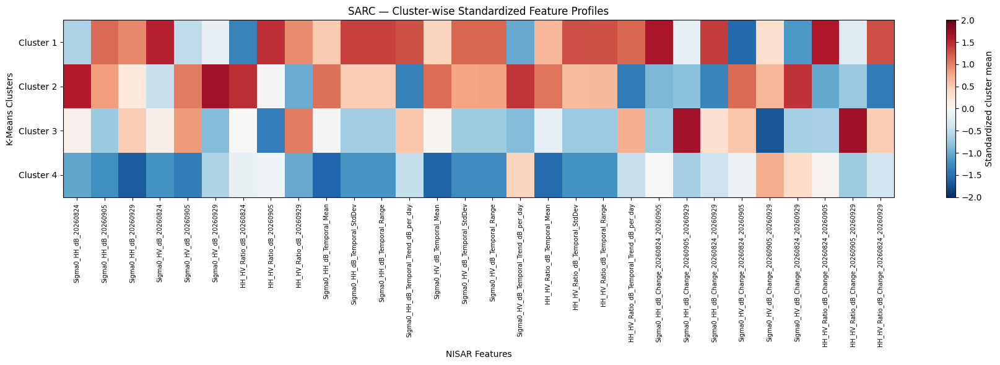

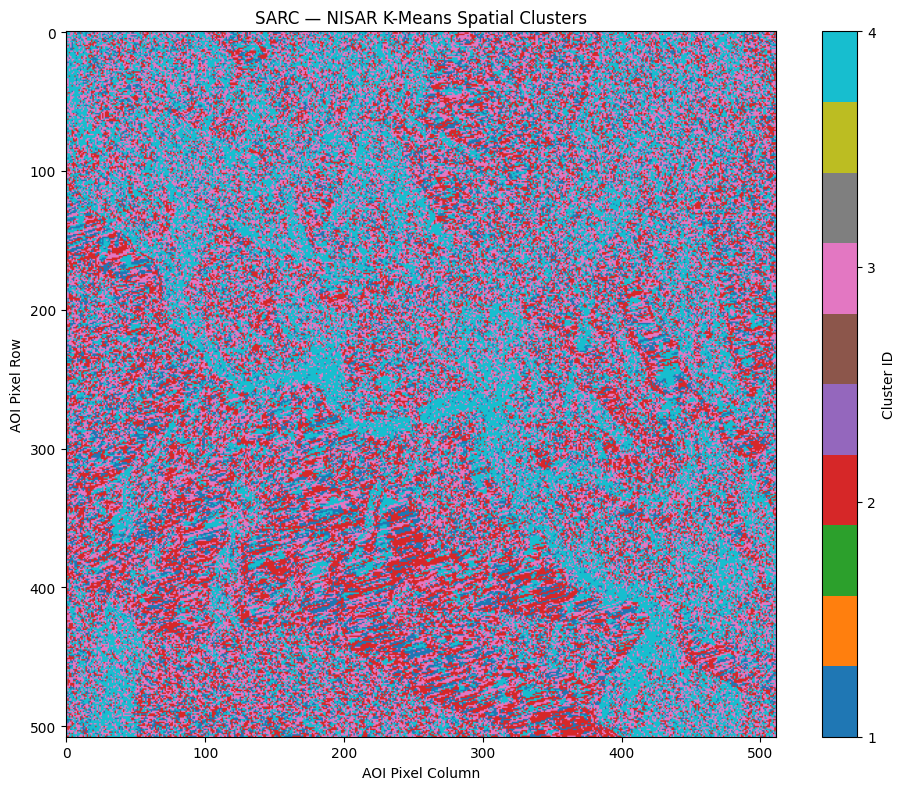

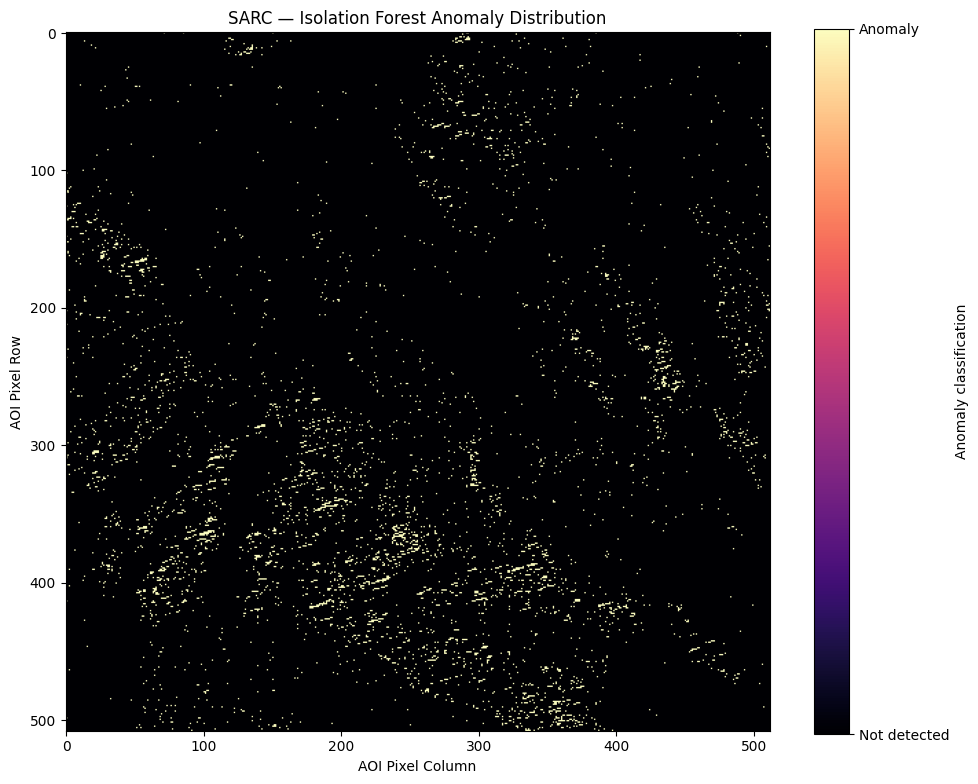

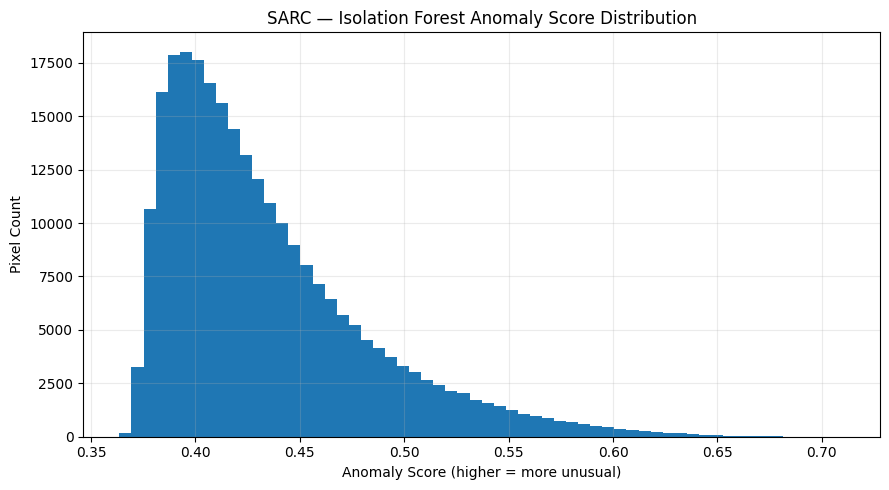

SARC — CLUSTER INTERPRETATION COMPLETE

TOP 10 DIFFERENTIATING FEATURES
                                feature  cluster_mean_range
HH_HV_Ratio_dB_Change_20260824_20260929           13.078833
HH_HV_Ratio_dB_Change_20260824_20260905           11.586453
                HH_HV_Ratio_dB_20260824            8.484995
HH_HV_Ratio_dB_Change_20260905_20260929            7.631476
  Sigma0_HH_dB_Change_20260824_20260929            6.709139
  Sigma0_HV_dB_Change_20260824_20260929            6.369694
                  Sigma0_HH_dB_20260824            6.142097
                HH_HV_Ratio_dB_20260905            5.916457
  Sigma0_HV_dB_Change_20260824_20260905            5.809290
  Sigma0_HH_dB_Change_20260824_20260905            5.777163

ANOMALY DISTRIBUTION BY CLUSTER
 cluster_id  cluster_pixels  anomaly_pixels  anomaly_percent_within_cluster
          1           37139            2158                        5.810603
          2           58582            1974                        3.369636
       

In [ ]:

# ================================================================
# SARC | CELL 19 — CLUSTER INTERPRETATION & VISUALIZATION
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import joblib
import json

BASE = Path("/content/drive/MyDrive/SARC")
ML_DIR = BASE / "processed/nisar/ml_features"
ML_OUT = BASE / "processed/nisar/ml_results"
OUT = BASE / "outputs/maps/nisar/ml_analysis"
META = BASE / "metadata"

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 1. Load feature matrix, trained model and outputs
# ------------------------------------------------

matrix_path = ML_DIR / "SARC_NISAR_ML_Feature_Matrix.npz"
model_path = ML_OUT / "SARC_NISAR_Unsupervised_Models.joblib"
cluster_path = ML_OUT / "SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = ML_OUT / "SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = ML_OUT / "SARC_NISAR_Anomaly_Scores.tif"

with np.load(matrix_path, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    feature_names = data["feature_names"].astype(str)
    valid_mask = data["valid_pixel_mask"].astype(bool)

models = joblib.load(model_path)
scaler = models["scaler"]
kmeans = models["kmeans"]
isolation_forest = models["isolation_forest"]

with rasterio.open(cluster_path) as src:
    cluster_map = src.read(1)
    profile = src.profile.copy()
    crs = src.crs
    transform = src.transform
    shape = (src.height, src.width)

with rasterio.open(anomaly_path) as src:
    anomaly_map = src.read(1)

with rasterio.open(score_path) as src:
    score_map = src.read(1)

assert X.shape == (int(valid_mask.sum()), len(feature_names))
assert cluster_map.shape == shape == valid_mask.shape
assert anomaly_map.shape == shape == score_map.shape
assert np.isin(cluster_map[valid_mask], [1, 2, 3, 4]).all()

# ------------------------------------------------
# 2. Cluster-wise original feature profiles
# ------------------------------------------------

cluster_labels = cluster_map[valid_mask]

profile_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    cluster_features = X[selected]

    row = {
        "cluster_id": cluster_id,
        "pixel_count": int(selected.sum()),
        "coverage_percent": float(selected.mean() * 100)
    }

    for j, feature in enumerate(feature_names):
        row[feature] = float(np.mean(cluster_features[:, j]))

    profile_rows.append(row)

profile_df = pd.DataFrame(profile_rows)
profile_csv = OUT / "SARC_Cluster_Feature_Profiles.csv"
profile_df.to_csv(profile_csv, index=False)

# ------------------------------------------------
# 3. Identify strongest differentiating features
# ------------------------------------------------

feature_cols = list(feature_names)
cluster_means = profile_df.set_index("cluster_id")[feature_cols]

# Feature range across the four cluster means.
feature_separation = (
    cluster_means.max(axis=0) - cluster_means.min(axis=0)
).sort_values(ascending=False)

separation_df = pd.DataFrame({
    "feature": feature_separation.index,
    "cluster_mean_range": feature_separation.values
})

separation_csv = OUT / "SARC_Cluster_Feature_Separation.csv"
separation_df.to_csv(separation_csv, index=False)

# ------------------------------------------------
# 4. Anomaly distribution by cluster
# ------------------------------------------------

anomaly_valid = anomaly_map[valid_mask] == 1

anomaly_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    count = int(selected.sum())
    anomalies = int(anomaly_valid[selected].sum())

    anomaly_rows.append({
        "cluster_id": cluster_id,
        "cluster_pixels": count,
        "anomaly_pixels": anomalies,
        "anomaly_percent_within_cluster": (
            anomalies / count * 100 if count else 0
        )
    })

anomaly_df = pd.DataFrame(anomaly_rows)
anomaly_csv = OUT / "SARC_Anomaly_By_Cluster.csv"
anomaly_df.to_csv(anomaly_csv, index=False)

# ------------------------------------------------
# 5. Feature profile heatmap
#    Each feature standardized across cluster means
# ------------------------------------------------

means = cluster_means.to_numpy()
feature_std = means.std(axis=0)
feature_std[feature_std == 0] = 1

profile_z = (means - means.mean(axis=0)) / feature_std

fig, ax = plt.subplots(figsize=(18, 6))
im = ax.imshow(profile_z, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)

ax.set_yticks(range(4))
ax.set_yticklabels([f"Cluster {i}" for i in range(1, 5)])
ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_title("SARC — Cluster-wise Standardized Feature Profiles")
ax.set_xlabel("NISAR Features")
ax.set_ylabel("K-Means Clusters")

fig.colorbar(im, ax=ax, label="Standardized cluster mean")
fig.tight_layout()

heatmap_path = OUT / "SARC_Cluster_Feature_Heatmap.png"
fig.savefig(heatmap_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. Cluster spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_clusters = np.ma.masked_where(~valid_mask, cluster_map)

im = ax.imshow(display_clusters, cmap="tab10", vmin=1, vmax=4)
ax.set_title("SARC — NISAR K-Means Spatial Clusters")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[1, 2, 3, 4])
cbar.set_label("Cluster ID")

fig.tight_layout()

cluster_png = OUT / "SARC_NISAR_Cluster_Map.png"
cluster_pdf = OUT / "SARC_NISAR_Cluster_Map.pdf"

fig.savefig(cluster_png, dpi=300, bbox_inches="tight")
fig.savefig(cluster_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 7. Anomaly spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_anomalies = np.ma.masked_where(~valid_mask, anomaly_map)

im = ax.imshow(display_anomalies, cmap="magma", vmin=0, vmax=1)
ax.set_title("SARC — Isolation Forest Anomaly Distribution")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[0, 1])
cbar.set_ticklabels(["Not detected", "Anomaly"])
cbar.set_label("Anomaly classification")

fig.tight_layout()

anomaly_png = OUT / "SARC_NISAR_Anomaly_Map.png"
anomaly_pdf = OUT / "SARC_NISAR_Anomaly_Map.pdf"

fig.savefig(anomaly_png, dpi=300, bbox_inches="tight")
fig.savefig(anomaly_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 8. Anomaly score distribution
# ------------------------------------------------

valid_scores = score_map[valid_mask]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(valid_scores, bins=60)
ax.set_title("SARC — Isolation Forest Anomaly Score Distribution")
ax.set_xlabel("Anomaly Score (higher = more unusual)")
ax.set_ylabel("Pixel Count")
ax.grid(alpha=0.25)

fig.tight_layout()

score_histogram = OUT / "SARC_Anomaly_Score_Distribution.png"
fig.savefig(score_histogram, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 9. Integrated interpretation QA
# ------------------------------------------------

assert len(profile_df) == 4
assert int(profile_df["pixel_count"].sum()) == len(X)
assert len(separation_df) == len(feature_names)
assert int(anomaly_df["anomaly_pixels"].sum()) == int(anomaly_valid.sum())
assert np.isfinite(profile_df[feature_cols].to_numpy()).all()
assert np.isfinite(valid_scores).all()

summary = {
    "experiment": "SARC Cluster Interpretation",
    "valid_pixels": int(len(X)),
    "cluster_count": 4,
    "feature_count": len(feature_names),
    "top_10_separating_features": separation_df.head(10).to_dict("records"),
    "anomaly_pixels": int(anomaly_valid.sum()),
    "anomaly_percentage": float(anomaly_valid.mean() * 100),
    "cluster_distribution": profile_df[
        ["cluster_id", "pixel_count", "coverage_percent"]
    ].to_dict("records"),
    "anomaly_by_cluster": anomaly_rows,
    "outputs": {
        "cluster_profiles": str(profile_csv),
        "feature_separation": str(separation_csv),
        "anomaly_by_cluster": str(anomaly_csv),
        "feature_heatmap": str(heatmap_path),
        "cluster_map": str(cluster_png),
        "anomaly_map": str(anomaly_png),
        "score_histogram": str(score_histogram)
    },
    "interpretation_limit": (
        "Feature clusters and anomalies are exploratory SAR patterns, "
        "not confirmed land-cover, flood, damage or hazard classes."
    )
}

summary_path = META / "sarc_cluster_interpretation_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 68)
print("SARC — CLUSTER INTERPRETATION COMPLETE")
print("=" * 68)

print("\nTOP 10 DIFFERENTIATING FEATURES")
print(separation_df.head(10).to_string(index=False))

print("\nANOMALY DISTRIBUTION BY CLUSTER")
print(anomaly_df.to_string(index=False))

print("\nOUTPUT DIRECTORY:", OUT)
print("SUMMARY:", summary_path)
print("\nIntegrated interpretation QA: PASSED")


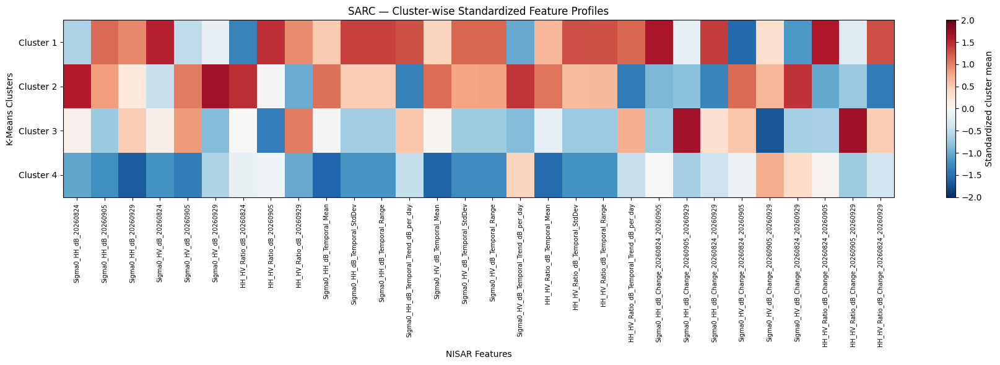

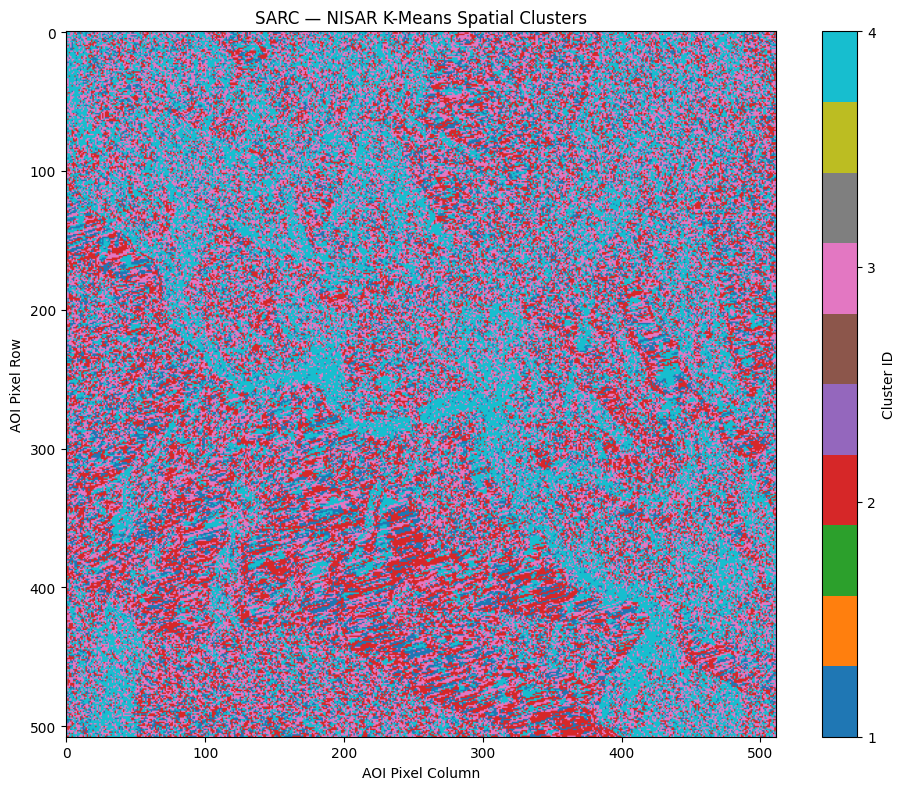

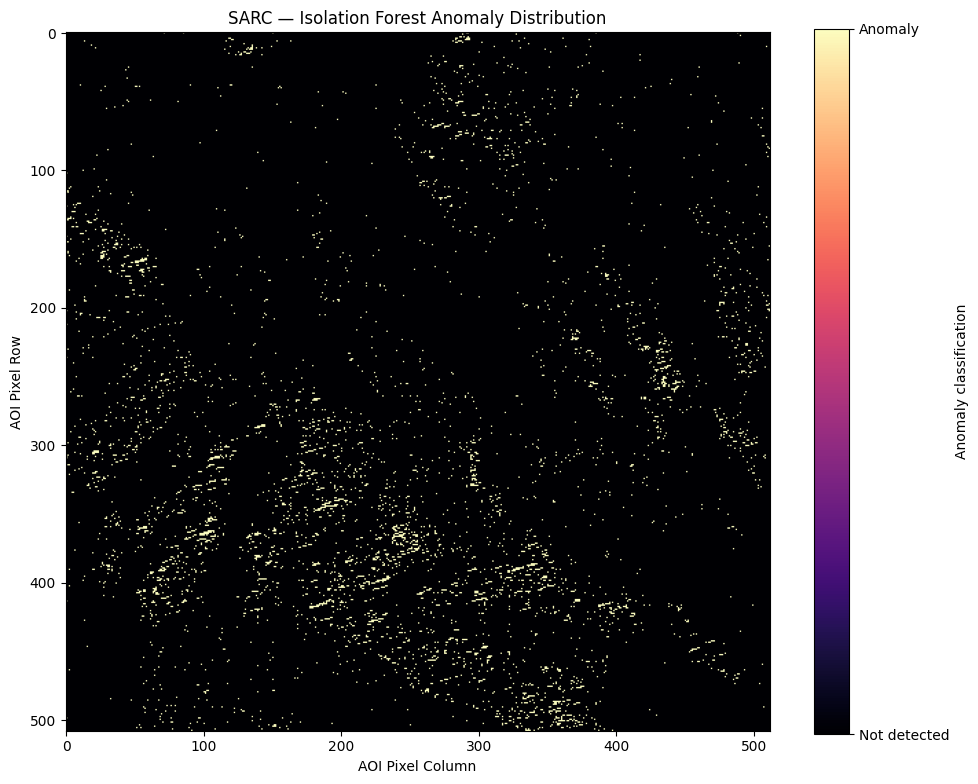

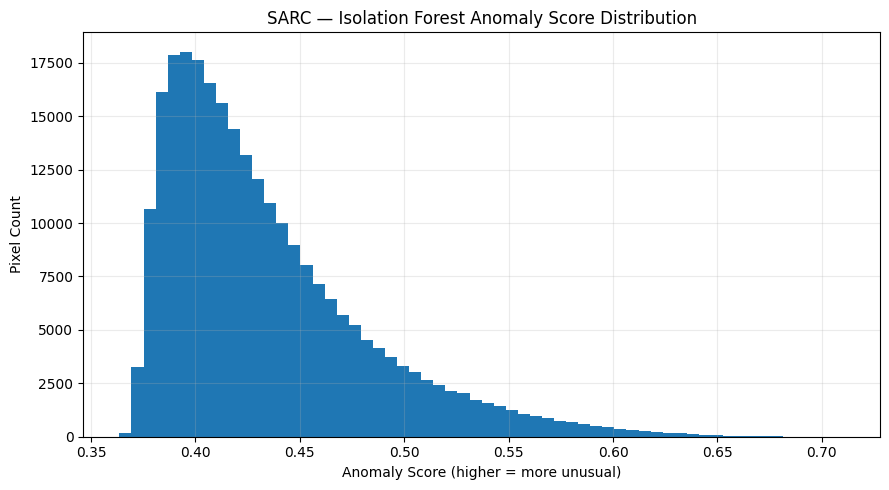

SARC — CLUSTER INTERPRETATION COMPLETE

TOP 10 DIFFERENTIATING FEATURES
                                feature  cluster_mean_range
HH_HV_Ratio_dB_Change_20260824_20260929           13.078833
HH_HV_Ratio_dB_Change_20260824_20260905           11.586453
                HH_HV_Ratio_dB_20260824            8.484995
HH_HV_Ratio_dB_Change_20260905_20260929            7.631476
  Sigma0_HH_dB_Change_20260824_20260929            6.709139
  Sigma0_HV_dB_Change_20260824_20260929            6.369694
                  Sigma0_HH_dB_20260824            6.142097
                HH_HV_Ratio_dB_20260905            5.916457
  Sigma0_HV_dB_Change_20260824_20260905            5.809290
  Sigma0_HH_dB_Change_20260824_20260905            5.777163

ANOMALY DISTRIBUTION BY CLUSTER
 cluster_id  cluster_pixels  anomaly_pixels  anomaly_percent_within_cluster
          1           37139            2158                        5.810603
          2           58582            1974                        3.369636
       

In [ ]:

# ================================================================
# SARC | CELL 19 — CLUSTER INTERPRETATION & VISUALIZATION
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import joblib
import json

BASE = Path("/content/drive/MyDrive/SARC")
ML_DIR = BASE / "processed/nisar/ml_features"
ML_OUT = BASE / "processed/nisar/ml_results"
OUT = BASE / "outputs/maps/nisar/ml_analysis"
META = BASE / "metadata"

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 1. Load feature matrix, trained model and outputs
# ------------------------------------------------

matrix_path = ML_DIR / "SARC_NISAR_ML_Feature_Matrix.npz"
model_path = ML_OUT / "SARC_NISAR_Unsupervised_Models.joblib"
cluster_path = ML_OUT / "SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = ML_OUT / "SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = ML_OUT / "SARC_NISAR_Anomaly_Scores.tif"

with np.load(matrix_path, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    feature_names = data["feature_names"].astype(str)
    valid_mask = data["valid_pixel_mask"].astype(bool)

models = joblib.load(model_path)
scaler = models["scaler"]
kmeans = models["kmeans"]
isolation_forest = models["isolation_forest"]

with rasterio.open(cluster_path) as src:
    cluster_map = src.read(1)
    profile = src.profile.copy()
    crs = src.crs
    transform = src.transform
    shape = (src.height, src.width)

with rasterio.open(anomaly_path) as src:
    anomaly_map = src.read(1)

with rasterio.open(score_path) as src:
    score_map = src.read(1)

assert X.shape == (int(valid_mask.sum()), len(feature_names))
assert cluster_map.shape == shape == valid_mask.shape
assert anomaly_map.shape == shape == score_map.shape
assert np.isin(cluster_map[valid_mask], [1, 2, 3, 4]).all()

# ------------------------------------------------
# 2. Cluster-wise original feature profiles
# ------------------------------------------------

cluster_labels = cluster_map[valid_mask]

profile_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    cluster_features = X[selected]

    row = {
        "cluster_id": cluster_id,
        "pixel_count": int(selected.sum()),
        "coverage_percent": float(selected.mean() * 100)
    }

    for j, feature in enumerate(feature_names):
        row[feature] = float(np.mean(cluster_features[:, j]))

    profile_rows.append(row)

profile_df = pd.DataFrame(profile_rows)
profile_csv = OUT / "SARC_Cluster_Feature_Profiles.csv"
profile_df.to_csv(profile_csv, index=False)

# ------------------------------------------------
# 3. Identify strongest differentiating features
# ------------------------------------------------

feature_cols = list(feature_names)
cluster_means = profile_df.set_index("cluster_id")[feature_cols]

# Feature range across the four cluster means.
feature_separation = (
    cluster_means.max(axis=0) - cluster_means.min(axis=0)
).sort_values(ascending=False)

separation_df = pd.DataFrame({
    "feature": feature_separation.index,
    "cluster_mean_range": feature_separation.values
})

separation_csv = OUT / "SARC_Cluster_Feature_Separation.csv"
separation_df.to_csv(separation_csv, index=False)

# ------------------------------------------------
# 4. Anomaly distribution by cluster
# ------------------------------------------------

anomaly_valid = anomaly_map[valid_mask] == 1

anomaly_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    count = int(selected.sum())
    anomalies = int(anomaly_valid[selected].sum())

    anomaly_rows.append({
        "cluster_id": cluster_id,
        "cluster_pixels": count,
        "anomaly_pixels": anomalies,
        "anomaly_percent_within_cluster": (
            anomalies / count * 100 if count else 0
        )
    })

anomaly_df = pd.DataFrame(anomaly_rows)
anomaly_csv = OUT / "SARC_Anomaly_By_Cluster.csv"
anomaly_df.to_csv(anomaly_csv, index=False)

# ------------------------------------------------
# 5. Feature profile heatmap
#    Each feature standardized across cluster means
# ------------------------------------------------

means = cluster_means.to_numpy()
feature_std = means.std(axis=0)
feature_std[feature_std == 0] = 1

profile_z = (means - means.mean(axis=0)) / feature_std

fig, ax = plt.subplots(figsize=(18, 6))
im = ax.imshow(profile_z, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)

ax.set_yticks(range(4))
ax.set_yticklabels([f"Cluster {i}" for i in range(1, 5)])
ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_title("SARC — Cluster-wise Standardized Feature Profiles")
ax.set_xlabel("NISAR Features")
ax.set_ylabel("K-Means Clusters")

fig.colorbar(im, ax=ax, label="Standardized cluster mean")
fig.tight_layout()

heatmap_path = OUT / "SARC_Cluster_Feature_Heatmap.png"
fig.savefig(heatmap_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. Cluster spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_clusters = np.ma.masked_where(~valid_mask, cluster_map)

im = ax.imshow(display_clusters, cmap="tab10", vmin=1, vmax=4)
ax.set_title("SARC — NISAR K-Means Spatial Clusters")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[1, 2, 3, 4])
cbar.set_label("Cluster ID")

fig.tight_layout()

cluster_png = OUT / "SARC_NISAR_Cluster_Map.png"
cluster_pdf = OUT / "SARC_NISAR_Cluster_Map.pdf"

fig.savefig(cluster_png, dpi=300, bbox_inches="tight")
fig.savefig(cluster_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 7. Anomaly spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_anomalies = np.ma.masked_where(~valid_mask, anomaly_map)

im = ax.imshow(display_anomalies, cmap="magma", vmin=0, vmax=1)
ax.set_title("SARC — Isolation Forest Anomaly Distribution")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[0, 1])
cbar.set_ticklabels(["Not detected", "Anomaly"])
cbar.set_label("Anomaly classification")

fig.tight_layout()

anomaly_png = OUT / "SARC_NISAR_Anomaly_Map.png"
anomaly_pdf = OUT / "SARC_NISAR_Anomaly_Map.pdf"

fig.savefig(anomaly_png, dpi=300, bbox_inches="tight")
fig.savefig(anomaly_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 8. Anomaly score distribution
# ------------------------------------------------

valid_scores = score_map[valid_mask]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(valid_scores, bins=60)
ax.set_title("SARC — Isolation Forest Anomaly Score Distribution")
ax.set_xlabel("Anomaly Score (higher = more unusual)")
ax.set_ylabel("Pixel Count")
ax.grid(alpha=0.25)

fig.tight_layout()

score_histogram = OUT / "SARC_Anomaly_Score_Distribution.png"
fig.savefig(score_histogram, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 9. Integrated interpretation QA
# ------------------------------------------------

assert len(profile_df) == 4
assert int(profile_df["pixel_count"].sum()) == len(X)
assert len(separation_df) == len(feature_names)
assert int(anomaly_df["anomaly_pixels"].sum()) == int(anomaly_valid.sum())
assert np.isfinite(profile_df[feature_cols].to_numpy()).all()
assert np.isfinite(valid_scores).all()

summary = {
    "experiment": "SARC Cluster Interpretation",
    "valid_pixels": int(len(X)),
    "cluster_count": 4,
    "feature_count": len(feature_names),
    "top_10_separating_features": separation_df.head(10).to_dict("records"),
    "anomaly_pixels": int(anomaly_valid.sum()),
    "anomaly_percentage": float(anomaly_valid.mean() * 100),
    "cluster_distribution": profile_df[
        ["cluster_id", "pixel_count", "coverage_percent"]
    ].to_dict("records"),
    "anomaly_by_cluster": anomaly_rows,
    "outputs": {
        "cluster_profiles": str(profile_csv),
        "feature_separation": str(separation_csv),
        "anomaly_by_cluster": str(anomaly_csv),
        "feature_heatmap": str(heatmap_path),
        "cluster_map": str(cluster_png),
        "anomaly_map": str(anomaly_png),
        "score_histogram": str(score_histogram)
    },
    "interpretation_limit": (
        "Feature clusters and anomalies are exploratory SAR patterns, "
        "not confirmed land-cover, flood, damage or hazard classes."
    )
}

summary_path = META / "sarc_cluster_interpretation_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 68)
print("SARC — CLUSTER INTERPRETATION COMPLETE")
print("=" * 68)

print("\nTOP 10 DIFFERENTIATING FEATURES")
print(separation_df.head(10).to_string(index=False))

print("\nANOMALY DISTRIBUTION BY CLUSTER")
print(anomaly_df.to_string(index=False))

print("\nOUTPUT DIRECTORY:", OUT)
print("SUMMARY:", summary_path)
print("\nIntegrated interpretation QA: PASSED")


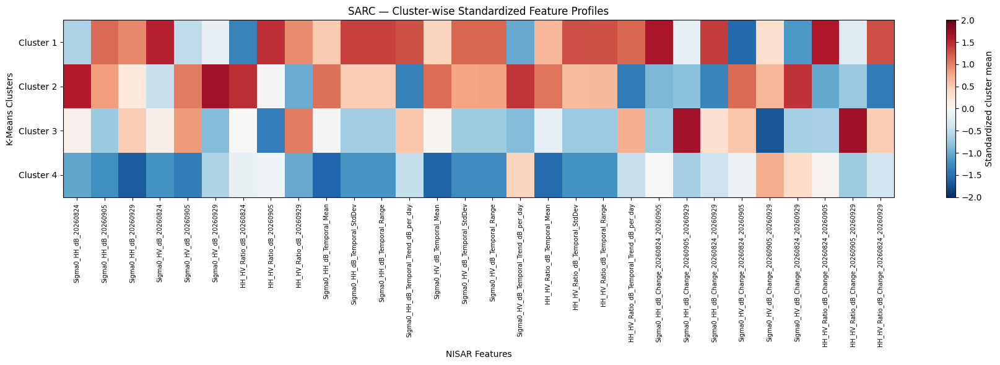

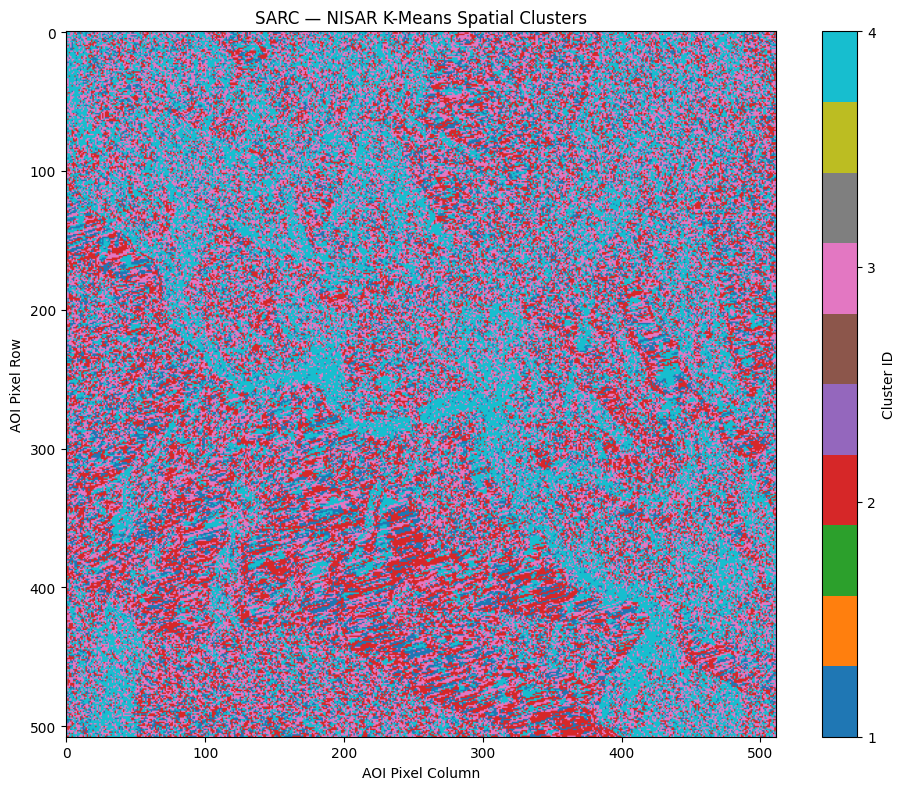

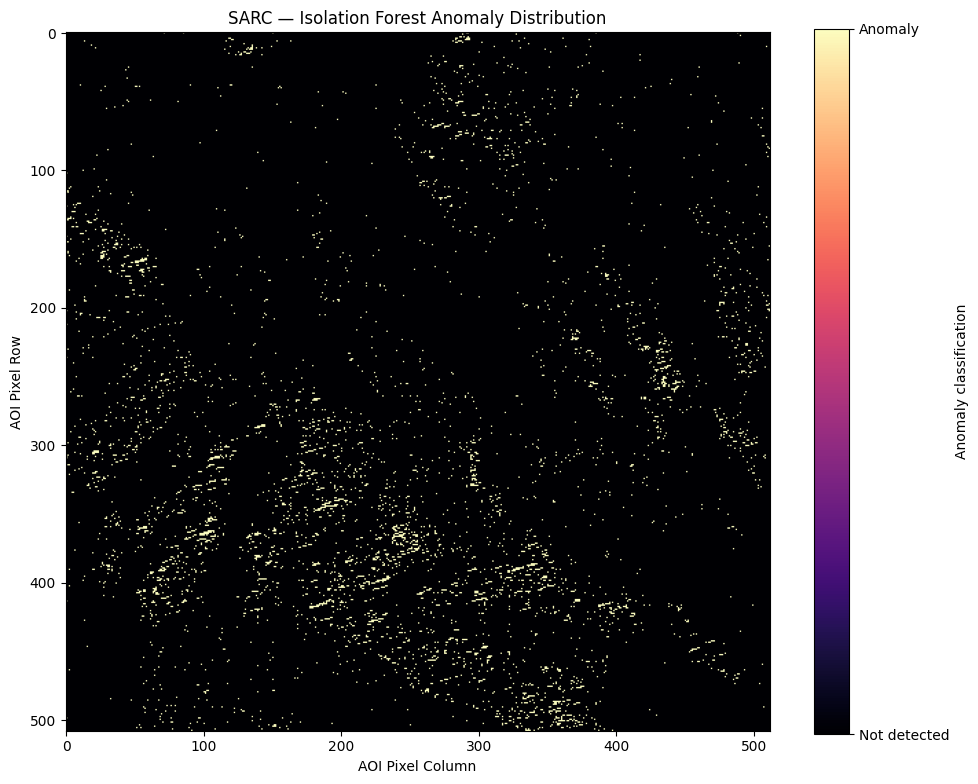

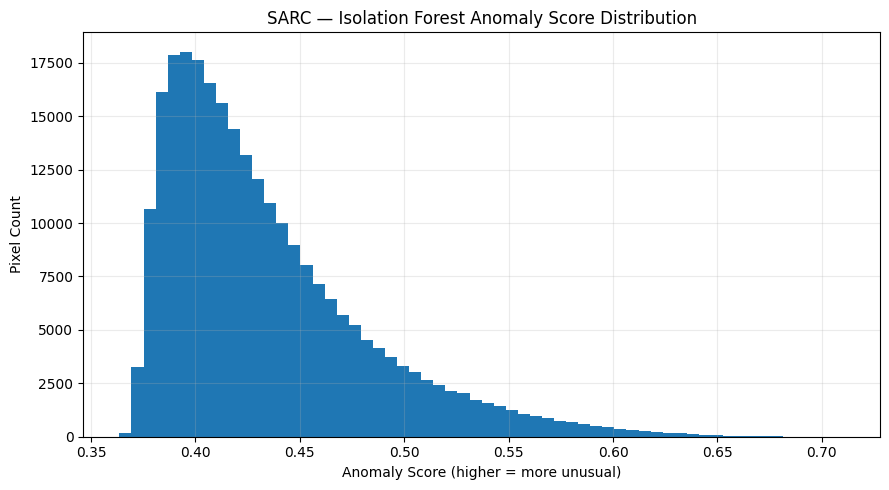

SARC — CLUSTER INTERPRETATION COMPLETE

TOP 10 DIFFERENTIATING FEATURES
                                feature  cluster_mean_range
HH_HV_Ratio_dB_Change_20260824_20260929           13.078833
HH_HV_Ratio_dB_Change_20260824_20260905           11.586453
                HH_HV_Ratio_dB_20260824            8.484995
HH_HV_Ratio_dB_Change_20260905_20260929            7.631476
  Sigma0_HH_dB_Change_20260824_20260929            6.709139
  Sigma0_HV_dB_Change_20260824_20260929            6.369694
                  Sigma0_HH_dB_20260824            6.142097
                HH_HV_Ratio_dB_20260905            5.916457
  Sigma0_HV_dB_Change_20260824_20260905            5.809290
  Sigma0_HH_dB_Change_20260824_20260905            5.777163

ANOMALY DISTRIBUTION BY CLUSTER
 cluster_id  cluster_pixels  anomaly_pixels  anomaly_percent_within_cluster
          1           37139            2158                        5.810603
          2           58582            1974                        3.369636
       

In [ ]:

# ================================================================
# SARC | CELL 19 — CLUSTER INTERPRETATION & VISUALIZATION
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import joblib
import json

BASE = Path("/content/drive/MyDrive/SARC")
ML_DIR = BASE / "processed/nisar/ml_features"
ML_OUT = BASE / "processed/nisar/ml_results"
OUT = BASE / "outputs/maps/nisar/ml_analysis"
META = BASE / "metadata"

OUT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 1. Load feature matrix, trained model and outputs
# ------------------------------------------------

matrix_path = ML_DIR / "SARC_NISAR_ML_Feature_Matrix.npz"
model_path = ML_OUT / "SARC_NISAR_Unsupervised_Models.joblib"
cluster_path = ML_OUT / "SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = ML_OUT / "SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = ML_OUT / "SARC_NISAR_Anomaly_Scores.tif"

with np.load(matrix_path, allow_pickle=False) as data:
    X = data["X"].astype(np.float32)
    feature_names = data["feature_names"].astype(str)
    valid_mask = data["valid_pixel_mask"].astype(bool)

models = joblib.load(model_path)
scaler = models["scaler"]
kmeans = models["kmeans"]
isolation_forest = models["isolation_forest"]

with rasterio.open(cluster_path) as src:
    cluster_map = src.read(1)
    profile = src.profile.copy()
    crs = src.crs
    transform = src.transform
    shape = (src.height, src.width)

with rasterio.open(anomaly_path) as src:
    anomaly_map = src.read(1)

with rasterio.open(score_path) as src:
    score_map = src.read(1)

assert X.shape == (int(valid_mask.sum()), len(feature_names))
assert cluster_map.shape == shape == valid_mask.shape
assert anomaly_map.shape == shape == score_map.shape
assert np.isin(cluster_map[valid_mask], [1, 2, 3, 4]).all()

# ------------------------------------------------
# 2. Cluster-wise original feature profiles
# ------------------------------------------------

cluster_labels = cluster_map[valid_mask]

profile_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    cluster_features = X[selected]

    row = {
        "cluster_id": cluster_id,
        "pixel_count": int(selected.sum()),
        "coverage_percent": float(selected.mean() * 100)
    }

    for j, feature in enumerate(feature_names):
        row[feature] = float(np.mean(cluster_features[:, j]))

    profile_rows.append(row)

profile_df = pd.DataFrame(profile_rows)
profile_csv = OUT / "SARC_Cluster_Feature_Profiles.csv"
profile_df.to_csv(profile_csv, index=False)

# ------------------------------------------------
# 3. Identify strongest differentiating features
# ------------------------------------------------

feature_cols = list(feature_names)
cluster_means = profile_df.set_index("cluster_id")[feature_cols]

# Feature range across the four cluster means.
feature_separation = (
    cluster_means.max(axis=0) - cluster_means.min(axis=0)
).sort_values(ascending=False)

separation_df = pd.DataFrame({
    "feature": feature_separation.index,
    "cluster_mean_range": feature_separation.values
})

separation_csv = OUT / "SARC_Cluster_Feature_Separation.csv"
separation_df.to_csv(separation_csv, index=False)

# ------------------------------------------------
# 4. Anomaly distribution by cluster
# ------------------------------------------------

anomaly_valid = anomaly_map[valid_mask] == 1

anomaly_rows = []

for cluster_id in range(1, 5):
    selected = cluster_labels == cluster_id
    count = int(selected.sum())
    anomalies = int(anomaly_valid[selected].sum())

    anomaly_rows.append({
        "cluster_id": cluster_id,
        "cluster_pixels": count,
        "anomaly_pixels": anomalies,
        "anomaly_percent_within_cluster": (
            anomalies / count * 100 if count else 0
        )
    })

anomaly_df = pd.DataFrame(anomaly_rows)
anomaly_csv = OUT / "SARC_Anomaly_By_Cluster.csv"
anomaly_df.to_csv(anomaly_csv, index=False)

# ------------------------------------------------
# 5. Feature profile heatmap
#    Each feature standardized across cluster means
# ------------------------------------------------

means = cluster_means.to_numpy()
feature_std = means.std(axis=0)
feature_std[feature_std == 0] = 1

profile_z = (means - means.mean(axis=0)) / feature_std

fig, ax = plt.subplots(figsize=(18, 6))
im = ax.imshow(profile_z, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)

ax.set_yticks(range(4))
ax.set_yticklabels([f"Cluster {i}" for i in range(1, 5)])
ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)
ax.set_title("SARC — Cluster-wise Standardized Feature Profiles")
ax.set_xlabel("NISAR Features")
ax.set_ylabel("K-Means Clusters")

fig.colorbar(im, ax=ax, label="Standardized cluster mean")
fig.tight_layout()

heatmap_path = OUT / "SARC_Cluster_Feature_Heatmap.png"
fig.savefig(heatmap_path, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 6. Cluster spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_clusters = np.ma.masked_where(~valid_mask, cluster_map)

im = ax.imshow(display_clusters, cmap="tab10", vmin=1, vmax=4)
ax.set_title("SARC — NISAR K-Means Spatial Clusters")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[1, 2, 3, 4])
cbar.set_label("Cluster ID")

fig.tight_layout()

cluster_png = OUT / "SARC_NISAR_Cluster_Map.png"
cluster_pdf = OUT / "SARC_NISAR_Cluster_Map.pdf"

fig.savefig(cluster_png, dpi=300, bbox_inches="tight")
fig.savefig(cluster_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 7. Anomaly spatial map
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 8))
display_anomalies = np.ma.masked_where(~valid_mask, anomaly_map)

im = ax.imshow(display_anomalies, cmap="magma", vmin=0, vmax=1)
ax.set_title("SARC — Isolation Forest Anomaly Distribution")
ax.set_xlabel("AOI Pixel Column")
ax.set_ylabel("AOI Pixel Row")

cbar = fig.colorbar(im, ax=ax, ticks=[0, 1])
cbar.set_ticklabels(["Not detected", "Anomaly"])
cbar.set_label("Anomaly classification")

fig.tight_layout()

anomaly_png = OUT / "SARC_NISAR_Anomaly_Map.png"
anomaly_pdf = OUT / "SARC_NISAR_Anomaly_Map.pdf"

fig.savefig(anomaly_png, dpi=300, bbox_inches="tight")
fig.savefig(anomaly_pdf, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 8. Anomaly score distribution
# ------------------------------------------------

valid_scores = score_map[valid_mask]

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(valid_scores, bins=60)
ax.set_title("SARC — Isolation Forest Anomaly Score Distribution")
ax.set_xlabel("Anomaly Score (higher = more unusual)")
ax.set_ylabel("Pixel Count")
ax.grid(alpha=0.25)

fig.tight_layout()

score_histogram = OUT / "SARC_Anomaly_Score_Distribution.png"
fig.savefig(score_histogram, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------
# 9. Integrated interpretation QA
# ------------------------------------------------

assert len(profile_df) == 4
assert int(profile_df["pixel_count"].sum()) == len(X)
assert len(separation_df) == len(feature_names)
assert int(anomaly_df["anomaly_pixels"].sum()) == int(anomaly_valid.sum())
assert np.isfinite(profile_df[feature_cols].to_numpy()).all()
assert np.isfinite(valid_scores).all()

summary = {
    "experiment": "SARC Cluster Interpretation",
    "valid_pixels": int(len(X)),
    "cluster_count": 4,
    "feature_count": len(feature_names),
    "top_10_separating_features": separation_df.head(10).to_dict("records"),
    "anomaly_pixels": int(anomaly_valid.sum()),
    "anomaly_percentage": float(anomaly_valid.mean() * 100),
    "cluster_distribution": profile_df[
        ["cluster_id", "pixel_count", "coverage_percent"]
    ].to_dict("records"),
    "anomaly_by_cluster": anomaly_rows,
    "outputs": {
        "cluster_profiles": str(profile_csv),
        "feature_separation": str(separation_csv),
        "anomaly_by_cluster": str(anomaly_csv),
        "feature_heatmap": str(heatmap_path),
        "cluster_map": str(cluster_png),
        "anomaly_map": str(anomaly_png),
        "score_histogram": str(score_histogram)
    },
    "interpretation_limit": (
        "Feature clusters and anomalies are exploratory SAR patterns, "
        "not confirmed land-cover, flood, damage or hazard classes."
    )
}

summary_path = META / "sarc_cluster_interpretation_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

print("=" * 68)
print("SARC — CLUSTER INTERPRETATION COMPLETE")
print("=" * 68)

print("\nTOP 10 DIFFERENTIATING FEATURES")
print(separation_df.head(10).to_string(index=False))

print("\nANOMALY DISTRIBUTION BY CLUSTER")
print(anomaly_df.to_string(index=False))

print("\nOUTPUT DIRECTORY:", OUT)
print("SUMMARY:", summary_path)
print("\nIntegrated interpretation QA: PASSED")


In [ ]:

# ================================================================
# SARC | RUNTIME CHECKPOINT & RECOVERY
# Run after Google Drive initialization, before Cell 17
# ================================================================

import os
import sys
import gc
import json
import importlib
import subprocess
from pathlib import Path

print("=" * 65)
print("SARC — RUNTIME CHECKPOINT")
print("=" * 65)

# 1. Runtime and Drive validation
BASE = Path("/content/drive/MyDrive/SARC")

if not os.path.ismount("/content/drive"):
    raise RuntimeError("Google Drive is not mounted. Run Drive initialization first.")

if not BASE.is_dir():
    raise RuntimeError(f"SARC directory unavailable: {BASE}")

print("Python:", sys.version.split()[0])
print("Drive: CONNECTED")
print("Project directory: AVAILABLE")

# 2. Required package validation and recovery
required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "rasterio": "rasterio",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "joblib": "joblib",
    "h5py": "h5py"
}

missing = []

for module, package in required.items():
    try:
        importlib.import_module(module)
    except ImportError:
        missing.append(package)

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *missing
    ])
    importlib.invalidate_caches()

# 3. Re-import dependencies after recovery
import numpy as np
import pandas as pd
import rasterio
import sklearn
import matplotlib
import joblib
import h5py

# 4. Required SARC directory validation
directories = [
    BASE / "processed/nisar/preprocessed",
    BASE / "processed/nisar/change_analysis",
    BASE / "processed/nisar/temporal_statistics",
    BASE / "processed/nisar/ml_features",
    BASE / "processed/nisar/ml_results",
    BASE / "metadata",
    BASE / "outputs/maps/nisar/ml_analysis"
]

for folder in directories:
    folder.mkdir(parents=True, exist_ok=True)

# 5. Check critical existing outputs
critical_files = {
    "Feature stack": BASE / "processed/nisar/ml_features/SARC_NISAR_ML_Feature_Stack.tif",
    "Feature matrix": BASE / "processed/nisar/ml_features/SARC_NISAR_ML_Feature_Matrix.npz",
    "Trained ML models": BASE / "processed/nisar/ml_results/SARC_NISAR_Unsupervised_Models.joblib",
    "Cluster raster": BASE / "processed/nisar/ml_results/SARC_NISAR_KMeans_Clusters.tif",
    "Anomaly raster": BASE / "processed/nisar/ml_results/SARC_NISAR_IsolationForest_Anomalies.tif",
    "Anomaly score raster": BASE / "processed/nisar/ml_results/SARC_NISAR_Anomaly_Scores.tif"
}

missing_outputs = []

for name, path in critical_files.items():
    if not path.is_file() or path.stat().st_size == 0:
        missing_outputs.append(name)

# 6. Validate feature matrix without retraining
matrix_path = critical_files["Feature matrix"]

if matrix_path.exists():
    with np.load(matrix_path, allow_pickle=False) as data:
        X = data["X"]
        feature_names = data["feature_names"]
        valid_mask = data["valid_pixel_mask"]

    assert X.ndim == 2
    assert X.shape[1] == len(feature_names)
    assert X.shape[0] == int(valid_mask.sum())
    assert np.isfinite(X).all()

    print("Feature matrix:", X.shape, "PASSED")
    del X, feature_names, valid_mask
else:
    print("WARNING: Feature matrix missing.")

# 7. Validate existing trained models
model_path = critical_files["Trained ML models"]

if model_path.exists():
    models = joblib.load(model_path)
    assert all(k in models for k in [
        "scaler", "kmeans", "isolation_forest", "feature_names"
    ])
    print("Saved ML models: PASSED")
    del models

# 8. System resource snapshot
gc.collect()

try:
    import psutil
    memory = psutil.virtual_memory()
    ram_total = round(memory.total / (1024**3), 2)
    ram_available = round(memory.available / (1024**3), 2)
except ImportError:
    ram_total = ram_available = None

# 9. Save checkpoint report
report = {
    "checkpoint": "SARC Runtime Recovery",
    "python": sys.version,
    "drive_connected": True,
    "project_directory": str(BASE),
    "missing_outputs": missing_outputs,
    "ram_total_gb": ram_total,
    "ram_available_gb": ram_available,
    "dependencies": "PASSED",
    "status": "READY" if not missing_outputs else "INCOMPLETE"
}

checkpoint_path = BASE / "metadata/sarc_runtime_checkpoint.json"

with open(checkpoint_path, "w") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 65)
print("SARC CHECKPOINT RESULT")
print("=" * 65)
print("Dependencies: PASSED")
print("Drive access: PASSED")
print("Project folders: READY")
print("Missing critical outputs:", missing_outputs)
print("Available RAM (GB):", ram_available)
print("Checkpoint:", checkpoint_path)

if missing_outputs:
    print("\nWARNING: Some previous outputs are missing.")
    print("Run the corresponding processing cells before Cell 19.")
else:
    print("\nALL CHECKPOINTS PASSED — READY FOR CELL 19")


SARC — RUNTIME CHECKPOINT
Python: 3.13.16
Drive: CONNECTED
Project directory: AVAILABLE
Feature matrix: (260096, 30) PASSED
Saved ML models: PASSED

SARC CHECKPOINT RESULT
Dependencies: PASSED
Drive access: PASSED
Project folders: READY
Missing critical outputs: []
Available RAM (GB): 8.98
Checkpoint: /content/drive/MyDrive/SARC/metadata/sarc_runtime_checkpoint.json

ALL CHECKPOINTS PASSED — READY FOR CELL 19


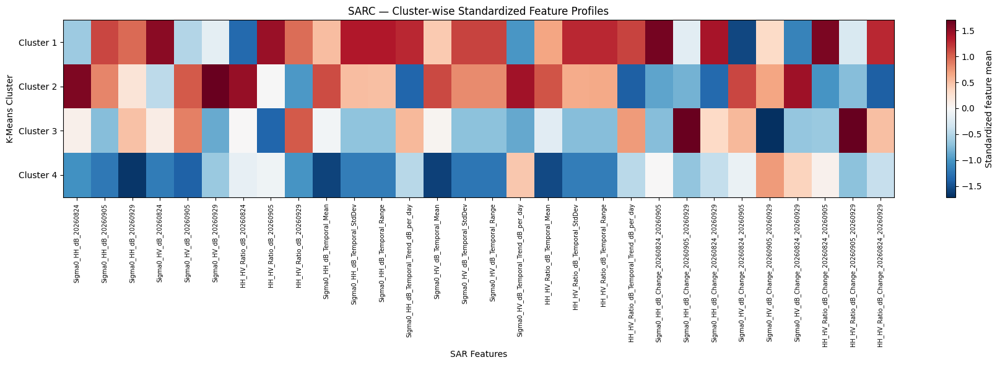

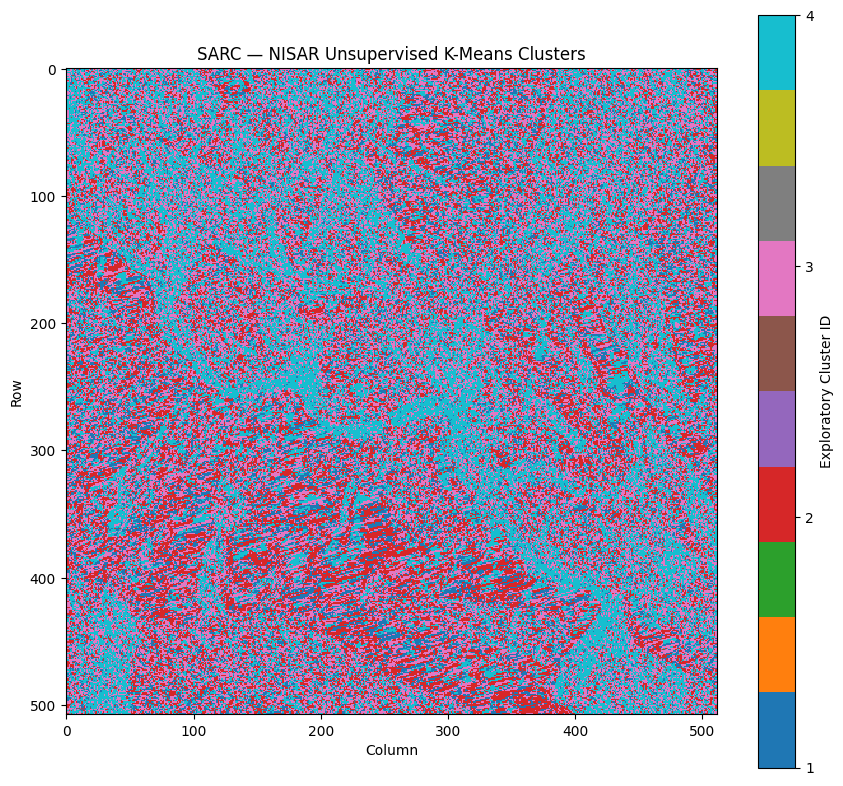

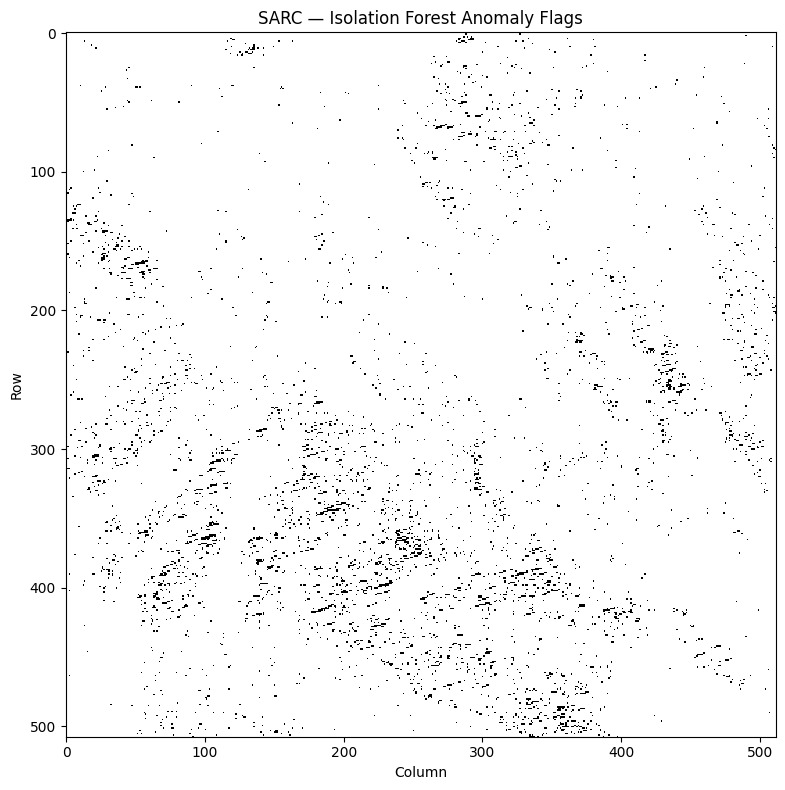

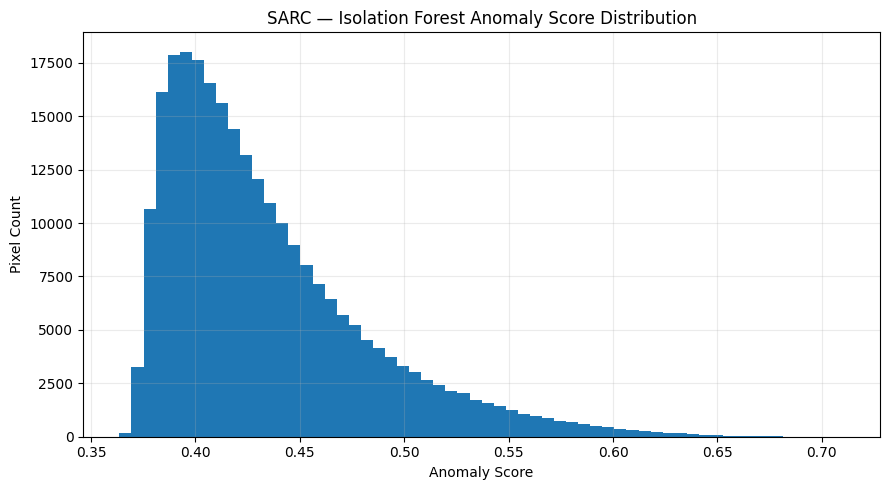


SARC — CLUSTER INTERPRETATION COMPLETE
Pixels: 260,096
Features: 30
Clusters: 4
Anomaly pixels: 5,202
Anomaly rate: 2.00%

TOP 10 CLUSTER-SEPARATING FEATURES
                                feature  cluster_mean_range
HH_HV_Ratio_dB_Change_20260824_20260929           13.078833
HH_HV_Ratio_dB_Change_20260824_20260905           11.586453
                HH_HV_Ratio_dB_20260824            8.484995
HH_HV_Ratio_dB_Change_20260905_20260929            7.631476
  Sigma0_HH_dB_Change_20260824_20260929            6.709139
  Sigma0_HV_dB_Change_20260824_20260929            6.369694
                  Sigma0_HH_dB_20260824            6.142097
                HH_HV_Ratio_dB_20260905            5.916457
  Sigma0_HV_dB_Change_20260824_20260905            5.809290
  Sigma0_HH_dB_Change_20260824_20260905            5.777163

ANOMALY DISTRIBUTION BY CLUSTER
 cluster  total_pixels  anomaly_pixels  anomaly_percentage
       1         37139            2158            5.810603
       2         58582        

In [ ]:

# ================================================================
# SARC — CELL 19: CLUSTER INTERPRETATION & VISUAL ANALYSIS
# ================================================================

import os
import json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

BASE = "/content/drive/MyDrive/SARC"

FEATURE_DIR = f"{BASE}/processed/nisar/ml_features"
RESULT_DIR = f"{BASE}/processed/nisar/ml_results"
MAP_DIR = f"{BASE}/outputs/maps/nisar/ml_analysis"
META_DIR = f"{BASE}/metadata"

os.makedirs(MAP_DIR, exist_ok=True)

# ------------------------------------------------
# 1. LOAD INPUTS
# ------------------------------------------------

matrix_path = f"{FEATURE_DIR}/SARC_NISAR_ML_Feature_Matrix.npz"
cluster_path = f"{RESULT_DIR}/SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = f"{RESULT_DIR}/SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = f"{RESULT_DIR}/SARC_NISAR_Anomaly_Scores.tif"

for path in [matrix_path, cluster_path, anomaly_path, score_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required input missing: {path}")

npz = np.load(matrix_path, allow_pickle=True)
X = np.asarray(npz["X"], dtype=np.float32)

with rasterio.open(cluster_path) as src:
    clusters = src.read(1)
    profile = src.profile.copy()
    height, width = src.height, src.width
    cluster_crs = src.crs
    cluster_transform = src.transform

with rasterio.open(anomaly_path) as src:
    anomalies = src.read(1)

with rasterio.open(score_path) as src:
    anomaly_scores = src.read(1)

# ------------------------------------------------
# 2. INTEGRATED INPUT QA
# ------------------------------------------------

if X.ndim != 2 or X.shape[1] != 30:
    raise RuntimeError(f"Expected 30 features; received {X.shape}")

if X.shape[0] != height * width:
    raise RuntimeError("Feature matrix and raster dimensions do not match.")

if clusters.shape != (height, width):
    raise RuntimeError("Cluster raster dimensions mismatch.")

if anomalies.shape != (height, width):
    raise RuntimeError("Anomaly raster dimensions mismatch.")

if anomaly_scores.shape != (height, width):
    raise RuntimeError("Anomaly score raster dimensions mismatch.")

if not np.isfinite(X).all():
    raise RuntimeError("Feature matrix contains non-finite values.")

cluster_ids = np.unique(clusters)
cluster_ids = cluster_ids[cluster_ids > 0]

if len(cluster_ids) < 2:
    raise RuntimeError("Insufficient valid clusters for interpretation.")

feature_names = [
    f"Feature_{i+1:02d}" for i in range(X.shape[1])
]

# Use existing feature metadata if available
band_meta_path = f"{FEATURE_DIR}/feature_band_metadata.csv"

if os.path.exists(band_meta_path):
    band_meta = pd.read_csv(band_meta_path)
    possible_name_cols = [
        c for c in band_meta.columns
        if c.lower() in ["feature", "feature_name", "band_name", "name"]
    ]
    if possible_name_cols and len(band_meta) == X.shape[1]:
        feature_names = band_meta[possible_name_cols[0]].astype(str).tolist()

# ------------------------------------------------
# 3. CLUSTER-WISE FEATURE PROFILES
# ------------------------------------------------

cluster_flat = clusters.reshape(-1)
rows = []

for cluster_id in cluster_ids:
    mask = cluster_flat == cluster_id
    values = X[mask]

    row = {
        "cluster": int(cluster_id),
        "pixel_count": int(mask.sum()),
        "pixel_percentage": float(mask.mean() * 100)
    }

    row.update({
        feature_names[i]: float(np.mean(values[:, i]))
        for i in range(X.shape[1])
    })

    rows.append(row)

profiles_df = pd.DataFrame(rows)

profiles_df.to_csv(
    f"{RESULT_DIR}/SARC_Cluster_Feature_Profiles.csv",
    index=False
)

# ------------------------------------------------
# 4. FEATURE SEPARATION RANKING
# ------------------------------------------------

feature_columns = feature_names

separation = (
    profiles_df[feature_columns].max(axis=0)
    - profiles_df[feature_columns].min(axis=0)
)

# Pandas-version-compatible Series conversion
separation_df = (
    separation.rename("cluster_mean_range")
    .rename_axis("feature")
    .reset_index()
)

separation_df = separation_df.sort_values(
    "cluster_mean_range",
    ascending=False
).reset_index(drop=True)

separation_df.to_csv(
    f"{RESULT_DIR}/SARC_Cluster_Feature_Separation.csv",
    index=False
)

# ------------------------------------------------
# 5. ANOMALY DISTRIBUTION BY CLUSTER
# ------------------------------------------------

anomaly_rows = []

for cluster_id in cluster_ids:
    cluster_mask = clusters == cluster_id
    total = int(cluster_mask.sum())
    anomaly_count = int(
        np.count_nonzero((anomalies == 1) & cluster_mask)
    )

    anomaly_rows.append({
        "cluster": int(cluster_id),
        "total_pixels": total,
        "anomaly_pixels": anomaly_count,
        "anomaly_percentage": (
            anomaly_count / total * 100 if total else 0
        )
    })

anomaly_df = pd.DataFrame(anomaly_rows)

anomaly_df.to_csv(
    f"{RESULT_DIR}/SARC_Anomaly_By_Cluster.csv",
    index=False
)

# ------------------------------------------------
# 6. CLUSTER FEATURE HEATMAP
# ------------------------------------------------

heatmap_data = profiles_df[feature_columns].to_numpy(dtype=float)

# Standardize each feature across clusters for visualization
means = heatmap_data.mean(axis=0)
stds = heatmap_data.std(axis=0)
stds[stds == 0] = 1

heatmap_scaled = (heatmap_data - means) / stds

fig, ax = plt.subplots(figsize=(18, 6))

im = ax.imshow(
    heatmap_scaled,
    aspect="auto",
    cmap="RdBu_r"
)

ax.set_yticks(range(len(cluster_ids)))
ax.set_yticklabels([f"Cluster {c}" for c in cluster_ids])

ax.set_xticks(range(len(feature_names)))
ax.set_xticklabels(feature_names, rotation=90, fontsize=7)

ax.set_title("SARC — Cluster-wise Standardized Feature Profiles")
ax.set_xlabel("SAR Features")
ax.set_ylabel("K-Means Cluster")

fig.colorbar(im, ax=ax, label="Standardized feature mean")
plt.tight_layout()

plt.savefig(
    f"{MAP_DIR}/SARC_Cluster_Feature_Heatmap.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------
# 7. CLUSTER MAP
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

im = ax.imshow(
    np.ma.masked_where(clusters <= 0, clusters),
    cmap="tab10",
    interpolation="nearest"
)

ax.set_title("SARC — NISAR Unsupervised K-Means Clusters")
ax.set_xlabel("Column")
ax.set_ylabel("Row")

cbar = fig.colorbar(im, ax=ax, ticks=cluster_ids)
cbar.set_label("Exploratory Cluster ID")

plt.tight_layout()
plt.savefig(
    f"{MAP_DIR}/SARC_NISAR_Cluster_Map.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------
# 8. ANOMALY MAP
# ------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

ax.imshow(
    anomalies,
    cmap="gray_r",
    interpolation="nearest"
)

ax.set_title("SARC — Isolation Forest Anomaly Flags")
ax.set_xlabel("Column")
ax.set_ylabel("Row")

plt.tight_layout()
plt.savefig(
    f"{MAP_DIR}/SARC_NISAR_Anomaly_Map.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------
# 9. ANOMALY SCORE DISTRIBUTION
# ------------------------------------------------

valid_scores = anomaly_scores[np.isfinite(anomaly_scores)]

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(valid_scores, bins=60)
ax.set_title("SARC — Isolation Forest Anomaly Score Distribution")
ax.set_xlabel("Anomaly Score")
ax.set_ylabel("Pixel Count")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    f"{MAP_DIR}/SARC_Anomaly_Score_Distribution.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------
# 10. SUMMARY + INTEGRATED QA
# ------------------------------------------------

summary = {
    "project": "SARC",
    "analysis": "Unsupervised Cluster Interpretation",
    "input_pixels": int(X.shape[0]),
    "feature_count": int(X.shape[1]),
    "cluster_count": int(len(cluster_ids)),
    "cluster_ids": [int(c) for c in cluster_ids],
    "anomaly_pixels": int(np.count_nonzero(anomalies == 1)),
    "anomaly_percentage": float(
        np.count_nonzero(anomalies == 1) / anomalies.size * 100
    ),
    "crs": str(cluster_crs),
    "raster_dimensions": [int(height), int(width)],
    "top_separating_features": separation_df.head(10).to_dict(
        orient="records"
    ),
    "outputs": [
        "SARC_Cluster_Feature_Profiles.csv",
        "SARC_Cluster_Feature_Separation.csv",
        "SARC_Anomaly_By_Cluster.csv",
        "SARC_Cluster_Feature_Heatmap.png",
        "SARC_NISAR_Cluster_Map.png",
        "SARC_NISAR_Anomaly_Map.png",
        "SARC_Anomaly_Score_Distribution.png"
    ]
}

summary_path = f"{META_DIR}/sarc_cluster_interpretation_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# Confirm required outputs
required_outputs = [
    f"{RESULT_DIR}/SARC_Cluster_Feature_Profiles.csv",
    f"{RESULT_DIR}/SARC_Cluster_Feature_Separation.csv",
    f"{RESULT_DIR}/SARC_Anomaly_By_Cluster.csv",
    f"{MAP_DIR}/SARC_Cluster_Feature_Heatmap.png",
    f"{MAP_DIR}/SARC_NISAR_Cluster_Map.png",
    f"{MAP_DIR}/SARC_NISAR_Anomaly_Map.png",
    f"{MAP_DIR}/SARC_Anomaly_Score_Distribution.png",
    summary_path
]

missing = [p for p in required_outputs if not os.path.isfile(p)]

if missing:
    raise RuntimeError(f"Output QA failed. Missing: {missing}")

print("\n" + "=" * 65)
print("SARC — CLUSTER INTERPRETATION COMPLETE")
print("=" * 65)
print(f"Pixels: {X.shape[0]:,}")
print(f"Features: {X.shape[1]}")
print(f"Clusters: {len(cluster_ids)}")
print(f"Anomaly pixels: {summary['anomaly_pixels']:,}")
print(f"Anomaly rate: {summary['anomaly_percentage']:.2f}%")

print("\nTOP 10 CLUSTER-SEPARATING FEATURES")
print(separation_df.head(10).to_string(index=False))

print("\nANOMALY DISTRIBUTION BY CLUSTER")
print(anomaly_df.to_string(index=False))

print("\nIntegrated QA: PASSED")
print(f"Summary: {summary_path}")
print("=" * 65)


In [ ]:

# ================================================================
# SARC — CELL 20: SPATIAL COHERENCE & CONNECTED COMPONENT ANALYSIS
# ================================================================

import os
import numpy as np
import pandas as pd
import rasterio
from scipy import ndimage

BASE = "/content/drive/MyDrive/SARC"
RESULT_DIR = f"{BASE}/processed/nisar/ml_results"
META_DIR = f"{BASE}/metadata"

cluster_path = f"{RESULT_DIR}/SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = f"{RESULT_DIR}/SARC_NISAR_IsolationForest_Anomalies.tif"

output_path = f"{RESULT_DIR}/SARC_Spatial_Coherence_Analysis.csv"

# ------------------------------------------------
# 1. LOAD AND VALIDATE RASTERS
# ------------------------------------------------

with rasterio.open(cluster_path) as src:
    clusters = src.read(1)
    profile = src.profile.copy()

with rasterio.open(anomaly_path) as src:
    anomalies = src.read(1)

if clusters.shape != anomalies.shape:
    raise RuntimeError("Cluster and anomaly raster dimensions mismatch.")

valid = clusters > 0

if not valid.any():
    raise RuntimeError("No valid cluster pixels found.")

if not np.isin(anomalies[valid], [0, 1]).all():
    raise RuntimeError("Anomaly raster contains unexpected values.")

cluster_ids = np.unique(clusters[valid])
structure = np.ones((3, 3), dtype=np.uint8)  # 8-connectivity

# ------------------------------------------------
# 2. CONNECTED COMPONENT METRICS
# ------------------------------------------------

def component_metrics(mask, label):
    labels, component_count = ndimage.label(
        mask,
        structure=structure
    )

    if component_count == 0:
        return {
            "region": label,
            "pixel_count": int(mask.sum()),
            "component_count": 0,
            "largest_component_pixels": 0,
            "largest_component_share_pct": 0.0,
            "median_component_pixels": 0.0,
            "components_ge_10_pixels": 0,
            "components_ge_25_pixels": 0,
            "pixels_in_components_ge_10_pct": 0.0,
            "pixels_in_components_ge_25_pct": 0.0
        }

    sizes = np.bincount(labels.ravel())[1:]
    largest = int(sizes.max())

    ge10 = sizes[sizes >= 10]
    ge25 = sizes[sizes >= 25]

    total = int(mask.sum())

    return {
        "region": label,
        "pixel_count": total,
        "component_count": int(component_count),
        "largest_component_pixels": largest,
        "largest_component_share_pct": largest / total * 100,
        "median_component_pixels": float(np.median(sizes)),
        "components_ge_10_pixels": int(len(ge10)),
        "components_ge_25_pixels": int(len(ge25)),
        "pixels_in_components_ge_10_pct": (
            float(ge10.sum() / total * 100) if total else 0.0
        ),
        "pixels_in_components_ge_25_pct": (
            float(ge25.sum() / total * 100) if total else 0.0
        )
    }

# ------------------------------------------------
# 3. CLUSTER SPATIAL COHERENCE
# ------------------------------------------------

rows = []

for cluster_id in cluster_ids:
    mask = (clusters == cluster_id) & valid

    rows.append(
        component_metrics(mask, f"Cluster_{int(cluster_id)}")
    )

# ------------------------------------------------
# 4. ANOMALY SPATIAL COHERENCE
# ------------------------------------------------

anomaly_mask = (anomalies == 1) & valid

rows.append(
    component_metrics(anomaly_mask, "All_Anomalies")
)

# ------------------------------------------------
# 5. SAVE RESULTS
# ------------------------------------------------

coherence_df = pd.DataFrame(rows)

coherence_df.to_csv(output_path, index=False)

# ------------------------------------------------
# 6. INTEGRATED QA
# ------------------------------------------------

if len(coherence_df) != len(cluster_ids) + 1:
    raise RuntimeError("Spatial coherence output row count mismatch.")

if int(coherence_df.iloc[-1]["pixel_count"]) != int(anomaly_mask.sum()):
    raise RuntimeError("Anomaly component pixel count mismatch.")

if not os.path.isfile(output_path):
    raise RuntimeError("Spatial coherence CSV was not created.")

print("\n" + "=" * 70)
print("SARC — SPATIAL COHERENCE ANALYSIS COMPLETE")
print("=" * 70)

print("Connectivity: 8-neighbour")
print("Cluster count:", len(cluster_ids))
print("Anomaly pixels:", int(anomaly_mask.sum()))

print("\nSPATIAL CONNECTED-COMPONENT RESULTS")
print(coherence_df.to_string(index=False))

print("\nIntegrated QA: PASSED")
print("Output:", output_path)
print("=" * 70)



SARC — SPATIAL COHERENCE ANALYSIS COMPLETE
Connectivity: 8-neighbour
Cluster count: 4
Anomaly pixels: 5202

SPATIAL CONNECTED-COMPONENT RESULTS
       region  pixel_count  component_count  largest_component_pixels  largest_component_share_pct  median_component_pixels  components_ge_10_pixels  components_ge_25_pixels  pixels_in_components_ge_10_pct  pixels_in_components_ge_25_pct
    Cluster_1        37139            12294                       166                     0.446969                      2.0                      613                      112                       31.462883                       12.520531
    Cluster_2        58582            10639                      1343                     2.292513                      2.0                     1206                      347                       61.250896                       39.445563
    Cluster_3        82195             8994                       523                     0.636292                      2.0                  

In [ ]:

# ================================================================
# SARC — RUNTIME CHECKPOINT
# ================================================================

import os
import json
import numpy as np
import rasterio
from datetime import datetime, timezone

BASE = "/content/drive/MyDrive/SARC"

required_files = {
    "NISAR feature matrix":
        f"{BASE}/processed/nisar/ml_features/SARC_NISAR_ML_Feature_Matrix.npz",
    "NISAR feature stack":
        f"{BASE}/processed/nisar/ml_features/SARC_NISAR_ML_Feature_Stack.tif",
    "K-Means clusters":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_KMeans_Clusters.tif",
    "Isolation Forest anomalies":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_IsolationForest_Anomalies.tif",
    "Anomaly scores":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_Anomaly_Scores.tif",
    "Cluster profiles":
        f"{BASE}/processed/nisar/ml_results/SARC_Cluster_Feature_Profiles.csv",
    "Cluster separation":
        f"{BASE}/processed/nisar/ml_results/SARC_Cluster_Feature_Separation.csv",
    "Anomaly by cluster":
        f"{BASE}/processed/nisar/ml_results/SARC_Anomaly_By_Cluster.csv",
    "Spatial coherence":
        f"{BASE}/processed/nisar/ml_results/SARC_Spatial_Coherence_Analysis.csv",
    "Feature engineering metadata":
        f"{BASE}/metadata/nisar_ml_feature_engineering_summary.json",
    "Cluster interpretation metadata":
        f"{BASE}/metadata/sarc_cluster_interpretation_summary.json"
}

if not os.path.isdir(BASE):
    raise RuntimeError(
        "SARC Drive folder not accessible. Check Drive mount cell."
    )

missing = [
    name for name, path in required_files.items()
    if not os.path.isfile(path)
]

if missing:
    raise RuntimeError(
        "Checkpoint failed. Missing files:\n" + "\n".join(missing)
    )

# Validate core ML inputs and raster alignment
matrix = np.load(
    required_files["NISAR feature matrix"],
    allow_pickle=True
)
X = matrix["X"]

with rasterio.open(required_files["K-Means clusters"]) as src:
    cluster_shape = (src.height, src.width)
    cluster_crs = str(src.crs)
    cluster_transform = src.transform
    cluster_count = len(np.unique(src.read(1))) - 1

with rasterio.open(required_files["Isolation Forest anomalies"]) as src:
    anomaly_shape = (src.height, src.width)

with rasterio.open(required_files["Anomaly scores"]) as src:
    score_shape = (src.height, src.width)

if X.shape != (260096, 30):
    raise RuntimeError(f"Unexpected feature matrix shape: {X.shape}")

if cluster_shape != (508, 512):
    raise RuntimeError(f"Unexpected cluster raster shape: {cluster_shape}")

if not (cluster_shape == anomaly_shape == score_shape):
    raise RuntimeError("Core raster dimensions do not match.")

if cluster_crs != "EPSG:32645":
    raise RuntimeError(f"Unexpected CRS: {cluster_crs}")

checkpoint = {
    "project": "SARC",
    "checkpoint_utc": datetime.now(timezone.utc).isoformat(),
    "completed_cells": list(range(1, 21)),
    "feature_matrix_shape": list(X.shape),
    "cluster_raster_shape": list(cluster_shape),
    "crs": cluster_crs,
    "required_files_verified": len(required_files),
    "missing_files": missing,
    "next_cell": 21,
    "status": "PASSED"
}

checkpoint_path = f"{BASE}/metadata/sarc_runtime_checkpoint.json"

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=2)

print("=" * 65)
print("SARC RUNTIME CHECKPOINT: PASSED")
print("=" * 65)
print(f"Verified files: {len(required_files)}")
print(f"Feature matrix: {X.shape}")
print(f"Cluster raster: {cluster_shape}")
print(f"CRS: {cluster_crs}")
print("Completed cells: 1–20")
print("Next: Cell 21 — Geospatial Anomaly Inventory")
print(f"Checkpoint: {checkpoint_path}")
print("=" * 65)


SARC RUNTIME CHECKPOINT: PASSED
Verified files: 11
Feature matrix: (260096, 30)
Cluster raster: (508, 512)
CRS: EPSG:32645
Completed cells: 1–20
Next: Cell 21 — Geospatial Anomaly Inventory
Checkpoint: /content/drive/MyDrive/SARC/metadata/sarc_runtime_checkpoint.json


In [ ]:

# ================================================================
# SARC — CELL 21: GEOSPATIAL ANOMALY COMPONENT INVENTORY
# ================================================================

import os
import json
import numpy as np
import pandas as pd
import rasterio

from scipy import ndimage
from rasterio.features import shapes
from rasterio.warp import transform_geom
from pyproj import Transformer

BASE = "/content/drive/MyDrive/SARC"
RESULT_DIR = f"{BASE}/processed/nisar/ml_results"
MAP_DIR = f"{BASE}/outputs/maps/nisar/ml_analysis"

os.makedirs(MAP_DIR, exist_ok=True)

cluster_path = f"{RESULT_DIR}/SARC_NISAR_KMeans_Clusters.tif"
anomaly_path = f"{RESULT_DIR}/SARC_NISAR_IsolationForest_Anomalies.tif"
score_path = f"{RESULT_DIR}/SARC_NISAR_Anomaly_Scores.tif"

# ------------------------------------------------
# 1. LOAD AND VALIDATE
# ------------------------------------------------

with rasterio.open(cluster_path) as src:
    clusters = src.read(1)
    transform = src.transform
    crs = src.crs
    height, width = src.height, src.width

with rasterio.open(anomaly_path) as src:
    anomalies = src.read(1)

with rasterio.open(score_path) as src:
    scores = src.read(1)

if not (clusters.shape == anomalies.shape == scores.shape):
    raise RuntimeError("Input raster dimensions mismatch.")

if crs is None or not crs.is_projected:
    raise RuntimeError("A projected CRS is required for area calculations.")

if crs.to_epsg() != 32645:
    raise RuntimeError(f"Unexpected CRS: {crs}")

valid = clusters > 0
anomaly_mask = (anomalies == 1) & valid

if not anomaly_mask.any():
    raise RuntimeError("No valid anomaly pixels found.")

if not np.isin(anomalies[valid], [0, 1]).all():
    raise RuntimeError("Unexpected anomaly raster values.")

pixel_area = abs(
    transform.a * transform.e - transform.b * transform.d
)

if pixel_area <= 0:
    raise RuntimeError("Invalid raster pixel area.")

to_wgs84 = Transformer.from_crs(
    crs, "EPSG:4326", always_xy=True
)

# ------------------------------------------------
# 2. LABEL 8-CONNECTED ANOMALY COMPONENTS
# ------------------------------------------------

structure = np.ones((3, 3), dtype=np.uint8)

labels, component_count = ndimage.label(
    anomaly_mask,
    structure=structure
)

component_sizes = np.bincount(labels.ravel())

# Components with at least 10 pixels
minimum_pixels = 10

selected_ids = np.where(
    component_sizes >= minimum_pixels
)[0]

selected_ids = selected_ids[selected_ids > 0]

# ------------------------------------------------
# 3. COMPONENT INVENTORY
# ------------------------------------------------

rows = []

for component_id in range(1, component_count + 1):

    component_mask = labels == component_id
    pixel_count = int(component_sizes[component_id])

    row_idx, col_idx = np.where(component_mask)

    centroid_row = float(row_idx.mean())
    centroid_col = float(col_idx.mean())

    x, y = rasterio.transform.xy(
        transform,
        centroid_row,
        centroid_col,
        offset="center"
    )

    longitude, latitude = to_wgs84.transform(x, y)

    component_clusters = clusters[component_mask]
    cluster_values, cluster_counts = np.unique(
        component_clusters,
        return_counts=True
    )

    dominant_cluster = int(
        cluster_values[np.argmax(cluster_counts)]
    )

    component_scores = scores[component_mask]
    component_scores = component_scores[
        np.isfinite(component_scores)
    ]

    rows.append({
        "component_id": int(component_id),
        "pixel_count": pixel_count,
        "area_m2": float(pixel_count * pixel_area),
        "area_hectares": float(pixel_count * pixel_area / 10000),
        "centroid_x": float(x),
        "centroid_y": float(y),
        "longitude": float(longitude),
        "latitude": float(latitude),
        "dominant_cluster": dominant_cluster,
        "dominant_cluster_share_pct": float(
            cluster_counts.max() / pixel_count * 100
        ),
        "anomaly_score_mean": (
            float(component_scores.mean())
            if component_scores.size else None
        ),
        "anomaly_score_min": (
            float(component_scores.min())
            if component_scores.size else None
        ),
        "anomaly_score_max": (
            float(component_scores.max())
            if component_scores.size else None
        ),
        "inventory_candidate": pixel_count >= minimum_pixels
    })

inventory_df = pd.DataFrame(rows)

inventory_df = inventory_df.sort_values(
    ["pixel_count", "component_id"],
    ascending=[False, True]
).reset_index(drop=True)

csv_path = f"{RESULT_DIR}/SARC_Anomaly_Component_Inventory.csv"

inventory_df.to_csv(csv_path, index=False)

# ------------------------------------------------
# 4. GEOJSON FOR COMPONENTS >= 10 PIXELS
# ------------------------------------------------

selected_mask = np.isin(labels, selected_ids)

features = []

for geometry, component_id in shapes(
    labels.astype(np.int32),
    mask=selected_mask,
    transform=transform,
    connectivity=8
):
    component_id = int(component_id)

    geometry_wgs84 = transform_geom(
        crs,
        "EPSG:4326",
        geometry
    )

    record = inventory_df.loc[
        inventory_df["component_id"] == component_id
    ].iloc[0]

    properties = {
        "component_id": component_id,
        "pixel_count": int(record["pixel_count"]),
        "area_m2": float(record["area_m2"]),
        "area_hectares": float(record["area_hectares"]),
        "dominant_cluster": int(record["dominant_cluster"]),
        "dominant_cluster_share_pct": float(
            record["dominant_cluster_share_pct"]
        ),
        "anomaly_score_mean": record["anomaly_score_mean"]
    }

    features.append({
        "type": "Feature",
        "geometry": geometry_wgs84,
        "properties": properties
    })

geojson = {
    "type": "FeatureCollection",
    "name": "SARC_NISAR_Anomaly_Candidates",
    "crs": {
        "type": "name",
        "properties": {"name": "EPSG:4326"}
    },
    "features": features
}

geojson_path = f"{MAP_DIR}/SARC_Anomaly_Candidates.geojson"

with open(geojson_path, "w") as f:
    json.dump(geojson, f)

# ------------------------------------------------
# 5. INTEGRATED QA
# ------------------------------------------------

if len(inventory_df) != component_count:
    raise RuntimeError("Component inventory count mismatch.")

if int(inventory_df["pixel_count"].sum()) != int(anomaly_mask.sum()):
    raise RuntimeError("Component pixel totals do not match anomalies.")

if len(features) != len(selected_ids):
    raise RuntimeError(
        f"GeoJSON feature count mismatch: "
        f"{len(features)} vs {len(selected_ids)}"
    )

if not os.path.isfile(csv_path) or not os.path.isfile(geojson_path):
    raise RuntimeError("Expected inventory outputs were not created.")

print("\n" + "=" * 70)
print("SARC — GEOSPATIAL ANOMALY INVENTORY COMPLETE")
print("=" * 70)

print(f"Total anomaly pixels: {int(anomaly_mask.sum()):,}")
print(f"Connected components: {component_count:,}")
print(f"Components >= {minimum_pixels} pixels: {len(selected_ids)}")
print(f"Pixel area: {pixel_area:.2f} square metres")
print(f"Total anomaly area: {anomaly_mask.sum() * pixel_area:.2f} m²")

print("\nTOP 15 LARGEST ANOMALY COMPONENTS")
print(
    inventory_df.head(15)[
        [
            "component_id",
            "pixel_count",
            "area_hectares",
            "dominant_cluster",
            "longitude",
            "latitude"
        ]
    ].to_string(index=False)
)

print("\nIntegrated QA: PASSED")
print("CSV:", csv_path)
print("GeoJSON:", geojson_path)
print("=" * 70)



SARC — GEOSPATIAL ANOMALY INVENTORY COMPLETE
Total anomaly pixels: 5,202
Connected components: 3,049
Components >= 10 pixels: 36
Pixel area: 100.00 square metres
Total anomaly area: 520200.00 m²

TOP 15 LARGEST ANOMALY COMPONENTS
 component_id  pixel_count  area_hectares  dominant_cluster  longitude  latitude
         1711           34           0.34                 1  88.508108 27.171896
         1893           32           0.32                 2  88.513438 27.169866
         2385           30           0.30                 1  88.507704 27.165489
         1883           24           0.24                 1  88.499343 27.170251
         2208           24           0.24                 2  88.512193 27.167025
          529           18           0.18                 1  88.494770 27.188168
          961           18           0.18                 4  88.533041 27.179816
         1429           18           0.18                 3  88.500075 27.175173
         1800           16           0.1

In [ ]:

# ================================================================
# SARC — FINAL SESSION CHECKPOINT (CELLS 1–21)
# ================================================================

import os
import json
from datetime import datetime, timezone

BASE = "/content/drive/MyDrive/SARC"

required_outputs = {
    "Feature Matrix":
        f"{BASE}/processed/nisar/ml_features/SARC_NISAR_ML_Feature_Matrix.npz",
    "KMeans Clusters":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_KMeans_Clusters.tif",
    "Isolation Forest":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_IsolationForest_Anomalies.tif",
    "Anomaly Scores":
        f"{BASE}/processed/nisar/ml_results/SARC_NISAR_Anomaly_Scores.tif",
    "Cluster Profiles":
        f"{BASE}/processed/nisar/ml_results/SARC_Cluster_Feature_Profiles.csv",
    "Cluster Separation":
        f"{BASE}/processed/nisar/ml_results/SARC_Cluster_Feature_Separation.csv",
    "Spatial Coherence":
        f"{BASE}/processed/nisar/ml_results/SARC_Spatial_Coherence_Analysis.csv",
    "Anomaly Inventory":
        f"{BASE}/processed/nisar/ml_results/SARC_Anomaly_Component_Inventory.csv",
    "Anomaly GeoJSON":
        f"{BASE}/outputs/maps/nisar/ml_analysis/SARC_Anomaly_Candidates.geojson"
}

missing = [
    name for name, path in required_outputs.items()
    if not os.path.isfile(path)
]

if missing:
    raise RuntimeError(
        "Checkpoint failed. Missing outputs: " + ", ".join(missing)
    )

checkpoint = {
    "project": "SARC",
    "checkpoint_utc": datetime.now(timezone.utc).isoformat(),
    "completed_cells": list(range(1, 22)),
    "next_cell": 22,
    "completed_stage": "NISAR Unsupervised ML and Anomaly Inventory",
    "verified_outputs": list(required_outputs.keys()),
    "output_count": len(required_outputs),
    "status": "PASSED"
}

checkpoint_path = f"{BASE}/metadata/sarc_runtime_checkpoint.json"

with open(checkpoint_path, "w") as f:
    json.dump(checkpoint, f, indent=2)

print("=" * 65)
print("SARC — FINAL SESSION CHECKPOINT: PASSED")
print("=" * 65)
print(f"Completed cells: 1–21")
print(f"Verified outputs: {len(required_outputs)}")
print("Next cell: 22")
print(f"Checkpoint saved: {checkpoint_path}")
print("\nSAFE TO DISCONNECT RUNTIME.")
print("All verified outputs are stored in Google Drive.")
print("=" * 65)


SARC — FINAL SESSION CHECKPOINT: PASSED
Completed cells: 1–21
Verified outputs: 9
Next cell: 22
Checkpoint saved: /content/drive/MyDrive/SARC/metadata/sarc_runtime_checkpoint.json

SAFE TO DISCONNECT RUNTIME.
All verified outputs are stored in Google Drive.


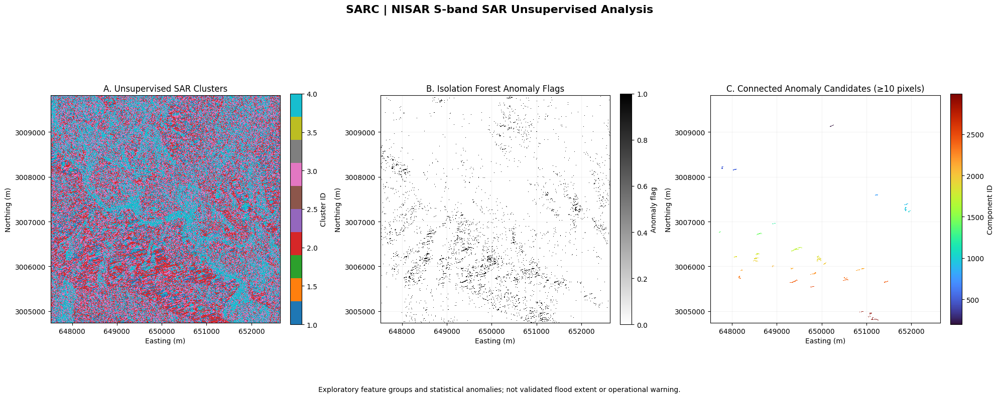


SARC — FINAL NISAR RESEARCH EXPORT COMPLETE
Valid pixels: 260,096
Clusters: 4
Anomaly pixels: 5,202
Anomaly rate: 2.00%
Connected components: 3,049
Components >=10 pixels: 36

FINAL OUTPUTS
PNG: /content/drive/MyDrive/SARC/outputs/maps/nisar/ml_analysis/SARC_NISAR_Final_Research_Map.png
PDF: /content/drive/MyDrive/SARC/outputs/maps/nisar/ml_analysis/SARC_NISAR_Final_Research_Map.pdf
JSON: /content/drive/MyDrive/SARC/metadata/SARC_NISAR_Final_Research_Summary.json

Integrated QA: PASSED


In [ ]:

# ================================================================
# SARC — CELL 22: FINAL NISAR RESEARCH MAP & SUMMARY
# ================================================================

import os
import json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from scipy import ndimage
from datetime import datetime, timezone

BASE = "/content/drive/MyDrive/SARC"

RESULT_DIR = f"{BASE}/processed/nisar/ml_results"
MAP_DIR = f"{BASE}/outputs/maps/nisar/ml_analysis"
META_DIR = f"{BASE}/metadata"

os.makedirs(MAP_DIR, exist_ok=True)

# ------------------------------------------------
# 1. LOAD EXISTING RESEARCH OUTPUTS
# ------------------------------------------------

paths = {
    "clusters": f"{RESULT_DIR}/SARC_NISAR_KMeans_Clusters.tif",
    "anomalies": f"{RESULT_DIR}/SARC_NISAR_IsolationForest_Anomalies.tif",
    "scores": f"{RESULT_DIR}/SARC_NISAR_Anomaly_Scores.tif",
    "inventory": f"{RESULT_DIR}/SARC_Anomaly_Component_Inventory.csv",
    "coherence": f"{RESULT_DIR}/SARC_Spatial_Coherence_Analysis.csv",
    "separation": f"{RESULT_DIR}/SARC_Cluster_Feature_Separation.csv"
}

missing = [name for name, path in paths.items() if not os.path.isfile(path)]

if missing:
    raise FileNotFoundError(f"Required outputs missing: {missing}")

with rasterio.open(paths["clusters"]) as src:
    clusters = src.read(1)
    transform = src.transform
    bounds = src.bounds
    crs = src.crs
    height, width = src.height, src.width
    resolution = (abs(src.transform.a), abs(src.transform.e))

with rasterio.open(paths["anomalies"]) as src:
    anomalies = src.read(1)

with rasterio.open(paths["scores"]) as src:
    scores = src.read(1)

inventory = pd.read_csv(paths["inventory"])
coherence = pd.read_csv(paths["coherence"])
separation = pd.read_csv(paths["separation"])

# ------------------------------------------------
# 2. INPUT QA
# ------------------------------------------------

if not (clusters.shape == anomalies.shape == scores.shape):
    raise RuntimeError("Input raster dimensions do not match.")

if crs is None or crs.to_epsg() != 32645:
    raise RuntimeError(f"Unexpected CRS: {crs}")

valid = clusters > 0
anomaly_mask = (anomalies == 1) & valid

if int(anomaly_mask.sum()) != 5202:
    print("Notice: anomaly count differs from previous checkpoint.")

# Recreate candidate components using same 8-connectivity
labels, component_count = ndimage.label(
    anomaly_mask,
    structure=np.ones((3, 3), dtype=np.uint8)
)

component_sizes = np.bincount(labels.ravel())
candidate_ids = np.where(component_sizes >= 10)[0]
candidate_ids = candidate_ids[candidate_ids > 0]

candidate_mask = np.isin(labels, candidate_ids)

if len(candidate_ids) != len(inventory[inventory["inventory_candidate"]]):
    raise RuntimeError("Candidate inventory and raster component counts differ.")

# ------------------------------------------------
# 3. CREATE FINAL 3-PANEL RESEARCH MAP
# ------------------------------------------------

extent = [
    bounds.left, bounds.right,
    bounds.bottom, bounds.top
]

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

# Panel A — K-Means clusters
cluster_plot = np.ma.masked_where(clusters <= 0, clusters)

im0 = axes[0].imshow(
    cluster_plot,
    extent=extent,
    origin="upper",
    interpolation="nearest",
    cmap="tab10"
)

axes[0].set_title("A. Unsupervised SAR Clusters")
axes[0].set_xlabel("Easting (m)")
axes[0].set_ylabel("Northing (m)")

cbar0 = fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
cbar0.set_label("Cluster ID")

# Panel B — Isolation Forest anomalies
im1 = axes[1].imshow(
    np.ma.masked_where(~valid, anomalies),
    extent=extent,
    origin="upper",
    interpolation="nearest",
    cmap="gray_r",
    vmin=0,
    vmax=1
)

axes[1].set_title("B. Isolation Forest Anomaly Flags")
axes[1].set_xlabel("Easting (m)")
axes[1].set_ylabel("Northing (m)")

cbar1 = fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
cbar1.set_label("Anomaly flag")

# Panel C — Connected anomaly candidates
im2 = axes[2].imshow(
    np.ma.masked_where(~candidate_mask, labels),
    extent=extent,
    origin="upper",
    interpolation="nearest",
    cmap="turbo"
)

axes[2].set_title("C. Connected Anomaly Candidates (≥10 pixels)")
axes[2].set_xlabel("Easting (m)")
axes[2].set_ylabel("Northing (m)")

cbar2 = fig.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)
cbar2.set_label("Component ID")

for ax in axes:
    ax.ticklabel_format(style="plain", axis="both", useOffset=False)
    ax.grid(alpha=0.15)

fig.suptitle(
    "SARC | NISAR S-band SAR Unsupervised Analysis",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.5, 0.015,
    "Exploratory feature groups and statistical anomalies; "
    "not validated flood extent or operational warning.",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.045, 1, 0.94])

png_path = f"{MAP_DIR}/SARC_NISAR_Final_Research_Map.png"
pdf_path = f"{MAP_DIR}/SARC_NISAR_Final_Research_Map.pdf"

plt.savefig(png_path, dpi=300, bbox_inches="tight")
plt.savefig(pdf_path, format="pdf", bbox_inches="tight")
plt.show()
plt.close()

# ------------------------------------------------
# 4. CONSOLIDATED RESEARCH SUMMARY
# ------------------------------------------------

cluster_counts = {
    str(int(cid)): int(np.count_nonzero(clusters == cid))
    for cid in np.unique(clusters[valid])
}

total_valid = int(valid.sum())
total_anomalies = int(anomaly_mask.sum())

candidate_inventory = inventory[
    inventory["inventory_candidate"] == True
].copy()

top_features = separation.head(10).to_dict(orient="records")

summary = {
    "project": "SARC",
    "analysis": "NISAR S-band GCOV Unsupervised SAR Analysis",
    "generated_utc": datetime.now(timezone.utc).isoformat(),

    "dataset": {
        "scene_dates": [
            "2026-08-24",
            "2026-09-05",
            "2026-09-29"
        ],
        "product": "NISAR S-band GCOV",
        "polarizations": ["HH", "HV"],
        "track": 170,
        "frame": 15,
        "orbit": "Ascending",
        "crs": str(crs),
        "resolution_m": list(resolution),
        "raster_dimensions": [int(height), int(width)],
        "valid_pixels": total_valid,
        "aoi_bounds_projected": {
            "left": float(bounds.left),
            "bottom": float(bounds.bottom),
            "right": float(bounds.right),
            "top": float(bounds.top)
        }
    },

    "machine_learning": {
        "feature_count": 30,
        "algorithm_clustering": "MiniBatchKMeans",
        "cluster_count": len(cluster_counts),
        "cluster_pixel_counts": cluster_counts,
        "algorithm_anomaly_detection": "IsolationForest",
        "anomaly_pixels": total_anomalies,
        "anomaly_percentage": float(
            total_anomalies / total_valid * 100
        ),
        "configured_contamination": 0.02
    },

    "spatial_analysis": {
        "connectivity": "8-neighbour",
        "connected_components": int(component_count),
        "components_at_least_10_pixels": int(len(candidate_ids)),
        "candidate_pixels": int(candidate_mask.sum()),
        "candidate_area_m2": float(candidate_mask.sum() * 100),
        "candidate_area_hectares": float(candidate_mask.sum() * 100 / 10000)
    },

    "top_cluster_separating_features": top_features,

    "interpretation_limits": [
        "Cluster IDs represent exploratory feature groups, not land-cover or flood classes.",
        "Isolation Forest flags are statistical anomalies, not confirmed flood detections.",
        "The 2 percent contamination setting is analyst-selected, not observed event prevalence.",
        "The 2026 NISAR observations are not pre-event or immediate post-event observations of the 2023 South Lhonak GLOF.",
        "Independent reference data and validation are required before event-level conclusions."
    ],

    "outputs": [
        os.path.basename(png_path),
        os.path.basename(pdf_path)
    ]
}

summary_path = f"{META_DIR}/SARC_NISAR_Final_Research_Summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2)

# ------------------------------------------------
# 5. INTEGRATED OUTPUT QA
# ------------------------------------------------

for path in [png_path, pdf_path, summary_path]:
    if not os.path.isfile(path) or os.path.getsize(path) == 0:
        raise RuntimeError(f"Output missing or empty: {path}")

with open(summary_path) as f:
    check_summary = json.load(f)

if check_summary["machine_learning"]["feature_count"] != 30:
    raise RuntimeError("Summary feature count QA failed.")

if check_summary["spatial_analysis"]["components_at_least_10_pixels"] != len(candidate_ids):
    raise RuntimeError("Summary component count QA failed.")

print("\n" + "=" * 70)
print("SARC — FINAL NISAR RESEARCH EXPORT COMPLETE")
print("=" * 70)
print(f"Valid pixels: {total_valid:,}")
print(f"Clusters: {len(cluster_counts)}")
print(f"Anomaly pixels: {total_anomalies:,}")
print(f"Anomaly rate: {total_anomalies / total_valid * 100:.2f}%")
print(f"Connected components: {component_count:,}")
print(f"Components >=10 pixels: {len(candidate_ids)}")
print("\nFINAL OUTPUTS")
print("PNG:", png_path)
print("PDF:", pdf_path)
print("JSON:", summary_path)
print("\nIntegrated QA: PASSED")
print("=" * 70)
